# Gruppentheorie

Das Notebook stellt die wichtigsten Gruppen vor (zyklische, Dieder-, symmetrische und alternierende Gruppen, Quaternionen, Matrixgruppen, die 26 sporadischen Gruppen bis zum Monster) und rechnet die Kernaussagen der Gruppentheorie mit numpy, sympy und networkx nach. Dazu gehören Verknüpfungstafeln, Invarianten kleiner Gruppen, Anzahlen von Gruppen, der Untergruppenverband von S₄, das Zählen mit Burnside, Zyklen zufälliger Permutationen, der Zauberwürfel, Einheitengruppen, einfache Gruppen, Mathieu-Gruppen mit dem Golay-Code und Moonshine. Als Anwendungen kommen Punktgruppen von Molekülen, Kristallsymmetrien, die Pauli- und Clifford-Gruppe der Quanteninformation und zufällige Drehungen in der Lie-Gruppe SO(3) hinzu.

Was haben alle Symmetrien gemeinsam, aus welchen Bausteinen sind endliche Gruppen zusammengesetzt, und wozu braucht man sie in Chemie, Physik und Informatik?

#### **Hintergrund**

Eine **Gruppe** ist die Mathematik der Symmetrie. Wann immer man etwas umformen kann, ohne dass sich das Wesentliche ändert (ein Molekül drehen, einen Kristall verschieben, Teilchen vertauschen, einen Zauberwürfel verdrehen, ein Qubit mit einem Gatter bearbeiten), bilden diese Umformungen eine Gruppe: Man kann sie hintereinander ausführen, rückgängig machen, und „nichts tun“ ist auch eine. Aus diesen drei Eigenschaften allein folgt erstaunlich viel, etwa dass die Zahl der Elemente einer Untergruppe die Zahl der Elemente der Gruppe teilt, oder wie viele verschiedene Moleküle es zu einer Summenformel gibt.

Die Gruppentheorie entstand aus der Frage, warum es für Gleichungen fünften Grades keine Lösungsformel gibt: Évariste Galois ordnete um 1830 jeder Gleichung eine Gruppe von Vertauschungen ihrer Lösungen zu und zeigte, dass die Gleichung genau dann mit Wurzeln lösbar ist, wenn diese Gruppe „auflösbar“ ist. Cayley definierte 1854 abstrakte Gruppen, Jordan, Sylow und Frobenius entwickelten die Theorie der endlichen Gruppen, Klein (Erlanger Programm 1872) und Lie (kontinuierliche Gruppen) verbanden sie mit der Geometrie. Im 20. Jahrhundert wurde sie zur Sprache der Physik: Emmy Noether zeigte 1918, dass jede kontinuierliche Symmetrie eine Erhaltungsgröße liefert (Verschiebung in der Zeit → Energie, Drehung → Drehimpuls), Wigner und Weyl machten sie zum Werkzeug der Quantenmechanik, und das Standardmodell der Teilchenphysik ist um die Gruppe $SU(3)\times SU(2)\times U(1)$ gebaut. Der Höhepunkt der endlichen Theorie ist die **Klassifikation der endlichen einfachen Gruppen** (abgeschlossen in den 1980er Jahren, Lücken geschlossen 2004), eines der größten Beweisprojekte der Mathematik.

Heute begegnet man Gruppen in der Chemie (Punktgruppen bestimmen Spektren, Chiralität und Isomerenzahlen), in der Kristallographie (230 Raumgruppen), in der Kryptographie (RSA, Diffie-Hellman und elliptische Kurven rechnen in Gruppen), in fehlerkorrigierenden Codes, in der Quanteninformation (Pauli- und Clifford-Gruppe, Stabilisatorcodes, Shors Algorithmus), in der Robotik (die Gruppe der Bewegungen $SE(3)$) und im maschinellen Lernen: Faltungsnetze sind verschiebungsäquivariant, und **äquivariante neuronale Netze** bauen Drehungen, Spiegelungen oder Permutationen direkt in die Architektur ein (geometric deep learning; AlphaFold, Netze für Moleküle und Graphen).

Bibliotheken: Für dieses Notebook genügen numpy (Matrixgruppen), **sympy.combinatorics** (Permutationsgruppen mit dem Schreier-Sims-Algorithmus, der die Ordnung riesiger Gruppen aus wenigen Erzeugern berechnet) und networkx (Graphen). Die Werkzeuge der Forschung sind **GAP** (mit der SmallGroups-Bibliothek aller Gruppen bis Ordnung 2000 außer 1024, und dem ATLAS der endlichen Gruppen), Magma und SageMath; in der Chemie bestimmen Pakete wie pymatgen oder spglib Punkt- und Raumgruppen.

Landkarte:

- **Grundlagen**
  - Verknüpfungstafeln (Exp. 1): Jede Gruppe ist durch ihre Tafel bestimmt; abelsche Gruppen haben symmetrische Tafeln.
  - Kleine Gruppen unterscheiden (Exp. 2): Elementordnungen, Zentrum und Kommutatoruntergruppe trennen die fünf Gruppen der Ordnung 8 und die fünf der Ordnung 12.
  - Wie viele Gruppen gibt es? (Exp. 3): Eine Gruppe der Ordnung $p$, zwei der Ordnung $p^2$, aber 49 Milliarden der Ordnung 1024.
  - Untergruppen und Normalteiler (Exp. 4): Lagrange, der Verband der 30 Untergruppen von $S_4$, und warum $A_4$ keine Untergruppe der Ordnung 6 hat.
  - Gruppenoperationen (Exp. 5): Burnside zählt Muster bis auf Symmetrie, etwa die Isomere der Chlorbenzole.
- **Wichtige Familien und Beispiele**
  - Symmetrische Gruppe (Exp. 6): Zyklen, Vorzeichen, zufällige Permutationen, das 15-Puzzle.
  - Zauberwürfel (Exp. 7): eine Permutationsgruppe mit $4.3\cdot10^{19}$ Elementen.
  - Abelsche Gruppen (Exp. 8): die Einheitengruppe modulo $n$, Primitivwurzeln und Kryptographie.
- **Die Bausteine: einfache Gruppen**
  - Einfache Gruppen (Exp. 9): Kompositionsreihen, auflösbare Gruppen, alle nichtabelschen einfachen Gruppen unter 30 000.
  - Sporadische Gruppen (Exp. 10): die 26 Ausnahmen, die Mathieu-Gruppen und der Golay-Code.
  - Monster und Moonshine (Exp. 11): die Koeffizienten der $j$-Funktion sind Summen von Darstellungsdimensionen des Monsters.
- **Anwendungen**
  - Punktgruppen von Molekülen (Exp. 12): von $H_2O$ ($C_{2v}$) bis $C_{60}$ ($I_h$, 120 Symmetrien).
  - Kristalle (Exp. 13): nur 2-, 3-, 4- und 6-zählige Drehungen sind mit einem Gitter verträglich; Tapetengruppen.
  - Quanteninformation (Exp. 14): Pauli- und Clifford-Gruppe; die 24 Clifford-Operationen sind die Drehungen des Oktaeders.
  - Lie-Gruppen (Exp. 15): zufällige Drehungen in $SO(3)$ und die doppelte Überlagerung durch $SU(2)$.

Verwandte Notebooks: Die Fourier-Analyse auf endlichen Gruppen und Shors Periodenfindung stehen in [Harmonische Analysis und Fourier-Analyse](https://github.com/deltorobarba/science/blob/main/maths/fourieranalysis.ipynb), Eigenwerte von Permutations- und Drehmatrizen in [Eigenwerte und Eigenvektoren](https://github.com/deltorobarba/science/blob/main/maths/eigenvalues.ipynb), elliptische Kurven als Gruppen in [Quadriken und elliptische Kurven](https://github.com/deltorobarba/science/blob/main/maths/quadrics_ellipticcurves.ipynb), projektive Gruppen in [Projektive Geometrie](https://github.com/deltorobarba/science/blob/main/maths/projectivegeometry.ipynb) und die Heisenberg-Gruppe in der Notiz [Heisenberg-Weyl Algebra](https://github.com/deltorobarba/science/blob/main/quantum/heisenbergweyl.md).

#### **Theorie**

Hier steht das Allgemeine und der Katalog der wichtigsten Gruppen; die Theorie zu jedem einzelnen Thema steht in seinem Experiment, direkt nach den Fachbegriffen.

##### *1. Was ist eine Gruppe?*

Eine **Gruppe** ist eine Menge $G$ mit einer Verknüpfung $a\cdot b$, für die gilt:
- **Abgeschlossenheit:** $a\cdot b$ liegt wieder in $G$.
- **Assoziativität:** $(a\cdot b)\cdot c = a\cdot(b\cdot c)$; Klammern dürfen weggelassen werden.
- **Neutrales Element** $e$ (oder 1): $e\cdot a = a\cdot e = a$.
- **Inverse:** Zu jedem $a$ gibt es $a^{-1}$ mit $a\cdot a^{-1} = a^{-1}\cdot a = e$.

Die Reihenfolge darf zählen: Erst um die senkrechte, dann um die waagerechte Achse drehen ist etwas anderes als umgekehrt. Gilt immer $a\cdot b = b\cdot a$, heißt die Gruppe **abelsch** (kommutativ). Weitere Begriffe:
- **Ordnung der Gruppe** $\vert G\vert$: die Zahl ihrer Elemente (endlich oder unendlich). **Ordnung eines Elements** $a$: das kleinste $k\geq1$ mit $a^k = e$.
- **Erzeuger:** Elemente, aus denen sich durch Verknüpfen alle anderen ergeben. Eine **zyklische** Gruppe hat einen einzigen Erzeuger, $G = \lbrace e, a, a^2, \dots\rbrace$.
- **Verknüpfungstafel** (Cayley-Tafel): die Tabelle aller Produkte; jede Zeile und jede Spalte enthält jedes Element genau einmal (**lateinisches Quadrat**).
- **Homomorphismus:** eine Abbildung $f: G\to H$ mit $f(a\cdot b) = f(a)\cdot f(b)$; sie respektiert die Struktur. Ein bijektiver Homomorphismus ist ein **Isomorphismus**, $G\cong H$: Die beiden Gruppen sind „dieselbe Gruppe in anderer Verkleidung“, etwa die Drehungen eines gleichseitigen Dreiecks und die Vertauschungen von drei Dingen.
- **Kern** $\ker f = \lbrace a: f(a) = e\rbrace$ und **Bild** $f(G)$.

Beispiele: die ganzen Zahlen mit $+$ (unendlich, zyklisch, Erzeuger 1), die Reste modulo $n$ mit $+$ ($\mathbb Z_n$), die invertierbaren Matrizen mit der Matrixmultiplikation, die Permutationen einer Menge mit dem Hintereinanderausführen, die Symmetrien eines Körpers.

##### *2. Untergruppen, Normalteiler und Faktorgruppen*

- **Untergruppe** $H\leq G$: eine Teilmenge, die selbst eine Gruppe ist. **Nebenklasse** $aH = \lbrace a\cdot h: h\in H\rbrace$; die Nebenklassen zerlegen $G$ in gleich große Stücke.
- **Satz von Lagrange:** $\vert H\vert$ teilt $\vert G\vert$; der **Index** $[G:H] = \vert G\vert/\vert H\vert$ ist die Zahl der Nebenklassen. Folge: Die Ordnung jedes Elements teilt $\vert G\vert$, und jede Gruppe von Primzahlordnung ist zyklisch.
- **Konjugation:** $b\mapsto aba^{-1}$, „$b$ aus der Sicht von $a$“; die **Konjugationsklassen** zerlegen $G$. In Drehgruppen sind Drehungen um denselben Winkel um gleichwertige Achsen konjugiert.
- **Normalteiler** $N\trianglelefteq G$: eine Untergruppe mit $aNa^{-1} = N$ für alle $a$. Genau dann bilden die Nebenklassen selbst eine Gruppe, die **Faktorgruppe** $G/N$ („$G$, wobei man Unterschiede innerhalb von $N$ vergisst“). Kerne von Homomorphismen sind immer Normalteiler, und $G/\ker f\cong f(G)$ (**Homomorphiesatz**).
- **Zentrum** $Z(G)$: die Elemente, die mit allen vertauschen. **Kommutator** $[a, b] = aba^{-1}b^{-1}$; die von allen Kommutatoren erzeugte **Kommutatoruntergruppe** $[G, G]$ misst, wie weit $G$ von abelsch entfernt ist ($G/[G, G]$ ist abelsch).
- **Produkte:** Das **direkte Produkt** $G\times H$ hat Paare als Elemente und verknüpft komponentenweise. Beim **semidirekten Produkt** $N\rtimes H$ wirkt $H$ zusätzlich auf $N$; so entsteht etwa die Diedergruppe $D_n = \mathbb Z_n\rtimes\mathbb Z_2$ (Spiegeln kehrt die Drehrichtung um).

##### *3. Gruppen, die auf etwas wirken*

Eine **Gruppenoperation** ordnet jedem Gruppenelement eine Umformung einer Menge $X$ zu, verträglich mit der Verknüpfung (Drehungen bewegen Punkte, Permutationen vertauschen Plätze).
- **Bahn** von $x$: alle Punkte $g\cdot x$, die man von $x$ aus erreicht. **Stabilisator** $G_x$: alle $g$ mit $g\cdot x = x$.
- **Bahn-Stabilisator-Satz:** $\vert G\cdot x\vert\cdot\vert G_x\vert = \vert G\vert$.
- **Lemma von Burnside:** Die Zahl der Bahnen ist der Mittelwert der Zahl der Fixpunkte, $\frac1{\vert G\vert}\sum_g\vert\mathrm{Fix}(g)\vert$ (Exp. 5).
- **Satz von Cayley:** Jede Gruppe wirkt durch Linksmultiplikation auf sich selbst; deshalb ist jede endliche Gruppe eine Untergruppe einer symmetrischen Gruppe $S_n$.
- **Sylow-Sätze:** Ist $p^k$ die höchste Potenz der Primzahl $p$, die $\vert G\vert$ teilt, so hat $G$ Untergruppen der Ordnung $p^k$ (**Sylow-Untergruppen**); sie sind alle konjugiert, und ihre Anzahl teilt $\vert G\vert/p^k$ und lässt den Rest 1 bei Division durch $p$. Das ist das wichtigste Werkzeug, um Gruppen einer gegebenen Ordnung zu bestimmen.

##### *4. Katalog wichtiger Gruppen*

| Name | Symbol | Ordnung | Was sie ist | Wo sie vorkommt |
| --- | --- | --- | --- | --- |
| zyklische Gruppe | $\mathbb Z_n$ (auch $C_n$) | $n$ | Drehungen eines regelmäßigen $n$-Ecks; Addition modulo $n$ | Uhren, Prüfziffern, Drehachsen $C_n$ in Molekülen |
| unendliche zyklische Gruppe (ganze Zahlen) | $\mathbb Z$ | $\infty$ | ganze Zahlen mit $+$ | Verschiebungen eines Gitters |
| Kleinsche Vierergruppe | $V_4 = \mathbb Z_2\times\mathbb Z_2$ | 4 | Symmetrien eines Rechtecks | Punktgruppe $C_{2v}$ von Wasser, Pauli-Gruppe ohne Phasen |
| Diedergruppe | $D_n$ | $2n$ | Drehungen und Spiegelungen eines regelmäßigen $n$-Ecks | Moleküle ($C_{nv}$, $D_{nh}$), Benzol |
| symmetrische Gruppe | $S_n$ | $n!$ | alle Permutationen von $n$ Dingen | identische Teilchen, Galois-Theorie, Sortieren |
| alternierende Gruppe | $A_n$ | $n!/2$ | die geraden Permutationen | 15-Puzzle; $A_4$ = Tetraedergruppe, $A_5$ = Ikosaedergruppe |
| Quaternionengruppe | $Q_8$ | 8 | $\pm1, \pm i, \pm j, \pm k$ mit $i^2 = j^2 = k^2 = ijk = -1$ | Drehungen im Raum, Pauli-Matrizen |
| prime Restklassengruppe (Einheitengruppe modulo $n$) | $(\mathbb Z/n\mathbb Z)^\times$ | $\varphi(n)$ | die zu $n$ teilerfremden Reste mit Multiplikation | RSA, Diffie-Hellman |
| Würfelgruppe (Rubik-Gruppe) | – | $4.3\cdot10^{19}$ | Zustände des Zauberwürfels | Puzzles, Algorithmen |
| allgemeine lineare Gruppe und projektive spezielle lineare Gruppe | $GL(n, q)$, $PSL(n, q)$ | endlich | invertierbare Matrizen über einem endlichen Körper (bei $PSL$: Determinante 1, ohne Skalare) | Codes, Kryptographie; $PSL(2,7)$ = Symmetrien der Fano-Ebene (Kleinsche Gruppe der Ordnung 168) |
| Pauli-Gruppe und Clifford-Gruppe | $\mathcal P_n$, $\mathcal C_n$ | 16 und 24 (1 Qubit, ohne Phase) | Fehler und leicht simulierbare Gatter eines Qubits | Quantenfehlerkorrektur, Stabilisatorzustände |
| Zopfgruppe (Artinsche Zopfgruppe) | $B_n$ | $\infty$ | Verflechtungen von $n$ Fäden | Anyonen, topologische Quantenrechner, Knotentheorie |
| Modulgruppe | $SL(2, \mathbb Z)$ | $\infty$ | ganzzahlige $2\times2$-Matrizen mit Determinante 1 | Modulformen, Moonshine, Gitter |
| freie Gruppe | $F_2$ | $\infty$ | Wörter in zwei Buchstaben ohne Relationen | Banach-Tarski-Paradoxon, Topologie |
| Kreisgruppe (unitäre Gruppe $U(1)$) und spezielle orthogonale Gruppe $SO(2)$ | $U(1)\cong SO(2)$ | Kreis | Phasen $e^{i\theta}$, Drehungen der Ebene | Elektromagnetismus, Phase einer Wellenfunktion |
| Drehgruppe (spezielle orthogonale Gruppe) und spezielle unitäre Gruppe | $SO(3)$, $SU(2)$ | 3 Parameter | Drehungen im Raum; Spin | Drehimpuls, Ein-Qubit-Gatter |
| spezielle unitäre Gruppe vom Grad 3 | $SU(3)$ | 8 Parameter | unitäre $3\times3$-Matrizen mit Determinante 1 | Farbladung der Quarks (starke Wechselwirkung) |
| Lorentz-Gruppe und Poincaré-Gruppe | $O(1, 3)$, $\mathbb R^{1,3}\rtimes O(1, 3)$ | 6 bzw. 10 Parameter | Symmetrien der Raumzeit | spezielle Relativitätstheorie |
| spezielle euklidische Gruppe (Gruppe der starren Bewegungen) | $SE(3)$ | 6 Parameter | Drehungen und Verschiebungen | Robotik, Computer Vision, Proteinstrukturen |
| Heisenberg-Gruppe | $H_3(\mathbb R)$ | 3 Parameter | erzeugt von Ort und Impuls, $[x, p] = i\hbar$ | Quantenmechanik, Quantenoptik |

**Kleine Gruppen** (bis auf Isomorphie; $D_n$ hat hier $2n$ Elemente):

| Ordnung | Gruppen mit Namen | Anzahl |
| --- | --- | --- |
| 1 | triviale Gruppe | 1 |
| 2, 3, 5, 7, 11, 13 | zyklische Gruppe $\mathbb Z_p$ | 1 |
| 4 | zyklische Gruppe $\mathbb Z_4$, Kleinsche Vierergruppe $V_4 = \mathbb Z_2^2$ | 2 |
| 6 | zyklische Gruppe $\mathbb Z_6$, symmetrische Gruppe $S_3$ = Diedergruppe $D_3$ (Symmetrien des Dreiecks) | 2 |
| 8 | zyklische Gruppe $\mathbb Z_8$, $\mathbb Z_4\times\mathbb Z_2$, elementar-abelsche Gruppe $\mathbb Z_2^3$, Diedergruppe $D_4$ (Symmetrien des Quadrats), Quaternionengruppe $Q_8$ | 5 |
| 9 | zyklische Gruppe $\mathbb Z_9$, elementar-abelsche Gruppe $\mathbb Z_3^2$ | 2 |
| 10 | zyklische Gruppe $\mathbb Z_{10}$, Diedergruppe $D_5$ (Symmetrien des Fünfecks) | 2 |
| 12 | zyklische Gruppe $\mathbb Z_{12}$, $\mathbb Z_6\times\mathbb Z_2$, alternierende Gruppe $A_4$ (Tetraedergruppe), Diedergruppe $D_6$ (Symmetrien des Sechsecks), dizyklische Gruppe $\mathrm{Dic}_3 = \mathbb Z_3\rtimes\mathbb Z_4$ | 5 |
| 14 | zyklische Gruppe $\mathbb Z_{14}$, Diedergruppe $D_7$ | 2 |
| 15 | zyklische Gruppe $\mathbb Z_{15}$ (jede Gruppe der Ordnung 15 ist zyklisch) | 1 |
| 16 | 5 abelsche: $\mathbb Z_{16}$, $\mathbb Z_8\times\mathbb Z_2$, $\mathbb Z_4^2$, $\mathbb Z_4\times\mathbb Z_2^2$, elementar-abelsche Gruppe $\mathbb Z_2^4$; 9 nichtabelsche: Diedergruppe $D_8$, verallgemeinerte Quaternionengruppe $Q_{16}$, semidiedrische (quasidiedrische) Gruppe $SD_{16}$, modulare Gruppe $M_{16}$, $D_4\times\mathbb Z_2$, $Q_8\times\mathbb Z_2$, Pauli-Gruppe eines Qubits (zentrales Produkt $\mathbb Z_4\circ D_4$), $\mathbb Z_4\rtimes\mathbb Z_4$ und $\mathbb Z_2^2\rtimes\mathbb Z_4$ | 14 |

##### *5. Die Klassifikation der endlichen einfachen Gruppen*

Eine Gruppe heißt **einfach**, wenn sie außer $\lbrace e\rbrace$ und sich selbst keine Normalteiler hat. Nach dem **Satz von Jordan-Hölder** lässt sich jede endliche Gruppe schrittweise in einfache Faktoren zerlegen, und diese Faktoren sind bis auf die Reihenfolge eindeutig. Einfache Gruppen sind also die „Atome“ oder „Primzahlen“ der Gruppentheorie (Exp. 9). Der Klassifikationssatz besagt: Jede endliche einfache Gruppe gehört zu genau einer dieser vier Kategorien.

| Kategorie | Beschreibung | Beispiele mit Namen |
| --- | --- | --- |
| 1. Zyklische Gruppen $\mathbb Z_p$, $p$ prim | die einzigen abelschen einfachen Gruppen; etwa die Drehungen eines regelmäßigen $p$-Ecks (ein Vieleck mit nicht primer Eckenzahl gibt keine einfache Gruppe) | $\mathbb Z_2$, $\mathbb Z_3$, $\mathbb Z_5$, … |
| 2. Alternierende Gruppen $A_n$, $n\geq5$ | die geraden Permutationen von $n$ Dingen; im Zauberwürfel stecken $A_8$ (Ecken) und $A_{12}$ (Kanten) als Bausteine, die Würfelgruppe selbst ist aber nicht einfach (Exp. 7) | $A_5$ (Ikosaedergruppe, 60 Elemente, die kleinste nichtabelsche einfache Gruppe), $A_6$, $A_7$, … |
| 3. Gruppen vom Lie-Typ | Matrixgruppen über endlichen Körpern, die endlichen Gegenstücke der Lie-Gruppen; 16 unendliche Familien (Tabelle unten) | Chevalley-, Steinberg-, Suzuki- und Ree-Gruppen, etwa $PSL(2,7)$ (168 Elemente) |
| 4. Sporadische Gruppen | 26 Ausnahmen, die in keine unendliche Familie passen (Abschnitt 6); die Tits-Gruppe ${}^2F_4(2)'$ wird manchmal als 27. gezählt | Mathieu-, Janko-, Conway- und Fischer-Gruppen, das Babymonster und das Monster mit etwa $8\cdot10^{53}$ Elementen |

Die 16 Familien vom Lie-Typ (die Buchstaben sind dieselben wie bei den einfachen Lie-Algebren):

| Familie | Name | Art |
| --- | --- | --- |
| $A_n(q) = PSL(n + 1, q)$ | projektive spezielle lineare Gruppe | klassische Chevalley-Gruppe |
| $B_n(q) = \Omega(2n + 1, q)$ | orthogonale Gruppe in ungerader Dimension | klassische Chevalley-Gruppe |
| $C_n(q) = PSp(2n, q)$ | projektive symplektische Gruppe | klassische Chevalley-Gruppe |
| $D_n(q) = P\Omega^+(2n, q)$ | orthogonale Gruppe in gerader Dimension (Plus-Typ) | klassische Chevalley-Gruppe |
| $E_6(q)$, $E_7(q)$, $E_8(q)$, $F_4(q)$, $G_2(q)$ | exzeptionelle Chevalley-Gruppen (5 Familien) | Chevalley 1955 |
| ${}^2A_n(q^2) = PSU(n + 1, q)$ | projektive spezielle unitäre Gruppe | getwistete (Steinberg-)Gruppe |
| ${}^2D_n(q^2) = P\Omega^-(2n, q)$ | orthogonale Gruppe in gerader Dimension (Minus-Typ) | Steinberg-Gruppe |
| ${}^2E_6(q^2)$ | getwistete $E_6$-Gruppe | Steinberg-Gruppe |
| ${}^3D_4(q^3)$ | Triality-getwistete $D_4$-Gruppe | Steinberg-Gruppe |
| ${}^2B_2(2^{2n+1}) = Sz(2^{2n+1})$ | Suzuki-Gruppen | Suzuki 1960 |
| ${}^2F_4(2^{2n+1})$ | große Ree-Gruppen | Ree 1961 |
| ${}^2G_2(3^{2n+1})$ | kleine Ree-Gruppen | Ree 1960 |

Der Beweis zog sich über Jahrzehnte: Feit und Thompson zeigten 1963 auf 255 Seiten, dass jede Gruppe ungerader Ordnung auflösbar ist; Gorenstein organisierte ab 1972 das Programm, um 1983 galt es als abgeschlossen, eine Lücke (die „quasidünnen“ Gruppen) schlossen Aschbacher und Smith 2004 auf über 1200 Seiten. Insgesamt umfasst der Beweis Zehntausende Seiten in Hunderten Arbeiten von über hundert Autoren; eine überarbeitete Fassung erscheint seit 1994 als Buchreihe (Gorenstein, Lyons, Solomon).

##### *6. Die 26 sporadischen Gruppen*

| Symbol | Name | Ordnung | Entdeckt | Familie |
| --- | --- | --- | --- | --- |
| $M_{11}$, $M_{12}$ | Mathieu-Gruppen | 7920, 95 040 | Mathieu 1861 | 1. Generation (Mathieu) |
| $M_{22}$, $M_{23}$, $M_{24}$ | Mathieu-Gruppen | $4.4\cdot10^5$, $1.0\cdot10^7$, $2.4\cdot10^8$ | Mathieu 1873 | 1. Generation |
| $J_2$ | Hall-Janko-Gruppe (zweite Janko-Gruppe) | $6.0\cdot10^5$ | Hall, Janko 1968 | 2. Generation (Leech-Gitter) |
| $HS$ | Higman-Sims-Gruppe | $4.4\cdot10^7$ | Higman, Sims 1967 | 2. Generation |
| $McL$ | McLaughlin-Gruppe | $9.0\cdot10^8$ | McLaughlin 1969 | 2. Generation |
| $Suz$ | Suzuki-Gruppe (die sporadische, nicht die Familie $Sz(q)$) | $4.5\cdot10^{11}$ | Suzuki 1969 | 2. Generation |
| $Co_3$, $Co_2$, $Co_1$ | Conway-Gruppen | $5.0\cdot10^{11}$, $4.2\cdot10^{13}$, $4.2\cdot10^{18}$ | Conway 1969 | 2. Generation |
| $He$ | Held-Gruppe | $4.0\cdot10^9$ | Held 1969 | 3. Generation (im Monster) |
| $Fi_{22}$, $Fi_{23}$, $Fi_{24}'$ | Fischer-Gruppen | $6.5\cdot10^{13}$, $4.1\cdot10^{18}$, $1.3\cdot10^{24}$ | Fischer 1971 | 3. Generation |
| $HN$ | Harada-Norton-Gruppe | $2.7\cdot10^{14}$ | Harada, Norton 1976 | 3. Generation |
| $Th$ | Thompson-Gruppe | $9.1\cdot10^{16}$ | Thompson 1976 | 3. Generation |
| $B$ | Babymonster | $4.2\cdot10^{33}$ | Fischer 1973 | 3. Generation |
| $M$ | Monster (Fischer-Griess-Monster, „Friendly Giant“) | $8.1\cdot10^{53}$ | Fischer, Griess 1973 (konstruiert 1982) | 3. Generation |
| $J_1$ | erste Janko-Gruppe | 175 560 | Janko 1965 | Paria |
| $J_3$ | Higman-Janko-McKay-Gruppe (dritte Janko-Gruppe) | $5.0\cdot10^7$ | Janko 1968 | Paria |
| $Ru$ | Rudvalis-Gruppe | $1.5\cdot10^{11}$ | Rudvalis 1972 | Paria |
| $O'N$ | O'Nan-Gruppe | $4.6\cdot10^{11}$ | O'Nan 1976 | Paria |
| $Ly$ | Lyons-Gruppe | $5.2\cdot10^{16}$ | Lyons 1972 | Paria |
| $J_4$ | vierte Janko-Gruppe | $8.7\cdot10^{19}$ | Janko 1976 | Paria |

20 der 26 Gruppen stecken als Faktoren von Untergruppen im Monster (die „glückliche Familie“, Griess); die 6 übrigen heißen **Parias**. Die genauen Ordnungen stehen im Code von Exp. 10.

##### *7. Topologische Gruppen und Lie-Gruppen (kurz)*

- **Topologische Gruppe:** eine Gruppe, die zugleich ein Raum mit einem Abstands- oder Nachbarschaftsbegriff ist, in dem Verknüpfung und Inversion stetig sind; kleine Änderungen der Faktoren ändern das Produkt nur wenig.
- **Lie-Gruppe:** eine topologische Gruppe, die lokal wie ein $\mathbb R^d$ aussieht (eine glatte Mannigfaltigkeit) und deren Operationen differenzierbar sind. $d$ ist ihre **Dimension**, die Zahl der freien Parameter: $SO(3)$ hat 3 (Achse und Winkel), $SU(2)$ hat 3, $SU(3)$ hat 8.
- **Matrixgruppen** sind die wichtigsten Beispiele: $GL(n)$ (invertierbar), $SL(n)$ (Determinante 1), $O(n)$ und $SO(n)$ (erhalten Längen), $U(n)$ und $SU(n)$ (erhalten das komplexe Skalarprodukt), $Sp(2n)$ (erhalten eine symplektische Form, die Struktur der klassischen Mechanik), die Lorentz-Gruppe $O(1, 3)$ (erhält den Abstand in der Raumzeit).
- **Topologische Eigenschaften:** **kompakt** (beschränkt und abgeschlossen: $SO(n)$, $SU(n)$; nicht: die Lorentz-Gruppe, deren Geschwindigkeiten beliebig nahe an $c$ gehen), **zusammenhängend** ($O(3)$ zerfällt in Drehungen und Drehspiegelungen, $SO(3)$ nicht), **einfach zusammenhängend** ($SU(2)$ ja, $SO(3)$ nein: $SU(2)$ überlagert $SO(3)$ doppelt, Exp. 15).
- **Haar-Maß:** Auf jeder kompakten Gruppe gibt es genau eine „gleichmäßige“ Wahrscheinlichkeitsverteilung, die sich unter Multiplikation nicht ändert; mit ihr zieht man zufällige Drehungen oder zufällige unitäre Gatter.
- Jede Lie-Gruppe hat eine **Lie-Algebra** (ihre infinitesimalen Erzeuger, etwa die Drehimpulsoperatoren), und die **Exponentialabbildung** $X\mapsto e^X$ führt von der Algebra in die Gruppe. Dieses Thema gehört zur Darstellungstheorie und wird hier nur benutzt, nicht ausgeführt.

#### **Code**

Werkzeuge für endliche Matrixgruppen: `matrix_group` erzeugt aus wenigen Matrizen alle Elemente der Gruppe (so lange multiplizieren, bis nichts Neues mehr entsteht), `element_order`, `cayley_table` und `invariants` berechnen Elementordnungen, Verknüpfungstafel, Zentrum, Kommutatoruntergruppe und Konjugationsklassen. Für Permutationsgruppen benutzt das Notebook `sympy.combinatorics`; dessen Schreier-Sims-Algorithmus berechnet die Ordnung einer Gruppe aus ihren Erzeugern, ohne alle Elemente aufzuzählen. Weil sympy keine Prüfung auf Einfachheit hat, testet `is_simple` sie über Normalabschlüsse (Theorie in Exp. 9).

In [1]:
# Alles hier (numpy, scipy, sympy, networkx, matplotlib) ist in Colab vorinstalliert
import itertools, time
from math import gcd, factorial
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from scipy import stats
from scipy.spatial.transform import Rotation
from sympy import factorint, totient
from sympy.functions.combinatorial.numbers import partition, reduced_totient
from sympy.combinatorics import Permutation, PermutationGroup
from sympy.combinatorics.named_groups import SymmetricGroup, AlternatingGroup, RubikGroup

def key(M):
    """Gerundeter Schlüssel einer Matrix, damit gleiche Gruppenelemente als gleich erkannt werden."""
    return tuple(np.round(np.asarray(M, dtype=complex).ravel(), 8))

def matrix_group(gens):
    """Alle Elemente der von den Matrizen gens erzeugten endlichen Gruppe (Abschluss unter Multiplikation); das Einselement zuerst."""
    I = np.eye(len(gens[0]), dtype=complex)
    elems, frontier = {key(I): I}, [I]
    while frontier:
        new = []
        for A in frontier:
            for g in gens:
                B = g @ A
                if key(B) not in elems:
                    elems[key(B)] = B
                    new.append(B)
        frontier = new
    return list(elems.values())

def element_order(M):
    I, P, k = np.eye(len(M)), np.array(M, dtype=complex), 1
    while not np.allclose(P, I):
        P, k = P @ M, k + 1
    return k

def cayley_table(elems):
    """Verknüpfungstafel: Eintrag (i, j) ist der Index von elems[i] · elems[j]."""
    index = {key(E): i for i, E in enumerate(elems)}
    return np.array([[index[key(A @ B)] for B in elems] for A in elems])

def invariants(elems):
    """Ordnungsstatistik, Zentrum, Kommutatoruntergruppe und Zahl der Konjugationsklassen einer Matrixgruppe."""
    n = len(elems)
    orders = [element_order(E) for E in elems]
    center = [A for A in elems if all(np.allclose(A @ B, B @ A) for B in elems)]
    comms = [A @ B @ np.linalg.inv(A) @ np.linalg.inv(B) for A in elems for B in elems]
    derived = matrix_group(list({key(C): C for C in comms}.values()))
    classes, seen = 0, set()
    for A in elems:
        if key(A) in seen:
            continue
        classes += 1
        seen |= {key(B @ A @ np.linalg.inv(B)) for B in elems}
    return dict(order=n, orders=orders, center=len(center), derived=len(derived), classes=classes,
                abelian=len(center) == n)

def is_simple(G):
    """Eine Permutationsgruppe ist einfach, wenn der Normalabschluss jedes Elements ≠ 1 schon die ganze Gruppe ist."""
    n = G.order()
    for cls in G.conjugacy_classes():
        g = next(iter(cls))
        if not g.is_Identity and G.normal_closure(PermutationGroup([g])).order() != n:
            return False
    return n > 1

def fmt(n):
    """Ganze Zahl mit Leerzeichen als Tausendertrennzeichen."""
    return f"{int(n):,}".replace(",", " ")

def rot2(angle):
    c, s = np.cos(angle), np.sin(angle)
    return np.array([[c, -s], [s, c]])

print("Werkzeuge bereit: Matrixgruppen, Ordnungen, Verknüpfungstafeln, Invarianten, Einfachheitstest")

Werkzeuge bereit: Matrixgruppen, Ordnungen, Verknüpfungstafeln, Invarianten, Einfachheitstest


#### **Experimente**

##### *1. Verknüpfungstafeln kleiner Gruppen*

Wie sieht eine Gruppe aus, wenn man alle Produkte aufschreibt? Vorher vorhersagen: Woran erkennt man in der Tafel, ob eine Gruppe abelsch ist?

Vier Gruppen werden als Matrixgruppen erzeugt: $\mathbb Z_6$ (Drehungen der Ebene um Vielfache von 60°), $S_3$ (die $3\times3$-Permutationsmatrizen), $D_4$ (Drehungen und Spiegelungen des Quadrats) und $Q_8$ (die Matrizen $\pm1, \pm iX, \pm iY, \pm iZ$ aus den Pauli-Matrizen). Für jede wird die Verknüpfungstafel gezeichnet: Zeile $a$, Spalte $b$, Eintrag = Nummer von $a\cdot b$, gleiche Farben für gleiche Elemente (Element 0 ist immer das neutrale). Die Ausgabe prüft die Gruppenaxiome und listet die Elementordnungen.

**Hintergrund & Fachbegriffe:**
- **Verknüpfungstafel** (Cayley-Tafel): die Tabelle aller Produkte $a\cdot b$.
- **Lateinisches Quadrat:** eine Tabelle, in der jede Zeile und jede Spalte jedes Symbol genau einmal enthält.
- **Abelsch:** $a\cdot b = b\cdot a$ für alle $a, b$.
- **Ordnung eines Elements:** wie oft man es mit sich selbst verknüpfen muss, bis das neutrale Element herauskommt.
- **Pauli-Matrizen** $X, Y, Z$: die $2\times2$-Matrizen der Spin- und Qubit-Operatoren; $iX, iY, iZ$ verhalten sich wie die Quaternionen $i, j, k$.

**Theorie:**

- **Warum ein lateinisches Quadrat:** Aus $a\cdot b = a\cdot c$ folgt durch Multiplikation mit $a^{-1}$ von links $b = c$ (Kürzungsregel). In einer Zeile kann also kein Element zweimal vorkommen, und weil es so viele Spalten wie Elemente gibt, kommt jedes genau einmal vor. Jede Zeile ist eine Permutation der Gruppe; das ist der Satz von Cayley (Theorie, Abschnitt 3).
- **Abelsch heißt symmetrische Tafel:** Eintrag $(a, b)$ ist $a\cdot b$, Eintrag $(b, a)$ ist $b\cdot a$.
- **Gleiche Ordnung, verschiedene Gruppen:** $\mathbb Z_6$ und $S_3$ haben beide 6 Elemente. $\mathbb Z_6$ ist zyklisch, abelsch, und hat ein Element der Ordnung 6; $S_3$ ist nicht abelsch und hat drei Elemente der Ordnung 2 (die Vertauschungen zweier Dinge). Ebenso sind $D_4$ und $Q_8$ beide nichtabelsch mit 8 Elementen, unterscheiden sich aber in den Ordnungen: $D_4$ hat fünf Spiegelungen bzw. Drehungen um 180°, $Q_8$ nur ein Element der Ordnung 2, nämlich $-1$.
- **Quaternionen:** $i^2 = j^2 = k^2 = ijk = -1$; Hamilton ritzte diese Formel 1843 in eine Brücke in Dublin. Sie beschreiben Drehungen im Raum ohne die Singularitäten der Euler-Winkel.

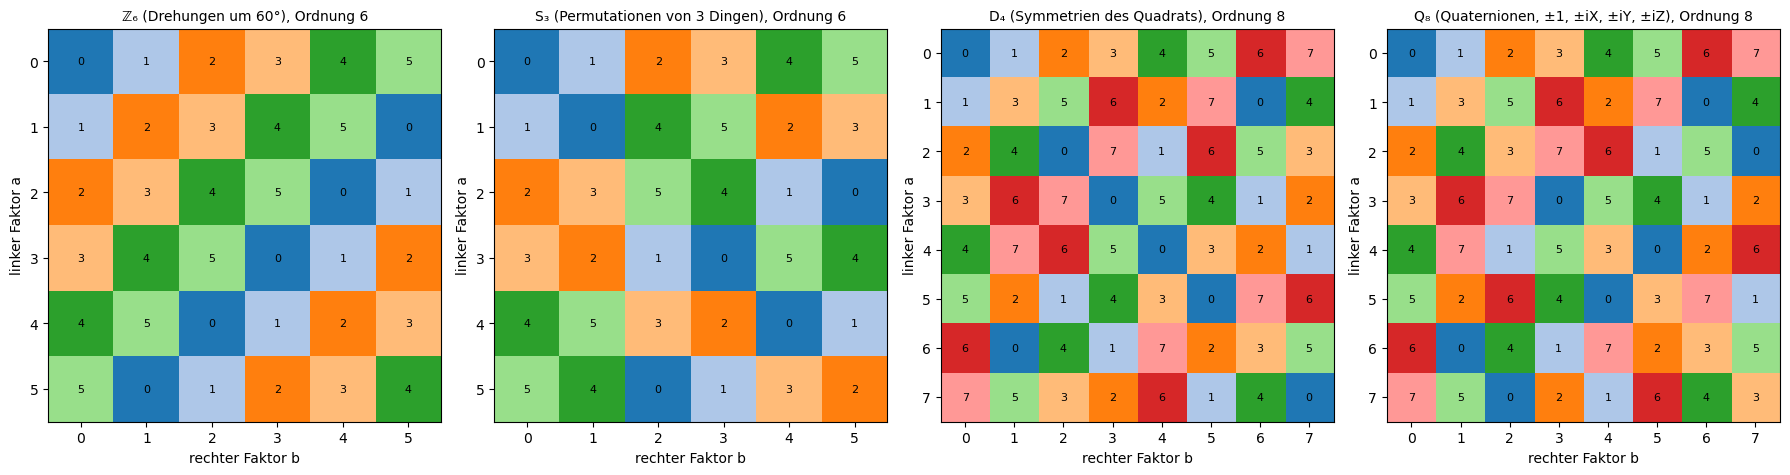

ℤ₆ (Drehungen um 60°)                 : Ordnung  6; lateinisches Quadrat True; assoziativ True; Tafel symmetrisch (abelsch) True; Elementordnungen [1, 2, 3, 3, 6, 6]
S₃ (Permutationen von 3 Dingen)       : Ordnung  6; lateinisches Quadrat True; assoziativ True; Tafel symmetrisch (abelsch) False; Elementordnungen [1, 2, 2, 2, 3, 3]
D₄ (Symmetrien des Quadrats)          : Ordnung  8; lateinisches Quadrat True; assoziativ True; Tafel symmetrisch (abelsch) False; Elementordnungen [1, 2, 2, 2, 2, 2, 4, 4]
Q₈ (Quaternionen, ±1, ±iX, ±iY, ±iZ)  : Ordnung  8; lateinisches Quadrat True; assoziativ True; Tafel symmetrisch (abelsch) False; Elementordnungen [1, 2, 4, 4, 4, 4, 4, 4]


In [2]:
X = np.array([[0, 1], [1, 0]]); Y = np.array([[0, -1j], [1j, 0]]); Z = np.array([[1, 0], [0, -1]])
perm = lambda p: np.eye(len(p))[list(p)]
groups1 = {
    "ℤ₆ (Drehungen um 60°)": matrix_group([rot2(np.pi / 3)]),
    "S₃ (Permutationen von 3 Dingen)": matrix_group([perm([1, 0, 2]), perm([1, 2, 0])]),
    "D₄ (Symmetrien des Quadrats)": matrix_group([rot2(np.pi / 2), np.diag([1.0, -1.0])]),
    "Q₈ (Quaternionen, ±1, ±iX, ±iY, ±iZ)": matrix_group([1j * X, 1j * Z]),
}
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
for ax, (name, G) in zip(axes, groups1.items()):
    T = cayley_table(G)
    ax.imshow(T, cmap="tab20", vmin=0, vmax=19)
    for i in range(len(G)):
        for j in range(len(G)):
            ax.text(j, i, T[i, j], ha="center", va="center", fontsize=8)
    ax.set_title(f"{name}, Ordnung {len(G)}", fontsize=10)
    ax.set_xlabel("rechter Faktor b")
    ax.set_ylabel("linker Faktor a")
plt.tight_layout()
plt.show()

for name, G in groups1.items():
    T = cayley_table(G)
    latin = all(len(set(row)) == len(G) for row in T) and all(len(set(col)) == len(G) for col in T.T)
    assoc = all(np.allclose((A @ B) @ C, A @ (B @ C)) for A in G for B in G for C in G)
    print(f"{name:38s}: Ordnung {len(G):2d}; lateinisches Quadrat {latin}; assoziativ {assoc}; "
          f"Tafel symmetrisch (abelsch) {np.array_equal(T, T.T)}; Elementordnungen {sorted(element_order(E) for E in G)}")

* Die **vier Tafeln** sind lateinische Quadrate: In jeder Zeile und Spalte kommt jede Farbe genau einmal vor. Bei $\mathbb Z_6$ (links) laufen die Farben in Diagonalen, wie bei einer Additionstabelle modulo 6, und die Tafel ist an der Hauptdiagonale gespiegelt gleich: abelsch. Bei $S_3$, $D_4$ und $Q_8$ ist sie nicht symmetrisch. Das beantwortet die Vorhersage: abelsch heißt symmetrische Tafel.
* Laut **Ausgabe** sind alle vier Gruppen assoziativ und lateinische Quadrate. Die Elementordnungen unterscheiden die Paare gleicher Größe: $\mathbb Z_6$ hat $1, 2, 3, 3, 6, 6$, $S_3$ hat $1, 2, 2, 2, 3, 3$; $D_4$ hat fünf Elemente der Ordnung 2, $Q_8$ nur eines und sechs der Ordnung 4. Gleich viele Elemente heißt also nicht gleiche Gruppe. In der Tafel von $Q_8$ sieht man das daran, dass auf der Diagonale ($a\cdot a$) fast nur das Element $-1$ steht.
* **Wo es vorkommt:** $\mathbb Z_n$ ist die Uhrenarithmetik und die Symmetrie jeder $n$-zähligen Drehachse; $S_3$ ist die Symmetrie des Ammoniakmoleküls ($C_{3v}\cong S_3$) und die Galois-Gruppe einer allgemeinen kubischen Gleichung; $D_4$ beschreibt quadratische Moleküle und Pixelgitter (Datenaugmentation durch Drehen und Spiegeln von Bildern); Quaternionen benutzt man in der Computergrafik, der Raumfahrt und der Robotik, um Orientierungen zu speichern und zu interpolieren.

##### *2. Gruppen der Ordnung 8 und 12 unterscheiden*

Wie unterscheidet man Gruppen gleicher Ordnung? Vorher vorhersagen: Wie viele Elemente der Ordnung 2 hat $\mathbb Z_2^3$, wie viele $Q_8$?

Alle fünf Gruppen der Ordnung 8 und alle fünf der Ordnung 12 werden als Matrixgruppen erzeugt. Für jede wird gezählt, wie viele Elemente welche Ordnung haben (Bilder), und die Ausgabe ergänzt die Größe des Zentrums, der Kommutatoruntergruppe $[G, G]$ und die Zahl der Konjugationsklassen.

**Hintergrund & Fachbegriffe:**
- **Invariante:** eine Eigenschaft, die bei Isomorphie erhalten bleibt; haben zwei Gruppen verschiedene Invarianten, sind sie verschieden.
- **Zentrum** $Z(G)$: die Elemente, die mit allen vertauschen.
- **Kommutatoruntergruppe** $[G, G]$: erzeugt von allen $aba^{-1}b^{-1}$; sie ist $\lbrace e\rbrace$ genau für abelsche Gruppen.
- **Konjugationsklasse:** alle $gag^{-1}$ zu einem festen $a$.
- **Direktes Produkt** $\mathbb Z_4\times\mathbb Z_2$: Paare, komponentenweise verknüpft. **Dizyklische Gruppe** $\mathrm{Dic}_3$: erzeugt von $a$ der Ordnung 6 und $x$ mit $x^2 = a^3$ und $xax^{-1} = a^{-1}$.

**Theorie:**

- **Die Liste ist vollständig:** Jede Gruppe der Ordnung 8 ist isomorph zu genau einer der fünf, ebenso bei 12 (Theorie, Abschnitt 4). Für $p^3$ und für $4p$ beweist man das mit den Sylow-Sätzen und dem Struktursatz für abelsche Gruppen (Exp. 8).
- **Zählen nach Ordnungen:** Ein Isomorphismus erhält die Ordnung jedes Elements, deshalb ist das „Ordnungsprofil“ eine Invariante. Es trennt hier alle zehn Gruppen. Allgemein reicht es nicht: Es gibt verschiedene Gruppen mit gleichem Profil (die kleinsten haben Ordnung 16).
- **Klassengleichung:** $\vert G\vert = \vert Z(G)\vert + \sum\vert\text{Klasse}\vert$ über die Klassen mit mehr als einem Element; jede Klassengröße teilt $\vert G\vert$. Bei abelschen Gruppen ist jedes Element seine eigene Klasse.
- **$A_4$:** die Drehgruppe des Tetraeders; ihr Zentrum ist trivial, ihre Kommutatoruntergruppe die Kleinsche Vierergruppe (die drei Drehungen um 180° plus Identität).

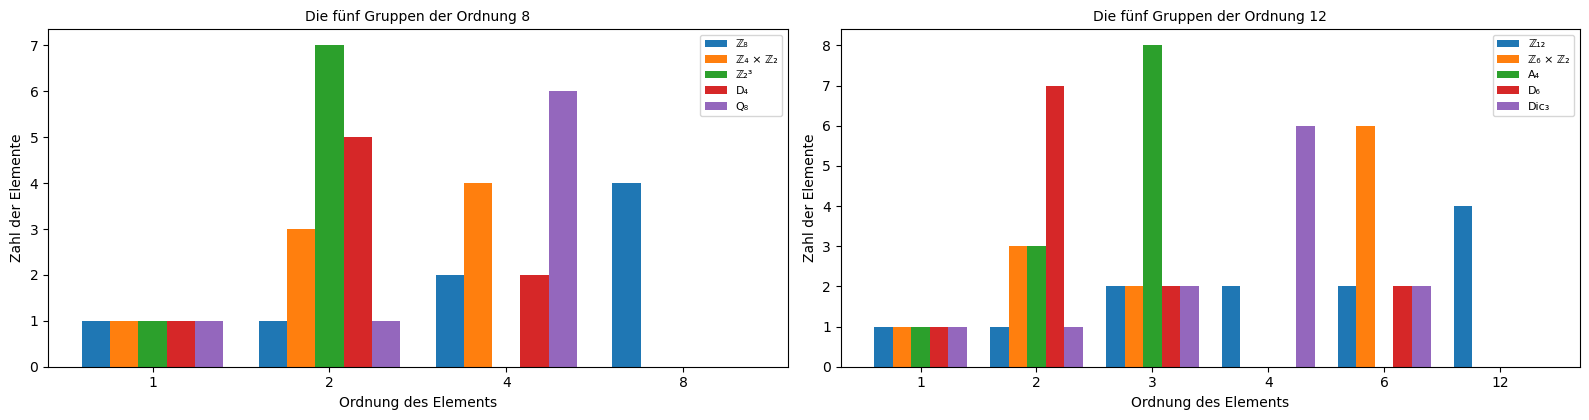

Gruppe    Ordnung  abelsch  |Zentrum|  |[G,G]|  Klassen   Elementordnungen
ℤ₈              8     True          8        1        8   {1: 1, 2: 1, 4: 2, 8: 4}
ℤ₄ × ℤ₂         8     True          8        1        8   {1: 1, 2: 3, 4: 4}
ℤ₂³             8     True          8        1        8   {1: 1, 2: 7}
D₄              8    False          2        2        5   {1: 1, 2: 5, 4: 2}
Q₈              8    False          2        2        5   {1: 1, 2: 1, 4: 6}
ℤ₁₂            12     True         12        1       12   {1: 1, 2: 1, 3: 2, 4: 2, 6: 2, 12: 4}
ℤ₆ × ℤ₂        12     True         12        1       12   {1: 1, 2: 3, 3: 2, 6: 6}
A₄             12    False          1        4        4   {1: 1, 2: 3, 3: 8}
D₆             12    False          2        3        6   {1: 1, 2: 7, 3: 2, 6: 2}
Dic₃           12    False          2        3        6   {1: 1, 2: 1, 3: 2, 4: 6, 6: 2}


In [3]:
def block(*ms):
    n = sum(len(m) for m in ms)
    out, k = np.zeros((n, n), dtype=complex), 0
    for m in ms:
        out[k:k + len(m), k:k + len(m)] = m
        k += len(m)
    return out

w = np.exp(1j * np.pi / 3)
order8 = {
    "ℤ₈": matrix_group([rot2(np.pi / 4)]),
    "ℤ₄ × ℤ₂": matrix_group([block(rot2(np.pi / 2), np.eye(1)), block(np.eye(2), -np.eye(1))]),
    "ℤ₂³": matrix_group([np.diag([-1.0, 1, 1]), np.diag([1.0, -1, 1]), np.diag([1.0, 1, -1])]),
    "D₄": groups1["D₄ (Symmetrien des Quadrats)"],
    "Q₈": groups1["Q₈ (Quaternionen, ±1, ±iX, ±iY, ±iZ)"],
}
order12 = {
    "ℤ₁₂": matrix_group([rot2(np.pi / 6)]),
    "ℤ₆ × ℤ₂": matrix_group([block(rot2(np.pi / 3), np.eye(1)), block(np.eye(2), -np.eye(1))]),
    "A₄": matrix_group([perm([1, 2, 0, 3]), perm([1, 0, 3, 2])]),
    "D₆": matrix_group([rot2(np.pi / 3), np.diag([1.0, -1.0])]),
    "Dic₃": matrix_group([np.diag([w, np.conj(w)]), np.array([[0, 1], [-1, 0]])]),
}
fig, axes = plt.subplots(1, 2, figsize=(16, 4.3))
for ax, fam, possible in [(axes[0], order8, [1, 2, 4, 8]), (axes[1], order12, [1, 2, 3, 4, 6, 12])]:
    width = 0.8 / len(fam)
    for i, (name, G) in enumerate(fam.items()):
        o = [element_order(E) for E in G]
        ax.bar(np.arange(len(possible)) + (i - len(fam) / 2 + 0.5) * width, [o.count(d) for d in possible], width, label=name)
    ax.set_xticks(range(len(possible)), possible)
    ax.set_xlabel("Ordnung des Elements")
    ax.set_ylabel("Zahl der Elemente")
    ax.legend(fontsize=8)
axes[0].set_title("Die fünf Gruppen der Ordnung 8", fontsize=10)
axes[1].set_title("Die fünf Gruppen der Ordnung 12", fontsize=10)
plt.tight_layout()
plt.show()

print(f"{'Gruppe':9s} {'Ordnung':>7s} {'abelsch':>8s} {'|Zentrum|':>10s} {'|[G,G]|':>8s} {'Klassen':>8s}   Elementordnungen")
for fam in (order8, order12):
    for name, G in fam.items():
        inv = invariants(G)
        prof = {d: inv["orders"].count(d) for d in sorted(set(inv["orders"]))}
        print(f"{name:9s} {inv['order']:7d} {str(inv['abelian']):>8s} {inv['center']:10d} {inv['derived']:8d} {inv['classes']:8d}   {prof}")

* Das **linke Bild** zeigt die Ordnung-8-Gruppen: $\mathbb Z_8$ hat vier Elemente der Ordnung 8 (die Erzeuger), $\mathbb Z_2^3$ sieben der Ordnung 2 (jedes Element außer $e$ ist sein eigenes Inverses), $Q_8$ sechs der Ordnung 4 und nur eines der Ordnung 2. Das beantwortet die Vorhersage: 7 gegen 1. $D_4$ und $\mathbb Z_4\times\mathbb Z_2$ liegen dazwischen. Im **rechten Bild** fällt $A_4$ mit acht Elementen der Ordnung 3 auf (Drehungen um die vier Ecken-Flächen-Achsen des Tetraeders) und $\mathrm{Dic}_3$ mit sechs der Ordnung 4.
* Laut **Ausgabe**: Die abelschen Gruppen haben Zentrum = ganze Gruppe, Kommutatoruntergruppe 1 und so viele Klassen wie Elemente. $D_4$ und $Q_8$ haben beide Zentrum 2, Kommutatoruntergruppe 2 und 5 Klassen; erst die Ordnungen trennen sie. $A_4$ hat triviales Zentrum, Kommutatoruntergruppe 4 und 4 Klassen; $D_6$ und $\mathrm{Dic}_3$ stimmen in Zentrum (2), Kommutatoruntergruppe (3) und Klassenzahl (6) überein und unterscheiden sich wieder nur in den Ordnungen (sieben gegen ein Element der Ordnung 2).
* **Wo es vorkommt:** Dieselbe Aufgabe, „sind zwei Strukturen gleich?“, stellt sich überall: in der Chemie (haben zwei Moleküle dieselbe Punktgruppe?), bei der Graphenisomorphie und beim Vergleich von Kristallstrukturen. Computeralgebrasysteme wie GAP bestimmen den Isomorphietyp einer Gruppe über solche Invarianten und schlagen sie dann in der SmallGroups-Bibliothek nach. $Q_8$ ist eine der Pauli-Gruppe eng verwandte Gruppe, $A_4$ die Punktgruppe $T$ chiraler tetraedrischer Moleküle.

##### *3. Wie viele Gruppen gibt es?*

Wie viele verschiedene Gruppen gibt es zu einer gegebenen Ordnung? Vorher vorhersagen: Wie viele Gruppen der Ordnung 13 gibt es, und wie viele der Ordnung 64?

Die Zahl der Gruppen der Ordnung $n$ für $n\leq130$ und für Zweierpotenzen bis 1024 stammt aus der Folge A000001 der OEIS (berechnet mit GAP). Die Zahl der abelschen Gruppen berechnet der Code selbst aus der Primfaktorzerlegung. Links stehen alle Gruppen und die abelschen, in der Mitte die Ordnungen nach Typ der Zerlegung ($p$, $p^2$, $pq$, $2^k$), rechts die Zweierpotenzen.

**Hintergrund & Fachbegriffe:**
- **Bis auf Isomorphie:** Isomorphe Gruppen zählen als eine.
- **Primfaktorzerlegung:** $n = p_1^{e_1}\cdots p_r^{e_r}$; sie bestimmt weitgehend, wie viele Gruppen es gibt.
- **Partitionszahl** $p(e)$: die Zahl der Möglichkeiten, $e$ als Summe positiver ganzer Zahlen zu schreiben ($p(3) = 3$: $3, 2 + 1, 1 + 1 + 1$).
- **$p$-Gruppe:** eine Gruppe, deren Ordnung eine Primzahlpotenz $p^k$ ist.

**Theorie:**

- **Primzahlordnung:** Nach Lagrange hat jedes Element außer $e$ die Ordnung $p$ und erzeugt die Gruppe; also gibt es nur $\mathbb Z_p$.
- **Ordnung $p^2$:** Gruppen mit $p^2$ Elementen sind abelsch; es gibt genau $\mathbb Z_{p^2}$ und $\mathbb Z_p^2$.
- **Ordnung $pq$** ($p < q$ prim): Gibt es nur die zyklische Gruppe, wenn $p$ nicht $q - 1$ teilt; teilt $p$ die Zahl $q - 1$, kommt eine nichtabelsche hinzu (ein semidirektes Produkt; für $p = 2$ die Diedergruppe $D_q$). Das folgt aus den Sylow-Sätzen.
- **Abelsche Gruppen:** Nach dem Struktursatz (Exp. 8) ist ihre Zahl $\prod_ip(e_i)$; für $n = 72 = 2^3\cdot3^2$ also $p(3)\cdot p(2) = 6$.
- **Zweierpotenzen:** Die Zahl der Gruppen der Ordnung $p^k$ wächst wie $p^{2k^3/27}$ (Higman, Sims). 1, 1, 2, 5, 14, 51, 267, 2328, 56 092, 10 494 213 und 49 487 367 289 Gruppen haben die Ordnungen $2^0$ bis $2^{10}$ (Besche, Eick, O'Brien 2002). Von den rund 50 Milliarden Gruppen mit höchstens 2000 Elementen haben über 99 % die Ordnung 1024.

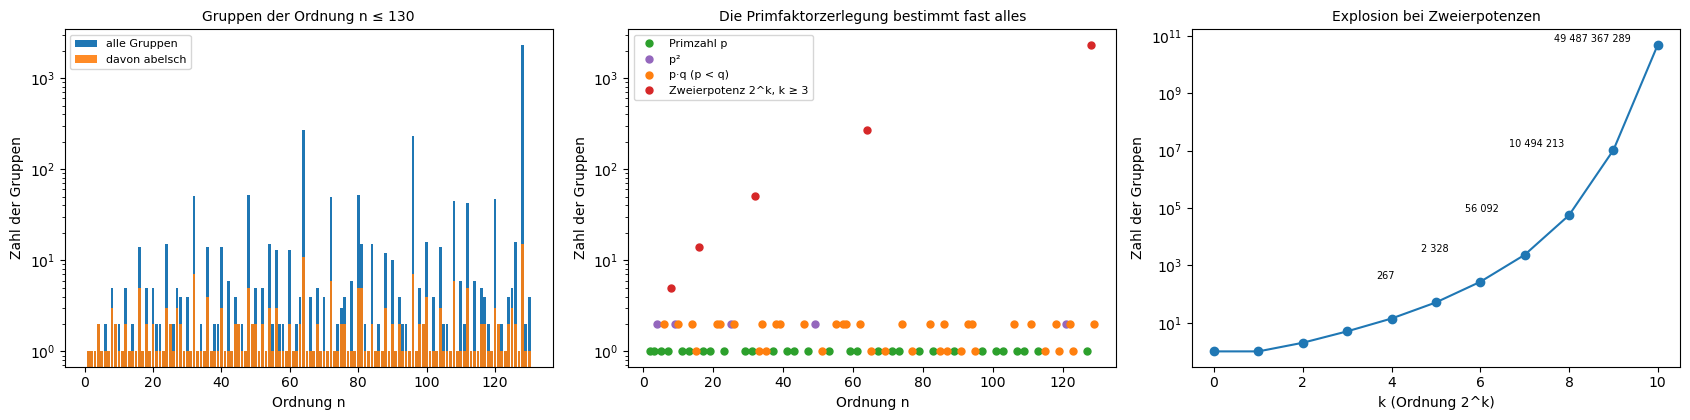

Ordnung p (Primzahl): immer genau {1} Gruppe;  Ordnung p²: immer {2}
Ordnung p·q: Vorhersage 2 wenn p | q − 1, sonst 1 – stimmt für alle 38 Fälle bis 130: True
Gruppen der Ordnung ≤ 130: 3602, davon Ordnung 128: 2328 (65%); abelsch insgesamt 249


In [4]:
# Zahl der Gruppen der Ordnung n, n = 1 … 130 (OEIS A000001, berechnet mit der SmallGroups-Bibliothek von GAP)
a000001 = [1, 1, 1, 2, 1, 2, 1, 5, 2, 2, 1, 5, 1, 2, 1, 14, 1, 5, 1, 5, 2, 2, 1, 15, 2, 2, 5, 4, 1, 4, 1, 51, 1, 2, 1, 14,
           1, 2, 2, 14, 1, 6, 1, 4, 2, 2, 1, 52, 2, 5, 1, 5, 1, 15, 2, 13, 2, 2, 1, 13, 1, 2, 4, 267, 1, 4, 1, 5, 1, 4, 1,
           50, 1, 2, 3, 4, 1, 6, 1, 52, 15, 2, 1, 15, 1, 2, 1, 12, 1, 10, 1, 4, 2, 2, 1, 231, 1, 5, 2, 16, 1, 4, 1, 14,
           2, 2, 1, 45, 1, 6, 2, 43, 1, 6, 1, 5, 4, 2, 1, 47, 2, 2, 1, 4, 5, 16, 1, 2328, 2, 4]
powers_of_two = {1: 1, 2: 1, 4: 2, 8: 5, 16: 14, 32: 51, 64: 267, 128: 2328, 256: 56092, 512: 10494213, 1024: 49487367289}

def abelian_count(n):
    """Zahl der abelschen Gruppen der Ordnung n: Produkt der Partitionszahlen der Primzahlexponenten."""
    out = 1
    for e in factorint(n).values():
        out *= int(partition(e))
    return out

n = np.arange(1, 131)
ab = np.array([abelian_count(int(k)) for k in n])
allg = np.array(a000001)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
axes[0].bar(n, allg, color="tab:blue", label="alle Gruppen")
axes[0].bar(n, ab, color="tab:orange", alpha=0.9, label="davon abelsch")
axes[0].set_yscale("log")
axes[0].set_xlabel("Ordnung n")
axes[0].set_ylabel("Zahl der Gruppen")
axes[0].set_title("Gruppen der Ordnung n ≤ 130", fontsize=10)
axes[0].legend(fontsize=8)
kinds = {"Primzahl p": [k for k in n if len(factorint(int(k))) == 1 and list(factorint(int(k)).values())[0] == 1],
         "p²": [k for k in n if len(factorint(int(k))) == 1 and list(factorint(int(k)).values())[0] == 2],
         "p·q (p < q)": [k for k in n if sorted(factorint(int(k)).values()) == [1, 1]],
         "Zweierpotenz 2^k, k ≥ 3": [k for k in n if k >= 8 and (k & (k - 1)) == 0]}
for (label, ks), c in zip(kinds.items(), ["tab:green", "tab:purple", "tab:orange", "tab:red"]):
    ks = np.array(ks)
    axes[1].plot(ks, allg[ks - 1], "o", c=c, ms=5, label=label)
axes[1].set_yscale("log")
axes[1].set_xlabel("Ordnung n")
axes[1].set_ylabel("Zahl der Gruppen")
axes[1].set_title("Die Primfaktorzerlegung bestimmt fast alles", fontsize=10)
axes[1].legend(fontsize=8)
kk = np.array(list(powers_of_two))
axes[2].semilogy(np.log2(kk), list(powers_of_two.values()), "o-")
for k_, v in powers_of_two.items():
    if k_ >= 64:
        axes[2].annotate(fmt(v), (np.log2(k_), v), textcoords="offset points", xytext=(-75, 2), fontsize=7)
axes[2].set_xlabel("k (Ordnung 2^k)")
axes[2].set_ylabel("Zahl der Gruppen")
axes[2].set_title("Explosion bei Zweierpotenzen", fontsize=10)
plt.tight_layout()
plt.show()

pq = kinds["p·q (p < q)"]
pred = [2 if (max(factorint(int(k))) - 1) % min(factorint(int(k))) == 0 else 1 for k in pq]
print(f"Ordnung p (Primzahl): immer genau {set(allg[np.array(kinds['Primzahl p']) - 1])} Gruppe;  Ordnung p²: immer {set(allg[np.array(kinds['p²']) - 1])}")
print(f"Ordnung p·q: Vorhersage 2 wenn p | q − 1, sonst 1 – stimmt für alle {len(pq)} Fälle bis 130: {list(allg[np.array(pq) - 1]) == pred}")
print(f"Gruppen der Ordnung ≤ 130: {allg.sum()}, davon Ordnung 128: {allg[127]} ({allg[127] / allg.sum():.0%}); abelsch insgesamt {ab.sum()}")

* Im **linken Bild** (logarithmische Achse) hat die Mehrzahl der Ordnungen nur ein oder zwei Gruppen; hohe Balken stehen bei Ordnungen mit vielen Faktoren 2: 16 (14), 32 (51), 48 (52), 64 (267), 96 (231) und 128 (2328). Die abelschen Gruppen (orange) sind fast überall eine kleine Minderheit. Im **mittleren Bild** liegen alle Primzahlen bei 1, alle Quadrate $p^2$ bei 2, die Produkte $pq$ bei 1 oder 2, die Zweierpotenzen explodieren. Das beantwortet die Vorhersage: eine Gruppe der Ordnung 13, 267 der Ordnung 64.
* Laut **Ausgabe** stimmt die Regel „2, wenn $p$ die Zahl $q - 1$ teilt, sonst 1“ für alle 38 Ordnungen $pq$ bis 130. Von den 3602 Gruppen mit höchstens 130 Elementen haben 2328 (65 %) die Ordnung 128; nur 249 sind abelsch. Das **rechte Bild** zeigt die Explosion bei $2^k$: von 2328 bei 128 über 56 092 und 10 494 213 auf 49 487 367 289 bei 1024.
* **Wo es vorkommt:** Die SmallGroups-Bibliothek von GAP ist das Nachschlagewerk der Gruppentheorie; Physiker und Chemiker benutzen sie, um zu einer gemessenen Symmetrie die Gruppe zu finden. Dass fast alle Gruppen $p$-Gruppen sind, ist eine der überraschenden Einsichten der Theorie, und $p$-Gruppen tauchen in der Kryptographie (Gruppen mit schwerem diskretem Logarithmus) und bei Quantenfehlerkorrekturcodes auf (die Pauli-Gruppe von $n$ Qubits hat $4^{n + 1}$ Elemente).

##### *4. Untergruppen, Lagrange und Normalteiler: der Verband von S₄*

Welche Untergruppen hat eine Gruppe, und welche davon sind Normalteiler? Vorher vorhersagen: Hat $A_4$ (12 Elemente) eine Untergruppe mit 6 Elementen?

Alle Untergruppen der symmetrischen Gruppe $S_4$ werden mit sympy bestimmt: Weil jede Untergruppe von $S_4$ von höchstens zwei Elementen erzeugt wird, reicht es, die von allen Paaren erzeugten Gruppen zu sammeln. Links stehen sie als **Hasse-Diagramm**, nach Ordnung geschichtet, mit einer Linie von $H$ zu $K$, wenn $H\subset K$ ohne Zwischenstufe; rot sind die Normalteiler. Rechts wird für $A_4$ gezählt, wie viele Untergruppen jede mögliche Ordnung hat.

**Hintergrund & Fachbegriffe:**
- **Untergruppenverband:** alle Untergruppen, geordnet nach Enthaltensein.
- **Hasse-Diagramm:** eine Zeichnung einer Ordnung, in der nur die direkten Beziehungen als Linien erscheinen.
- **Normalteiler:** eine Untergruppe, die bei Konjugation in sich übergeht.
- **Kleinsche Vierergruppe** $V_4$: in $S_4$ die Identität und die drei Doppelvertauschungen $(12)(34)$, $(13)(24)$, $(14)(23)$.
- **Faktorgruppe** $G/N$: die Gruppe der Nebenklassen eines Normalteilers.

**Theorie:**

- **Lagrange:** Die Ordnung jeder Untergruppe teilt die Gruppenordnung. Die Umkehrung gilt nicht: Ein Teiler $d$ von $\vert G\vert$ muss nicht als Untergruppenordnung vorkommen. Das kleinste Gegenbeispiel ist $A_4$ mit $d = 6$. Grund: Eine Untergruppe vom Index 2 wäre ein Normalteiler und müsste alle acht Elemente der Ordnung 3 enthalten (jedes Quadrat liegt in ihr, und die Elemente der Ordnung 3 sind Quadrate), mehr als 6.
- **Sylow** garantiert dagegen Untergruppen für jede Primzahlpotenz: $S_4$ hat Untergruppen der Ordnungen 8 (drei Diedergruppen, die Sylow-2-Untergruppen) und 3 (vier zyklische).
- **Normalteiler von $S_4$:** $\lbrace e\rbrace$, $V_4$, $A_4$, $S_4$. Die Reihe $S_4\triangleright A_4\triangleright V_4\triangleright\lbrace e\rbrace$ hat abelsche Faktoren $\mathbb Z_2$, $\mathbb Z_3$, $\mathbb Z_2^2$: $S_4$ ist **auflösbar** (Exp. 9). Das ist der Grund, warum es für Gleichungen vierten Grades eine Lösungsformel gibt.
- **$S_4/V_4\cong S_3$:** Geometrisch wirkt $S_4$ (die Drehgruppe des Würfels) auf die drei Achsen durch gegenüberliegende Flächenmitten; $V_4$ sind genau die Drehungen, die jede Achse auf sich abbilden.

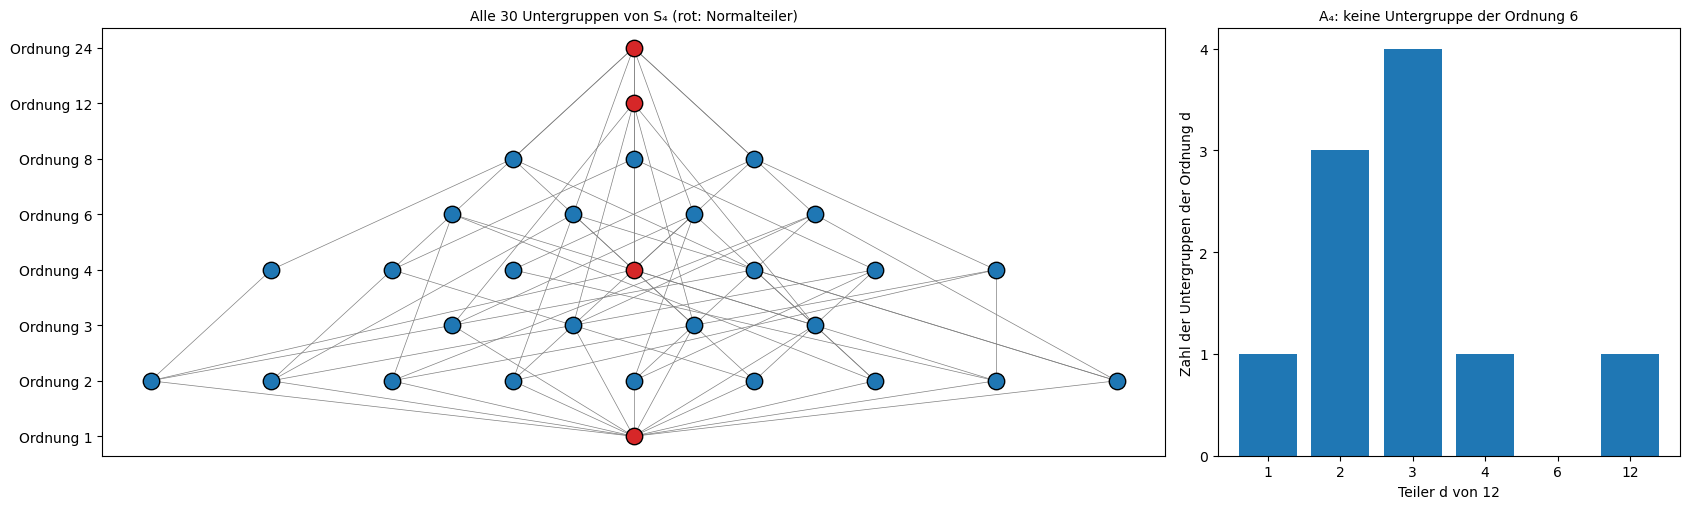

Untergruppen von S₄ nach Ordnung: {1: 1, 2: 9, 3: 4, 4: 7, 6: 4, 8: 3, 12: 1, 24: 1} – alle Ordnungen teilen 24: True
Normalteiler von S₄ (Ordnungen): [1, 4, 12, 24]
S₄/V₄: 6 Nebenklassen; die Faktorgruppe ist nicht abelsch und damit ≅ S₃
Untergruppen von A₄ nach Ordnung: {1: 1, 2: 3, 3: 4, 4: 1, 6: 0, 12: 1}


In [5]:
S4 = SymmetricGroup(4)
els = list(S4.generate())
subgroups = {}
for g, h in itertools.combinations_with_replacement(els, 2):                     # jede Untergruppe von S₄ wird von zwei Elementen erzeugt
    H = PermutationGroup([g, h])
    subgroups[frozenset(tuple(p.array_form) for p in H.generate())] = H
subs = sorted(subgroups, key=len)
normal = [S for S in subs if all(frozenset(tuple((x * Permutation(list(s)) * x ** -1).array_form) for s in S) == S for x in S4.generators)]

fig, axes = plt.subplots(1, 2, figsize=(17, 5.2), gridspec_kw={"width_ratios": [2.3, 1]})
levels = sorted({len(S) for S in subs})
pos = {}
for lv, size in enumerate(levels):
    row = [S for S in subs if len(S) == size]
    for i, S in enumerate(row):
        pos[S] = ((i - (len(row) - 1) / 2) * 1.0, lv)
for S in subs:
    for T in subs:
        if len(T) > len(S) and S < T and not any(S < U < T for U in subs):  # nur direkte Inklusionen
            axes[0].plot([pos[S][0], pos[T][0]], [pos[S][1], pos[T][1]], color="grey", lw=0.5, zorder=1)
for S in subs:
    axes[0].scatter(*pos[S], s=140, c="tab:red" if S in normal else "tab:blue", zorder=2, edgecolor="k")
axes[0].set_yticks(range(len(levels)), [f"Ordnung {s}" for s in levels])
axes[0].set_xticks([])
axes[0].set_title(f"Alle {len(subs)} Untergruppen von S₄ (rot: Normalteiler)", fontsize=10)
A4 = AlternatingGroup(4)
a4_subs = {frozenset(tuple(p.array_form) for p in PermutationGroup([g, h]).generate())
           for g, h in itertools.combinations_with_replacement(list(A4.generate()), 2)}
divisors = [d for d in range(1, 13) if 12 % d == 0]
counts = [sum(1 for S in a4_subs if len(S) == d) for d in divisors]
axes[1].bar([str(d) for d in divisors], counts, color=["tab:blue" if c else "tab:red" for c in counts])
axes[1].set_xlabel("Teiler d von 12")
axes[1].set_ylabel("Zahl der Untergruppen der Ordnung d")
axes[1].set_title("A₄: keine Untergruppe der Ordnung 6", fontsize=10)
axes[1].set_yticks(range(0, max(counts) + 1))
plt.tight_layout()
plt.show()

print("Untergruppen von S₄ nach Ordnung:", {s: sum(1 for S in subs if len(S) == s) for s in levels}, f"– alle Ordnungen teilen 24: {all(24 % len(S) == 0 for S in subs)}")
print("Normalteiler von S₄ (Ordnungen):", [len(S) for S in normal])
V4 = next(S for S in normal if len(S) == 4)
cosets = {frozenset(tuple((Permutation(list(v)) * g).array_form) for v in V4) for g in els}
print(f"S₄/V₄: {len(cosets)} Nebenklassen; die Faktorgruppe ist nicht abelsch und damit ≅ S₃")
print("Untergruppen von A₄ nach Ordnung:", dict(zip(divisors, counts)))

* Im **linken Bild** stehen alle 30 Untergruppen von $S_4$: laut **Ausgabe** 1 der Ordnung 1, 9 der Ordnung 2, 4 der Ordnung 3, 7 der Ordnung 4, 4 der Ordnung 6, 3 der Ordnung 8, 1 der Ordnung 12 und $S_4$ selbst. Alle Ordnungen teilen 24 (Lagrange). Nur vier Knoten sind rot, die Normalteiler mit den Ordnungen 1, 4, 12 und 24; die meisten Untergruppen werden durch Konjugation verschoben (etwa die neun Untergruppen der Ordnung 2 in drei Klassen von Vertauschungen und Doppelvertauschungen).
* Die Ausgabe bestätigt: $V_4$ hat 6 Nebenklassen, die Faktorgruppe $S_4/V_4$ hat 6 Elemente und ist nicht abelsch, also $S_3$. Im **rechten Bild** hat $A_4$ Untergruppen der Ordnungen 1, 2, 3, 4 und 12, aber keine der Ordnung 6, obwohl 6 die Zahl 12 teilt. Das beantwortet die Vorhersage.
* **Wo es vorkommt:** Untergruppen einer Symmetriegruppe beschreiben **Symmetriebrechung**: Wird ein Kristall verzerrt oder ein Molekül substituiert, bleibt eine Untergruppe der Symmetrie übrig, und die Faktorgruppe zählt die gleichwertigen Varianten (Domänen in Ferroelektrika, Isomere). In der Physik bestimmt die Kette von Untergruppen, wie Energieniveaus aufspalten (Kristallfeldtheorie). In der Galois-Theorie entsprechen Untergruppen den Zwischenkörpern; eine Reihe mit abelschen Faktoren entspricht einer Lösung durch Wurzeln.

##### *5. Gruppenoperationen zählen: Burnside und chemische Isomere*

Wie viele wirklich verschiedene Muster gibt es, wenn symmetrische Varianten als gleich gelten? Vorher vorhersagen: Wie viele verschiedene Dichlorbenzole $C_6H_4Cl_2$ gibt es?

Drei Zählprobleme werden durchgezählt und mit dem Lemma von Burnside verglichen. Links: An einen Benzolring werden $k$ Chloratome statt Wasserstoff gesetzt, und die Symmetriegruppe $D_6$ des Sechsecks identifiziert gleichwertige Stellungen. In der Mitte: Die sechs Seiten eines Würfels werden mit $k$ Farben gefärbt, gleich bis auf Drehung. Rechts: Ketten aus $n$ Perlen in zwei Farben, gleich bis auf Drehung (Halsketten) oder auch Spiegelung (Armbänder).

**Hintergrund & Fachbegriffe:**
- **Gruppenoperation:** Die Gruppe bewegt die Objekte (hier: Positionen am Ring, Würfelseiten, Perlen) und damit auch die Färbungen.
- **Bahn:** alle Färbungen, die durch Symmetrie ineinander übergehen; eine Bahn ist ein „wirklich verschiedenes“ Muster.
- **Fixpunkt** einer Symmetrie $g$: eine Färbung, die $g$ nicht verändert.
- **Isomere:** Moleküle mit gleicher Summenformel, aber verschiedener Anordnung; hier **Stellungsisomere** (ortho, meta, para).

**Theorie:**

- **Lemma von Burnside** (eigentlich Cauchy-Frobenius): $\#\text{Bahnen} = \frac1{\vert G\vert}\sum_{g\in G}\vert\mathrm{Fix}(g)\vert$. Grund: Zählt man die Paare (Symmetrie, Färbung) mit $g\cdot x = x$ einmal nach $g$ und einmal nach $x$, ergibt die zweite Zählung $\sum_x\vert G_x\vert = \sum_x\vert G\vert/\vert G\cdot x\vert$, und jede Bahn trägt genau $\vert G\vert$ bei (Bahn-Stabilisator-Satz).
- **Würfel:** Die 24 Drehungen zerfallen in 1 Identität (fixiert alle $k^6$ Färbungen), 6 Vierteldrehungen um Flächenachsen ($k^3$), 3 halbe Drehungen um Flächenachsen ($k^4$), 8 Drehungen um Raumdiagonalen ($k^2$) und 6 halbe Drehungen um Kantenachsen ($k^3$). Burnside gibt $\frac1{24}(k^6 + 3k^4 + 12k^3 + 8k^2)$.
- **Halsketten:** Eine Drehung um $d$ Plätze hat $\gcd(d, n)$ Zyklen; das ergibt $\frac1n\sum_{d\mid n}\varphi(d)\,2^{n/d}$ mit der Eulerschen $\varphi$-Funktion. Mit Spiegelungen ($D_n$) wird die Zahl etwas kleiner.
- **Pólya** (1937) erweiterte Burnside zu einer Formel, die auch zählt, wie oft jede Farbe vorkommt; er entwickelte sie für das Zählen chemischer Verbindungen.

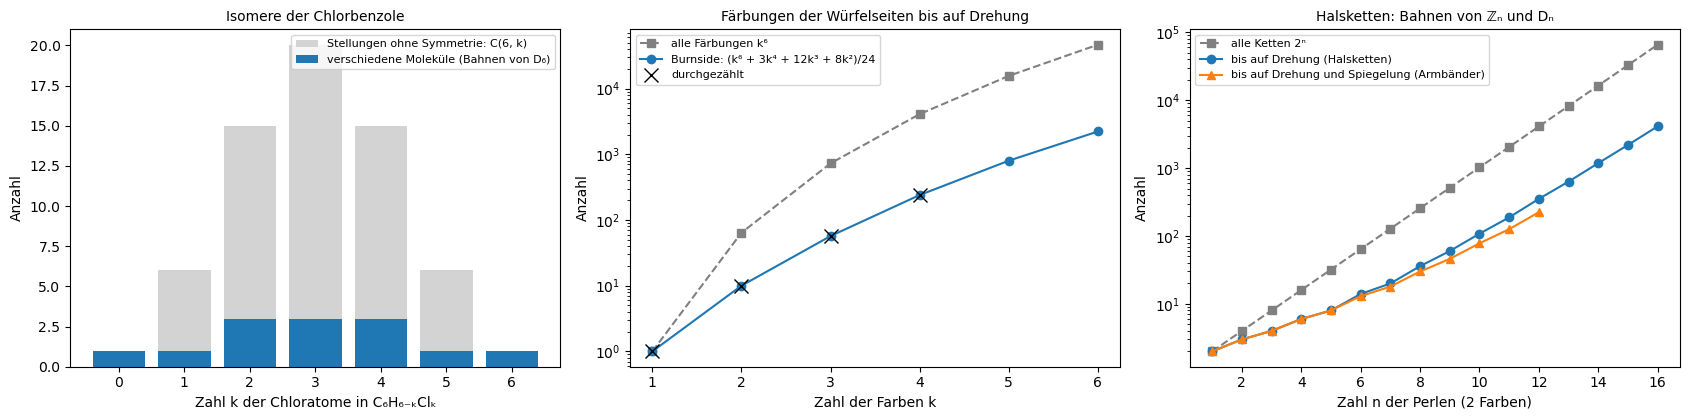

Chlorbenzole C₆H₆₋ₖClₖ für k = 0 … 6: [1, 1, 3, 3, 3, 1, 1] (Burnside [1, 1, 3, 3, 3, 1, 1]), zusammen 13
Drehgruppe des Würfels: 24 Elemente; Färbungen mit k = 1 … 4 Farben durchgezählt [1, 10, 57, 240], Burnside [1, 10, 57, 240]
Halsketten mit 2 Farben, n = 6, 10, 16: 14, 108, 4116;  Armbänder n = 6, 10: 13, 78


In [6]:
hexagon = [tuple((i + r) % 6 for i in range(6)) for r in range(6)] + [tuple((r - i) % 6 for i in range(6)) for r in range(6)]   # D₆ auf 6 Ecken

def orbits(patterns, group):
    """Bahnen einer Permutationsgruppe auf Färbungen: Vertreter = kleinste Färbung der Bahn."""
    return {min(tuple(p[g[i]] for i in range(len(p))) for g in group) for p in patterns}

isomers = [len([o for o in orbits(itertools.product([0, 1], repeat=6), hexagon) if sum(o) == k]) for k in range(7)]
burnside_isomers = []
for k in range(7):
    fixed = [sum(1 for p in itertools.product([0, 1], repeat=6) if sum(p) == k and all(p[g[i]] == p[i] for i in range(6))) for g in hexagon]
    burnside_isomers.append(sum(fixed) / len(hexagon))

faces = {"U": 0, "D": 1, "F": 2, "B": 3, "L": 4, "R": 5}
turn_x = [2, 3, 1, 0, 4, 5]; turn_z = [4, 5, 2, 3, 1, 0]                            # Vierteldrehungen des Würfels als Permutation der Seiten
cube = matrix_group([perm(turn_x), perm(turn_z)])
cube_perms = [tuple(int(np.argmax(np.real(P[:, j]))) for j in range(6)) for P in cube]
ks = range(1, 7)
brute = [len(orbits(itertools.product(range(k), repeat=6), cube_perms)) if k <= 4 else None for k in ks]
formula = [(k ** 6 + 3 * k ** 4 + 12 * k ** 3 + 8 * k ** 2) // 24 for k in ks]

def necklaces(n, k=2):
    return sum(int(totient(d)) * k ** (n // d) for d in range(1, n + 1) if n % d == 0) // n

ns = np.arange(1, 17)
neck = [necklaces(int(m)) for m in ns]
brace = []
for m in ns:
    m = int(m)
    D = [tuple((i + r) % m for i in range(m)) for r in range(m)] + [tuple((r - i) % m for i in range(m)) for r in range(m)]
    brace.append(len(orbits(itertools.product([0, 1], repeat=m), D)) if m <= 12 else None)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
axes[0].bar(range(7), [len([p for p in itertools.product([0, 1], repeat=6) if sum(p) == k]) for k in range(7)], color="lightgrey", label="Stellungen ohne Symmetrie: C(6, k)")
axes[0].bar(range(7), isomers, color="tab:blue", label="verschiedene Moleküle (Bahnen von D₆)")
axes[0].set_xlabel("Zahl k der Chloratome in C₆H₆₋ₖClₖ")
axes[0].set_ylabel("Anzahl")
axes[0].set_title("Isomere der Chlorbenzole", fontsize=10)
axes[0].legend(fontsize=8)
axes[1].semilogy(list(ks), [k ** 6 for k in ks], "s--", c="grey", label="alle Färbungen k⁶")
axes[1].semilogy(list(ks), formula, "o-", label="Burnside: (k⁶ + 3k⁴ + 12k³ + 8k²)/24")
axes[1].semilogy([k for k, b in zip(ks, brute) if b], [b for b in brute if b], "kx", ms=10, label="durchgezählt")
axes[1].set_xlabel("Zahl der Farben k")
axes[1].set_ylabel("Anzahl")
axes[1].set_title("Färbungen der Würfelseiten bis auf Drehung", fontsize=10)
axes[1].legend(fontsize=8)
axes[2].semilogy(ns, 2.0 ** ns, "s--", c="grey", label="alle Ketten 2ⁿ")
axes[2].semilogy(ns, neck, "o-", label="bis auf Drehung (Halsketten)")
axes[2].semilogy(ns[:12], brace[:12], "^-", label="bis auf Drehung und Spiegelung (Armbänder)")
axes[2].set_xlabel("Zahl n der Perlen (2 Farben)")
axes[2].set_ylabel("Anzahl")
axes[2].set_title("Halsketten: Bahnen von ℤₙ und Dₙ", fontsize=10)
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Chlorbenzole C₆H₆₋ₖClₖ für k = 0 … 6: {isomers} (Burnside {[int(b) for b in burnside_isomers]}), zusammen {sum(isomers)}")
print(f"Drehgruppe des Würfels: {len(cube)} Elemente; Färbungen mit k = 1 … 4 Farben durchgezählt {brute[:4]}, Burnside {formula[:4]}")
print(f"Halsketten mit 2 Farben, n = 6, 10, 16: {neck[5]}, {neck[9]}, {neck[15]};  Armbänder n = 6, 10: {brace[5]}, {brace[9]}")

* Im **linken Bild** stehen die Isomere der Chlorbenzole: grau die Zahl der Stellungen ohne Symmetrie, blau die verschiedenen Moleküle. Laut **Ausgabe** gibt es für $k = 0$ bis 6 genau $1, 1, 3, 3, 3, 1, 1$ Moleküle, zusammen 13, wie Burnside vorhersagt. Für $k = 2$ sind das die drei Dichlorbenzole ortho (benachbart), meta (eine Lücke) und para (gegenüber); das beantwortet die Vorhersage. Aus 15 Stellungen werden 3 Moleküle.
* Im **mittleren Bild** liegen die durchgezählten Würfelfärbungen (Kreuze) genau auf der Burnside-Formel: 1, 10, 57, 240 für $k = 1$ bis 4 Farben, rund ein 24stel aller $k^6$ Färbungen, weil die meisten Färbungen keine Symmetrie haben und 24 gleichwertige Lagen besitzen. Im **rechten Bild** wachsen Halsketten wie $2^n/n$: 14, 108 und 4116 für $n = 6, 10, 16$; mit Spiegelung als gleich (Armbänder) sind es 13 und 78 für $n = 6$ und 10.
* **Wo es vorkommt:** **Isomerenzählung** in der Chemie (Pólya entwickelte seine Theorie dafür; Programme zur Strukturaufklärung zählen damit Kandidaten), die Zahl verschiedener Kristalldefekte oder Legierungsanordnungen, Kombinatorik von Graphen (Zahl nicht isomorpher Graphen), die Zahl wesentlich verschiedener Boolescher Funktionen in der Schaltungstechnik und in der Musiktheorie die Zahl verschiedener Akkorde und Tonleitern bis auf Transposition.

##### *6. Die symmetrische Gruppe: Zyklen, Vorzeichen und zufällige Permutationen*

Wie sieht eine typische Permutation aus? Vorher vorhersagen: Mit welcher Wahrscheinlichkeit lässt eine zufällige Permutation von 100 Elementen kein einziges Element an seinem Platz?

Links stehen die Ordnung $n!$ von $S_n$ und die Zahl ihrer Konjugationsklassen. In der Mitte werden 100 000 zufällige Permutationen von 100 Elementen gezogen und ihre Fixpunkte gezählt. Rechts werden 50 000 zufällige Permutationen von 300 Elementen in Zyklen zerlegt und die Länge des längsten Zyklus gemessen. Die Ausgabe vergleicht mit exakten Formeln, unter anderem einer Rekursion für die Verteilung des längsten Zyklus, und prüft das 15-Puzzle.

**Hintergrund & Fachbegriffe:**
- **Zyklenschreibweise:** $(1\,3\,5)(2\,4)$ heißt $1\to3\to5\to1$ und $2\to4\to2$; jede Permutation zerfällt eindeutig in solche Zyklen. Der **Zyklentyp** ist die Liste der Zyklenlängen.
- **Fixpunkt:** ein Element, das an seinem Platz bleibt (ein Zyklus der Länge 1). Eine Permutation ohne Fixpunkt heißt **Derangement**.
- **Vorzeichen** (Signum): $+1$ für eine gerade, $-1$ für eine ungerade Zahl von Vertauschungen; ein Zyklus der Länge $\ell$ hat das Vorzeichen $(-1)^{\ell - 1}$.
- **Harmonische Zahl** $H_n = 1 + \frac12 + \dots + \frac1n\approx\ln n + 0.577$.

**Theorie:**

- **Konjugationsklassen = Zyklentypen:** $\sigma\pi\sigma^{-1}$ hat dieselben Zyklenlängen wie $\pi$, nur mit umbenannten Elementen. Deshalb gibt es so viele Klassen wie Partitionen $p(n)$ von $n$, für $n = 30$ nur 5604 bei $2.7\cdot10^{32}$ Elementen.
- **Vorzeichen:** Das Vorzeichen ist ein Homomorphismus $S_n\to\lbrace\pm1\rbrace$; sein Kern sind die geraden Permutationen, die **alternierende Gruppe** $A_n$.
- **Fixpunkte:** Die Zahl der Fixpunkte einer zufälligen Permutation ist für großes $n$ Poisson-verteilt mit Mittelwert 1; insbesondere ist die Wahrscheinlichkeit eines Derangements $\sum_k(-1)^k/k!\to1/e$ (Problem der vertauschten Briefe, Montmort 1708).
- **Zyklen:** Im Mittel hat eine zufällige Permutation $H_n$ Zyklen. Der längste Zyklus umfasst im Mittel etwa $0.6243\,n$ Elemente (Golomb-Dickman-Konstante), und mit Wahrscheinlichkeit $\sum_{k > n/2}1/k\to\ln2\approx0.693$ ist er länger als $n/2$.
- **15-Puzzle:** Ein Zug vertauscht das Leerfeld mit einem Nachbarn. Steht das Leerfeld am Ende wieder an seinem Platz, hat es gleich viele Züge nach links wie nach rechts und nach oben wie nach unten gemacht, also eine gerade Zahl von Vertauschungen. Erreichbar sind deshalb nur gerade Permutationen der 15 Steine, genau die Hälfte (Johnson und Story 1879). Sam Loyds Aufgabe, nur 14 und 15 zu vertauschen, ist unlösbar.

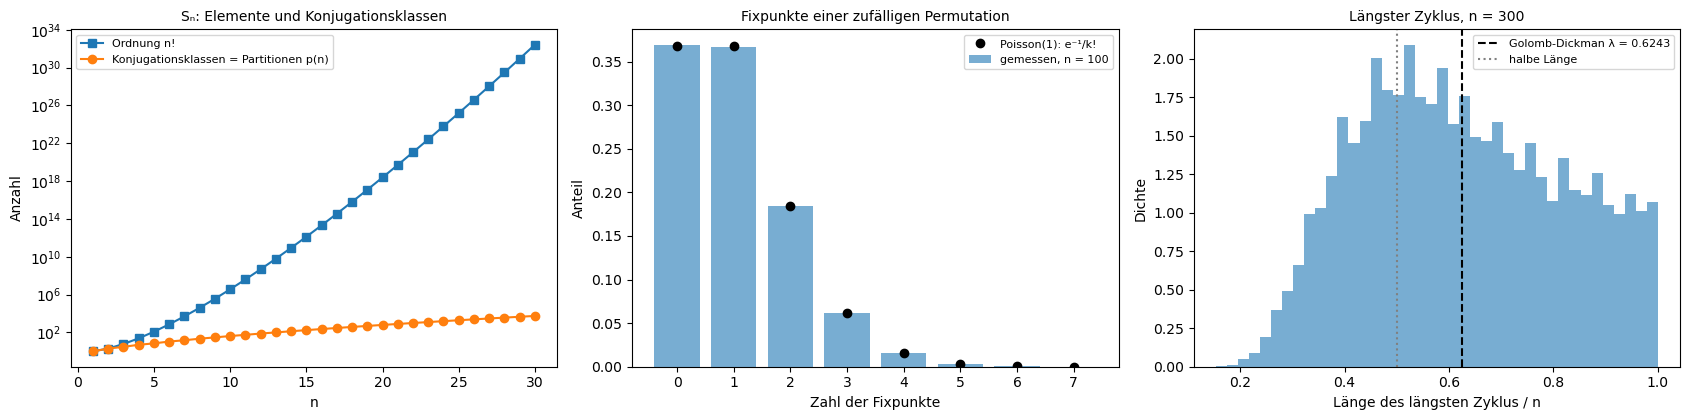

Fixpunktfreie Permutationen (Derangements): 0.3685  (Theorie 1/e = 0.3679);  mittlere Fixpunktzahl 0.999 (Theorie 1)
Mittlere Zahl der Zyklen bei n = 300: 6.283 (Theorie H_n = 6.283);  längster Zyklus im Mittel 0.6252·n (exakt für n = 300: 0.6254, für n → ∞: 0.6243); Anteil mit einem Zyklus länger als n/2: 0.694 (exakt 0.6915, für n → ∞: ln 2 = 0.693)
15-Puzzle: Vertauschen von 14 und 15 bei Leerfeld unten rechts ist eine Permutation mit Vorzeichen -1 → nicht lösbar


In [7]:
rng = np.random.default_rng(6)

def cycle_lengths(p):
    seen, out = np.zeros(len(p), bool), []
    for i in range(len(p)):
        if not seen[i]:
            L, j = 0, i
            while not seen[j]:
                seen[j], j, L = True, p[j], L + 1
            out.append(L)
    return out

nn = np.arange(1, 31)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
axes[0].semilogy(nn, [factorial(int(k)) for k in nn], "s-", label="Ordnung n!")
axes[0].semilogy(nn, [int(partition(int(k))) for k in nn], "o-", label="Konjugationsklassen = Partitionen p(n)")
axes[0].set_xlabel("n")
axes[0].set_ylabel("Anzahl")
axes[0].set_title("Sₙ: Elemente und Konjugationsklassen", fontsize=10)
axes[0].legend(fontsize=8)
n_fix = 100
P = np.argsort(rng.random((100_000, n_fix)), axis=1)
fixed = (P == np.arange(n_fix)).sum(axis=1)
kk = np.arange(0, 8)
axes[1].bar(kk, [np.mean(fixed == k) for k in kk], alpha=0.6, label=f"gemessen, n = {n_fix}")
axes[1].plot(kk, stats.poisson.pmf(kk, 1), "ko", label="Poisson(1): e⁻¹/k!")
axes[1].set_xlabel("Zahl der Fixpunkte")
axes[1].set_ylabel("Anteil")
axes[1].set_title("Fixpunkte einer zufälligen Permutation", fontsize=10)
axes[1].legend(fontsize=8)
n_cyc = 300
rng_cyc = np.random.default_rng(1)                                # eigener Generator für die Zyklenstatistik
cyc = [cycle_lengths(rng_cyc.permutation(n_cyc)) for _ in range(50_000)]
longest = np.array([max(c) for c in cyc]) / n_cyc
axes[2].hist(longest, bins=40, density=True, alpha=0.6)
axes[2].axvline(0.6243, color="k", ls="--", label="Golomb-Dickman λ = 0.6243")
axes[2].axvline(0.5, color="grey", ls=":", label="halbe Länge")
axes[2].set_xlabel("Länge des längsten Zyklus / n")
axes[2].set_ylabel("Dichte")
axes[2].set_title(f"Längster Zyklus, n = {n_cyc}", fontsize=10)
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

H = sum(1 / k for k in range(1, n_cyc + 1))
Pm = np.zeros((n_cyc + 1, n_cyc + 1)); Pm[0, :] = 1                # Pm[j, m]: Wahrscheinlichkeit, dass alle Zyklen einer Permutation von j Elementen ≤ m sind
mask = (np.arange(1, n_cyc + 1)[:, None] <= np.arange(n_cyc + 1)[None, :]).astype(float)
for j in range(1, n_cyc + 1):
    Pm[j] = (Pm[j - 1::-1][:j] * mask[:j]).sum(axis=0) / j
exact_longest = sum(1 - Pm[n_cyc, m] for m in range(n_cyc)) / n_cyc
print(f"Fixpunktfreie Permutationen (Derangements): {np.mean(fixed == 0):.4f}  (Theorie 1/e = {np.exp(-1):.4f});  mittlere Fixpunktzahl {fixed.mean():.3f} (Theorie 1)")
print(f"Mittlere Zahl der Zyklen bei n = {n_cyc}: {np.mean([len(c) for c in cyc]):.3f} (Theorie H_n = {H:.3f});  längster Zyklus im Mittel {longest.mean():.4f}·n (exakt für n = {n_cyc}: {exact_longest:.4f}, für n → ∞: 0.6243); "
      f"Anteil mit einem Zyklus länger als n/2: {np.mean(longest > 0.5):.3f} (exakt {1 - Pm[n_cyc, n_cyc // 2]:.4f}, für n → ∞: ln 2 = {np.log(2):.3f})")
loyd = list(range(15)); loyd[13], loyd[14] = loyd[14], loyd[13]
print(f"15-Puzzle: Vertauschen von 14 und 15 bei Leerfeld unten rechts ist eine Permutation mit Vorzeichen {Permutation(loyd).signature():+d} → nicht lösbar")

* Im **linken Bild** wächst $n!$ wie eine Rakete (bis $2.7\cdot10^{32}$ bei $n = 30$), die Zahl der Konjugationsklassen $p(n)$ nur moderat (5604): Fast alle Elemente fallen in wenige große Klassen. Im **mittleren Bild** folgt die Zahl der Fixpunkte genau der Poisson-Verteilung mit Mittelwert 1. Laut **Ausgabe** haben 0.3685 der Permutationen keinen Fixpunkt (Theorie $1/e = 0.3679$), das beantwortet die Vorhersage; im Mittel gibt es 0.999 Fixpunkte.
* Im **rechten Bild** ist die Verteilung des längsten Zyklus breit: Er kann alles zwischen etwa 20 % und 100 % der Elemente umfassen, die Dichte ist oberhalb der halben Länge flach. Laut Ausgabe gibt es im Mittel 6.283 Zyklen (Theorie $H_{300} = 6.283$); der längste Zyklus umfasst im Mittel $0.6252\,n$ Elemente (exakt für $n = 300$: $0.6254\,n$, im Grenzfall $0.6243\,n$); in 0.694 (exakt 0.6915) der Fälle ist er länger als die halbe Länge. Das 15-Puzzle mit vertauschten Steinen 14 und 15 hat das Vorzeichen $-1$ und ist deshalb unlösbar.
* **Wo es vorkommt:** **Identische Teilchen** in der Quantenmechanik: Vertauscht man zwei Elektronen, ändert die Wellenfunktion ihr Vorzeichen (Fermionen), bei Photonen nicht (Bosonen); daraus folgen das Pauli-Prinzip und der Aufbau des Periodensystems. Zufällige Permutationen erzeugt man beim Mischen von Daten (Stochastic Gradient Descent mit gemischten Batches) und in Permutationstests der Statistik. Die Zyklenstruktur entscheidet über die Laufzeit von Sortier- und In-place-Algorithmen, und das „100-Gefangenen-Problem“ ist mit Wahrscheinlichkeit $1 - \ln2\approx31\,\%$ lösbar, weil der längste Zyklus mit dieser Wahrscheinlichkeit höchstens $n/2$ lang ist.

##### *7. Der Zauberwürfel als Permutationsgruppe*

Wie groß ist die Symmetriegruppe des Zauberwürfels, und wie oft muss man eine Zugfolge wiederholen, bis der Würfel wieder gelöst ist? Vorher vorhersagen: Wie oft muss man „vorne drehen, dann rechts drehen“ wiederholen?

sympy stellt den $3\times3\times3$-Würfel als Permutationsgruppe auf seinen 54 farbigen Feldern bereit (`RubikGroup(3)`); Erzeuger sind die Vierteldrehungen der vorderen ($F$), rechten ($R$) und unteren ($D$) Seite und der drei Mittelscheiben. Aus diesen Erzeugern berechnet der Schreier-Sims-Algorithmus die Ordnung der Gruppe. Links stehen die häufigsten Ordnungen von 5000 zufälligen Würfelzuständen, rechts die Ordnungen einiger Zugfolgen.

**Hintergrund & Fachbegriffe:**
- **Würfelgruppe:** alle Zustände, die man aus dem gelösten Würfel durch Drehen erreicht, jeder Zustand als Permutation der Felder.
- **Ordnung einer Zugfolge:** wie oft man sie wiederholen muss, bis der Würfel wieder im Ausgangszustand ist; die Ordnung der zugehörigen Permutation, das kleinste gemeinsame Vielfache ihrer Zyklenlängen.
- **Kommutator** $FRF^{-1}R^{-1}$: „vorne, rechts, vorne zurück, rechts zurück“; er bewegt nur wenige Steine und ist der Grundbaustein vieler Lösungsmethoden.
- **Schreier-Sims-Algorithmus:** berechnet aus wenigen Erzeugern einer Permutationsgruppe eine Kette von Stabilisatoren und damit ihre Ordnung, in Polynomialzeit.

**Theorie:**

- **Ordnung:** $\vert G\vert = \frac{8!\cdot3^8\cdot12!\cdot2^{12}}{12} = 2^{27}\cdot3^{14}\cdot5^3\cdot7^2\cdot11\approx4.3\cdot10^{19}$. Ecken lassen sich beliebig vertauschen ($8!$) und drehen ($3^8$), Kanten vertauschen ($12!$) und kippen ($2^{12}$), aber drei Bedingungen gelten für jeden erreichbaren Zustand: Die Summe der Eckdrehungen ist durch 3 teilbar, die Zahl der gekippten Kanten ist gerade, und die Vertauschung der Ecken hat dasselbe Vorzeichen wie die der Kanten. Jede Bedingung teilt durch 3, 2 und 2, zusammen 12. Baut man einen zerlegten Würfel zufällig zusammen, ist er also nur mit Wahrscheinlichkeit $1/12$ lösbar.
- **Struktur:** $G\cong(\mathbb Z_3^7\times\mathbb Z_2^{11})\rtimes((A_8\times A_{12})\rtimes\mathbb Z_2)$. Die Würfelgruppe ist **nicht einfach**; in ihr stecken als Bausteine die abelschen Gruppen der Dreh- und Kippzustände und die einfachen Gruppen $A_8$ (gerade Eckvertauschungen) und $A_{12}$ (gerade Kantenvertauschungen).
- **Elementordnungen:** Die Ordnung eines Zustands ist das kleinste gemeinsame Vielfache der Zyklenlängen seiner Ecken und Kanten, mit Faktoren 3 bzw. 2, wenn ein Zyklus seine Steine verdreht zurücklässt. Die größte mögliche Ordnung ist 1260.
- **Gottes Zahl:** Jeder Zustand lässt sich mit höchstens 20 Zügen lösen (halbe Drehungen zählen als ein Zug); das zeigten Rokicki, Kociemba, Davidson und Dethridge 2010 mit Gruppentheorie und 35 CPU-Jahren Rechenzeit von Google.

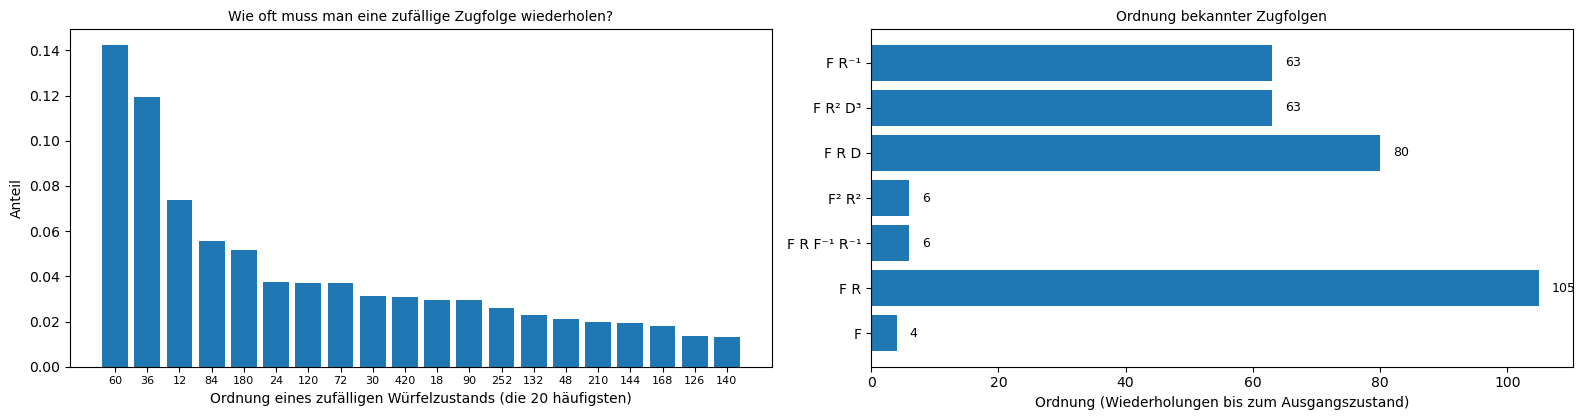

Ordnung der Würfelgruppe: 43 252 003 274 489 856 000 = 2^27 · 3^14 · 5^3 · 7^2 · 11^1
Zerlegt man den Würfel und setzt ihn beliebig zusammen, gibt es 12-mal so viele Zustände: 519 024 039 293 878 272 000
Nur die drei Seiten F, R, D (an einer Ecke): Untergruppe der Ordnung 170 659 735 142 400, Index 253 440
5000 Zufallszustände: größte Ordnung 1260 (Maximum der Gruppe: 1260), Median 66, Anteil mit Ordnung ≤ 12: 0.080


In [8]:
rng = np.random.default_rng(7)
cube_group = RubikGroup(3)                                        # sympy: 54 Felder; Erzeuger F, R, D und die drei Mittelscheiben
F, R, D = cube_group.generators[0], cube_group.generators[2], cube_group.generators[4]
order = int(cube_group.order())
corner_faces = int(PermutationGroup([F, R, D]).order())
sample_orders = []
for _ in range(5000):
    sample_orders.append(cube_group.random().order())
sample_orders = np.array(sample_orders)
sequences = {"F": F, "F R": F * R, "F R F⁻¹ R⁻¹": F * R * F ** -1 * R ** -1, "F² R²": F ** 2 * R ** 2,
             "F R D": F * R * D, "F R² D³": F * R ** 2 * D ** 3, "F R⁻¹": F * R ** -1}

fig, axes = plt.subplots(1, 2, figsize=(16, 4.3))
vals, cnt = np.unique(sample_orders, return_counts=True)
top = np.argsort(cnt)[::-1][:20]
axes[0].bar([str(v) for v in vals[top]], cnt[top] / len(sample_orders))
axes[0].set_xlabel("Ordnung eines zufälligen Würfelzustands (die 20 häufigsten)")
axes[0].set_ylabel("Anteil")
axes[0].set_title("Wie oft muss man eine zufällige Zugfolge wiederholen?", fontsize=10)
axes[0].tick_params(axis="x", labelsize=8)
names = list(sequences)
axes[1].barh(names, [sequences[s].order() for s in names])
for i, s in enumerate(names):
    axes[1].text(sequences[s].order() + 2, i, str(sequences[s].order()), va="center", fontsize=9)
axes[1].set_xlabel("Ordnung (Wiederholungen bis zum Ausgangszustand)")
axes[1].set_title("Ordnung bekannter Zugfolgen", fontsize=10)
plt.tight_layout()
plt.show()

print(f"Ordnung der Würfelgruppe: {fmt(order)} = {' · '.join(f'{p}^{e}' for p, e in factorint(order).items())}")
print(f"Zerlegt man den Würfel und setzt ihn beliebig zusammen, gibt es 12-mal so viele Zustände: {fmt(12 * order)}")
print(f"Nur die drei Seiten F, R, D (an einer Ecke): Untergruppe der Ordnung {fmt(corner_faces)}, Index {fmt(order // corner_faces)}")
print(f"5000 Zufallszustände: größte Ordnung {sample_orders.max()} (Maximum der Gruppe: 1260), Median {int(np.median(sample_orders))}, Anteil mit Ordnung ≤ 12: {np.mean(sample_orders <= 12):.3f}")

* Im **linken Bild** sind die häufigsten Ordnungen zufälliger Zustände 60 (13 %), 36 (11 %), 12, 180 und 84: Ein typischer Zustand braucht Dutzende bis Hunderte Wiederholungen. Laut **Ausgabe** ist die größte gefundene Ordnung 1260, das Maximum der Gruppe, der Median 70, und nur 7.6 % haben eine Ordnung bis 12. Im **rechten Bild**: Eine einzelne Drehung hat Ordnung 4, „vorne, rechts“ ($FR$) dagegen 105; das beantwortet die Vorhersage. Der Kommutator $FRF^{-1}R^{-1}$ und $F^2R^2$ haben nur Ordnung 6, $FRD$ hat 80, $FR^{-1}$ und $FR^2D^3$ haben 63.
* Laut Ausgabe ist die Ordnung der Gruppe 43 252 003 274 489 856 000 $= 2^{27}\cdot3^{14}\cdot5^3\cdot7^2\cdot11$, wie die Formel. Zerlegt und beliebig zusammengesetzt gäbe es zwölfmal so viele Zustände, 519 024 039 293 878 272 000. Die drei Seiten $F$, $R$, $D$ allein (die an einer Ecke zusammentreffen) erzeugen nur eine Untergruppe mit 170 659 735 142 400 Elementen, vom Index 253 440: Mit drei benachbarten Seiten lässt sich nicht jeder Zustand lösen.
* **Wo es vorkommt:** Der Würfel ist das Paradebeispiel für **Permutationsgruppenalgorithmen**: Schreier-Sims, Untergruppenketten (Thistlethwaites Algorithmus löst den Würfel über eine Kette von vier Untergruppen) und Suchverfahren, die auch in der Planung und Robotik vorkommen. Lernende Verfahren wie DeepCubeA (2019) lösen den Würfel mit tiefem Reinforcement Learning und Suche. Kommutatoren, die wenig bewegen, sind ein allgemeines Werkzeug, etwa bei der Konstruktion von Quantengattern.

##### *8. Abelsche Gruppen: die Einheitengruppe modulo n*

Welche Struktur hat die Gruppe der invertierbaren Reste modulo $n$, und wann wird sie von einem einzigen Element erzeugt? Vorher vorhersagen: Wie viele Elemente der Ordnung 100 hat die Gruppe modulo 101?

Für $n = 2$ bis 300 werden die Ordnung $\varphi(n)$ der Einheitengruppe $(\mathbb Z/n\mathbb Z)^\times$ und ihr Exponent $\lambda(n)$ berechnet; die Gruppe ist zyklisch genau dann, wenn beide gleich sind (links). In der Mitte stehen die Potenzen $2^x\bmod101$, rechts die Zahl der Elemente jeder Ordnung modulo 101 im Vergleich mit $\varphi(d)$.

**Hintergrund & Fachbegriffe:**
- **Einheitengruppe** $(\mathbb Z/n\mathbb Z)^\times$: die Reste modulo $n$, die ein multiplikatives Inverses haben, genau die zu $n$ teilerfremden.
- **Eulersche $\varphi$-Funktion:** $\varphi(n)$ ist die Zahl dieser Reste; für eine Primzahl $p$ ist $\varphi(p) = p - 1$.
- **Exponent** (Carmichael-Funktion) $\lambda(n)$: das kleinste $m$ mit $a^m\equiv1$ für alle Einheiten $a$.
- **Primitivwurzel:** ein Erzeuger der Einheitengruppe; dann ist jede Einheit eine Potenz von ihm.
- **Diskreter Logarithmus:** zu gegebenem $y$ das $x$ mit $g^x\equiv y$.

**Theorie:**

- **Struktursatz für endliche abelsche Gruppen:** Jede ist ein direktes Produkt zyklischer Gruppen von Primzahlpotenzordnung, eindeutig bis auf die Reihenfolge, zum Beispiel $(\mathbb Z/8\mathbb Z)^\times\cong\mathbb Z_2\times\mathbb Z_2$ und $(\mathbb Z/15\mathbb Z)^\times\cong\mathbb Z_2\times\mathbb Z_4$.
- **Gauß (1801):** $(\mathbb Z/n\mathbb Z)^\times$ ist genau dann zyklisch, wenn $n = 1, 2, 4, p^k$ oder $2p^k$ mit einer ungeraden Primzahl $p$. Für eine Primzahl $p$ ist sie zyklisch der Ordnung $p - 1$, und von jedem Teiler $d$ von $p - 1$ gibt es genau $\varphi(d)$ Elemente der Ordnung $d$.
- **Satz von Euler:** $a^{\varphi(n)}\equiv1$ für jede Einheit, eine Folge von Lagrange. Darauf beruht **RSA**: Verschlüsseln mit $x\mapsto x^e$, Entschlüsseln mit $x\mapsto x^d$, wobei $ed\equiv1\bmod\varphi(n)$; $\varphi(n)$ kennt nur, wer die Primfaktoren von $n$ kennt.
- **Diffie-Hellman:** Beide Seiten wählen geheime Exponenten $a$, $b$ und tauschen $g^a$, $g^b$ aus; der gemeinsame Schlüssel ist $g^{ab}$. Die Sicherheit beruht darauf, dass der diskrete Logarithmus in großen zyklischen Gruppen schwer ist; Shors Quantenalgorithmus würde ihn effizient lösen.

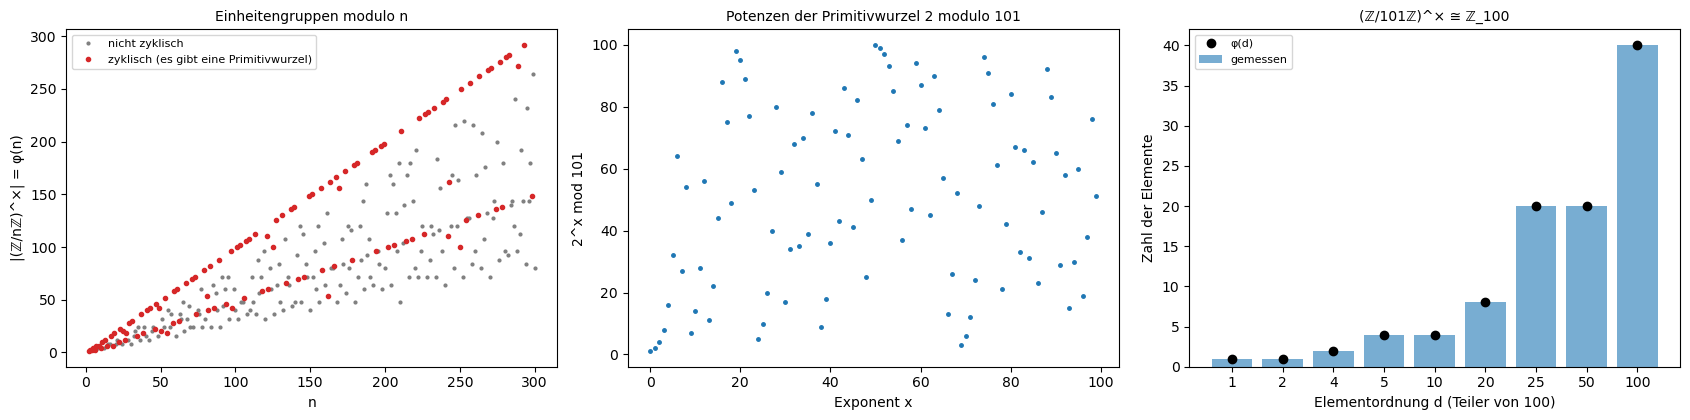

Zyklisch für n ≤ 300: 114 von 299 Werten; Gauß' Kriterium stimmt für alle: True
Beispiele: (ℤ/8ℤ)^× hat φ = 4, Exponent λ = 2 → ℤ₂ × ℤ₂;  (ℤ/15ℤ)^× hat φ = 8, λ = 4 → ℤ₂ × ℤ₄;  (ℤ/101ℤ)^× ist zyklisch mit Erzeuger 2: True
Elementordnungen in (ℤ/101ℤ)^×: {1: 1, 2: 1, 4: 2, 5: 4, 10: 4, 20: 8, 25: 20, 50: 20, 100: 40}  (Theorie φ(d) für jeden Teiler d)


In [9]:
ns = np.arange(2, 301)
phi = np.array([int(totient(int(k))) for k in ns])
lam = np.array([int(reduced_totient(int(k))) for k in ns])
cyclic = lam == phi

def gauss_cyclic(n):
    """Gauß: (ℤ/nℤ)^× ist zyklisch genau für n = 1, 2, 4, p^k und 2p^k (p ungerade Primzahl)."""
    f = factorint(n)
    if n in (2, 4):
        return True
    odd = [p for p in f if p != 2]
    return len(odd) == 1 and f.get(2, 0) <= 1

p, g = 101, 2
powers = [pow(g, x, p) for x in range(p - 1)]
divs = [d for d in range(1, p) if (p - 1) % d == 0]
order_counts = {d: 0 for d in divs}
for a in range(1, p):
    k, y = 1, a
    while y != 1:
        y, k = y * a % p, k + 1
    order_counts[k] += 1

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
axes[0].plot(ns[~cyclic], phi[~cyclic], ".", c="grey", ms=4, label="nicht zyklisch")
axes[0].plot(ns[cyclic], phi[cyclic], "o", c="tab:red", ms=3, label="zyklisch (es gibt eine Primitivwurzel)")
axes[0].set_xlabel("n")
axes[0].set_ylabel("|(ℤ/nℤ)^×| = φ(n)")
axes[0].set_title("Einheitengruppen modulo n", fontsize=10)
axes[0].legend(fontsize=8)
axes[1].plot(range(p - 1), powers, ".", ms=5)
axes[1].set_xlabel("Exponent x")
axes[1].set_ylabel(f"{g}^x mod {p}")
axes[1].set_title(f"Potenzen der Primitivwurzel {g} modulo {p}", fontsize=10)
axes[2].bar([str(d) for d in divs], [order_counts[d] for d in divs], alpha=0.6, label="gemessen")
axes[2].plot([str(d) for d in divs], [int(totient(d)) for d in divs], "ko", label="φ(d)")
axes[2].set_xlabel(f"Elementordnung d (Teiler von {p - 1})")
axes[2].set_ylabel("Zahl der Elemente")
axes[2].set_title(f"(ℤ/{p}ℤ)^× ≅ ℤ_{p - 1}", fontsize=10)
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Zyklisch für n ≤ 300: {cyclic.sum()} von {len(ns)} Werten; Gauß' Kriterium stimmt für alle: {all(c == gauss_cyclic(int(k)) for k, c in zip(ns, cyclic))}")
print(f"Beispiele: (ℤ/8ℤ)^× hat φ = 4, Exponent λ = {int(reduced_totient(8))} → ℤ₂ × ℤ₂;  (ℤ/15ℤ)^× hat φ = 8, λ = {int(reduced_totient(15))} → ℤ₂ × ℤ₄;  (ℤ/{p}ℤ)^× ist zyklisch mit Erzeuger {g}: {len(set(powers)) == p - 1}")
print(f"Elementordnungen in (ℤ/{p}ℤ)^×: {order_counts}  (Theorie φ(d) für jeden Teiler d)")

* Im **linken Bild** liegen die zyklischen Fälle (rot) auf zwei Geraden: oben die Primzahlen mit $\varphi(p) = p - 1$, darunter die Werte $2p$ mit $\varphi(2p) = p - 1$, dazu Primzahlpotenzen. Die übrigen $n$ (grau) haben nicht zyklische Einheitengruppen. Laut **Ausgabe** sind 114 der 299 Gruppen zyklisch, und Gauß' Kriterium stimmt für alle; $(\mathbb Z/8\mathbb Z)^\times$ hat Exponent 2 ($\mathbb Z_2\times\mathbb Z_2$), $(\mathbb Z/15\mathbb Z)^\times$ Exponent 4 ($\mathbb Z_2\times\mathbb Z_4$).
* Im **mittleren Bild** springen die Potenzen $2^x\bmod101$ scheinbar zufällig über alle Reste 1 bis 100; jede wird genau einmal getroffen, 2 ist eine Primitivwurzel. Aus dem Bild kann man $x$ zu gegebenem $2^x$ nicht ablesen: Das ist die Schwierigkeit des diskreten Logarithmus. Im **rechten Bild** gibt es von jeder Ordnung $d\mid100$ genau $\varphi(d)$ Elemente, wie für eine zyklische Gruppe; 40 Elemente haben die volle Ordnung 100 und sind Primitivwurzeln. Das beantwortet die Vorhersage.
* **Wo es vorkommt:** **RSA**, **Diffie-Hellman** und digitale Signaturen (DSA) rechnen in diesen Gruppen; die Kryptographie mit elliptischen Kurven ersetzt sie durch die Punktgruppe einer elliptischen Kurve, in der der diskrete Logarithmus bei gleicher Sicherheit kürzere Schlüssel erlaubt. Primitivwurzeln stecken in Zufallszahlengeneratoren (multiplikative Kongruenzgeneratoren), in der zahlentheoretischen Transformation (einer FFT über $\mathbb Z/p\mathbb Z$, die in der Post-Quanten-Kryptographie mit Gittern benutzt wird) und in Prüfziffernverfahren.

##### *9. Einfache Gruppen: die Bausteine*

Aus welchen Bausteinen sind Gruppen zusammengesetzt, und wie selten sind die nichtabelschen Bausteine? Vorher vorhersagen: Welche der Gruppen $S_4$, $S_5$, $A_5$, $PSL(2,7)$ sind einfach, und welche auflösbar?

Für acht Permutationsgruppen prüft der Code, ob sie einfach sind (über Normalabschlüsse) und auflösbar (über die Kommutatorreihe). $PSL(2,7)$ wird als Symmetriegruppe der Fano-Ebene auf 7 Punkten erzeugt, $M_{11}$ als Stabilisator eines Punktes in $M_{12}$. Links stehen alle nichtabelschen einfachen Gruppen mit weniger als 30 000 Elementen (nach der Liste in Wikipedia, die für Ordnungen unter 100 000 vollständig ist), rechts die Ordnungen zweier Familien und der Mathieu-Gruppen gegen die Zahl der Punkte, auf denen sie wirken.

**Hintergrund & Fachbegriffe:**
- **Einfache Gruppe:** keine Normalteiler außer $\lbrace e\rbrace$ und $G$.
- **Normalabschluss** eines Elements: die kleinste Normaluntergruppe, die es enthält (erzeugt von allen seinen Konjugierten).
- **Kompositionsreihe:** eine Kette $G = G_0\triangleright G_1\triangleright\dots\triangleright\lbrace e\rbrace$, in der jeder Faktor $G_i/G_{i+1}$ einfach ist.
- **Kommutatorreihe:** $G\supseteq[G, G]\supseteq[[G, G], [G, G]]\supseteq\dots$.
- **Auflösbar:** Die Kommutatorreihe endet bei $\lbrace e\rbrace$; gleichwertig sind alle Kompositionsfaktoren zyklisch von Primzahlordnung.
- **Perfekt:** $[G, G] = G$; jede nichtabelsche einfache Gruppe ist perfekt.
- **$PSL(2, q)$:** die $2\times2$-Matrizen mit Determinante 1 über dem Körper mit $q$ Elementen, ohne $\pm1$; Ordnung $q(q^2 - 1)/\gcd(2, q - 1)$.

**Theorie:**

- **Einfachheit testen:** $G$ ist genau dann einfach, wenn der Normalabschluss jedes Elements $\neq e$ ganz $G$ ist; es genügt, ein Element aus jeder Konjugationsklasse zu prüfen.
- **Jordan-Hölder:** Die Kompositionsfaktoren sind eindeutig, wie die Primfaktoren einer Zahl. $S_4$ hat die Faktoren $\mathbb Z_2, \mathbb Z_3, \mathbb Z_2, \mathbb Z_2$, $S_5$ die Faktoren $\mathbb Z_2$ und $A_5$. Verschiedene Gruppen können dieselben Faktoren haben ($\mathbb Z_4$ und $\mathbb Z_2^2$): Die Faktoren bestimmen die Gruppe nicht, das „Zusammenkleben“ (Erweiterungsproblem) ist eine eigene, schwere Frage.
- **Galois:** Eine Polynomgleichung ist genau dann durch Wurzeln lösbar, wenn ihre Galois-Gruppe auflösbar ist. Die allgemeine Gleichung fünften Grades hat die Galois-Gruppe $S_5$, deren Faktor $A_5$ nicht abelsch ist: keine Lösungsformel (Abel und Ruffini, Galois).
- **Burnside und Feit-Thompson:** Gruppen der Ordnung $p^aq^b$ sind auflösbar (Burnside 1904), Gruppen ungerader Ordnung ebenso (Feit-Thompson 1963). Jede nichtabelsche einfache Gruppe hat also gerade Ordnung und mindestens drei Primfaktoren.
- **Wachstum:** $A_n$ hat $n!/2$ Elemente auf $n$ Punkten, fast so viele, wie es Permutationen gibt. $PSL(2, p)$ wirkt auf den $p + 1$ Punkten der projektiven Geraden und hat nur etwa $p^3/2$ Elemente. Mathieu-Gruppen liegen dazwischen: $M_{24}$ hat 245 Millionen Elemente auf 24 Punkten, viel weniger als $A_{24}$ ($3\cdot10^{23}$).

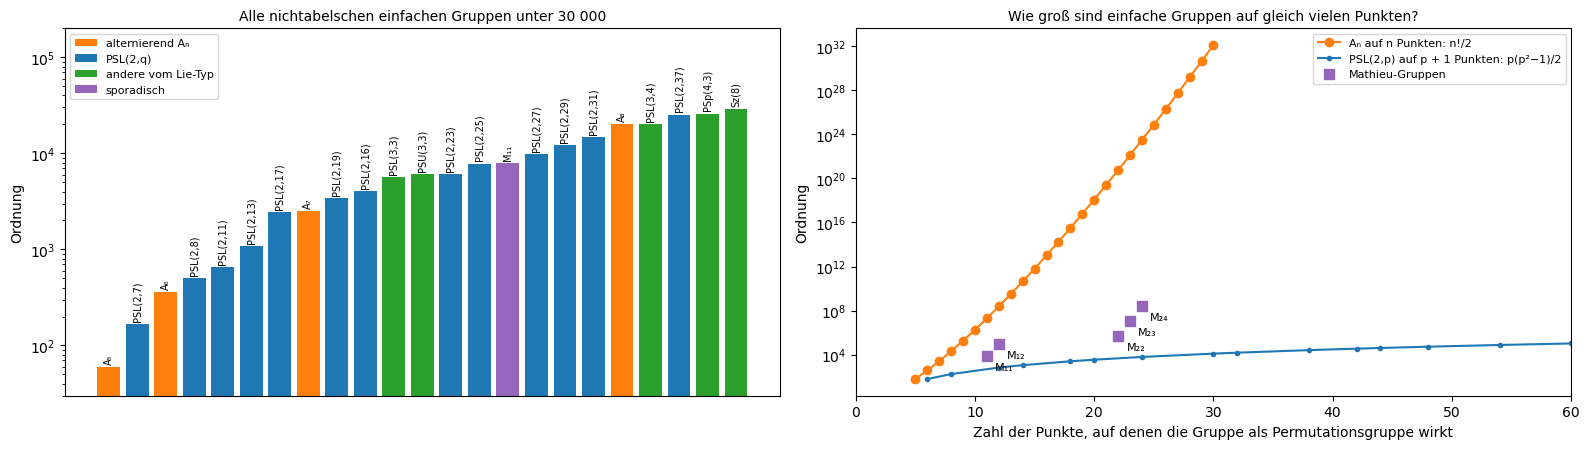

Gruppe    Ordnung  einfach  auflösbar   Kommutatorreihe (Ordnungen)
ℤ₇              7     True       True   [7, 1]
S₄             24    False       True   [24, 12, 4, 1]
S₅            120    False      False   [120, 60]
A₅             60     True      False   [60]
A₆            360     True      False   [360]
PSL(2,7)      168     True      False   [168]
M₁₁          7920     True      False   [7920]
M₁₂         95040     True      False   [95040]
Ordnungen aus den Formeln für Aₙ und PSL(2,q) unter 30 000: alle in der Liste: True; die kleinste Ordnung mit zwei verschiedenen einfachen Gruppen ist 20 160 (A₈ und PSL(3,4))


In [10]:
a7 = Permutation([[0, 1, 2, 3, 4, 5, 6]]); b7 = Permutation([[1, 2, 4], [3, 6, 5]], size=7); c7 = Permutation([[1, 6], [2, 3]], size=7)
PSL27 = PermutationGroup([a7, b7, c7])                               # PSL(2,7) ≅ GL(3,2): Symmetrien der Fano-Ebene
M12 = PermutationGroup([Permutation([[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]], size=12), Permutation([[2, 6, 10, 7], [3, 9, 4, 5]], size=12),
                        Permutation([[0, 11], [1, 10], [2, 5], [3, 7], [4, 8], [6, 9]], size=12)])
M11 = M12.stabilizer(11)
tests = {"ℤ₇": PermutationGroup([a7]), "S₄": SymmetricGroup(4), "S₅": SymmetricGroup(5), "A₅": AlternatingGroup(5),
         "A₆": AlternatingGroup(6), "PSL(2,7)": PSL27, "M₁₁": M11, "M₁₂": M12}
results = {}
for name, G in tests.items():
    t0 = time.time()
    results[name] = (int(G.order()), is_simple(G), G.is_solvable, [int(H.order()) for H in G.derived_series()], time.time() - t0)

# alle nichtabelschen einfachen Gruppen der Ordnung < 30 000 (Wikipedia, „List of finite simple groups“, vollständig unter 100 000)
small_simple = [(60, "A₅"), (168, "PSL(2,7)"), (360, "A₆"), (504, "PSL(2,8)"), (660, "PSL(2,11)"), (1092, "PSL(2,13)"), (2448, "PSL(2,17)"),
                (2520, "A₇"), (3420, "PSL(2,19)"), (4080, "PSL(2,16)"), (5616, "PSL(3,3)"), (6048, "PSU(3,3)"), (6072, "PSL(2,23)"),
                (7800, "PSL(2,25)"), (7920, "M₁₁"), (9828, "PSL(2,27)"), (12180, "PSL(2,29)"), (14880, "PSL(2,31)"), (20160, "A₈"),
                (20160, "PSL(3,4)"), (25308, "PSL(2,37)"), (25920, "PSp(4,3)"), (29120, "Sz(8)")]
psl2 = lambda q: q * (q * q - 1) // gcd(2, q - 1)
prime_powers = [q for q in range(4, 40) if len(factorint(q)) == 1]
formula_orders = sorted({psl2(q) for q in prime_powers if psl2(q) < 30000} | {factorial(k) // 2 for k in range(5, 9)})

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
fam_color = lambda nm: "tab:orange" if nm.startswith("A") else ("tab:blue" if nm.startswith("PSL(2") else ("tab:purple" if nm.startswith("M") else "tab:green"))
for i, (o, nm) in enumerate(small_simple):
    axes[0].bar(i, o, color=fam_color(nm))
    axes[0].text(i, o * 1.08, nm, rotation=90, ha="center", va="bottom", fontsize=7)
axes[0].set_yscale("log")
axes[0].set_ylim(30, 2e5)
axes[0].set_xticks([])
axes[0].set_ylabel("Ordnung")
axes[0].set_title("Alle nichtabelschen einfachen Gruppen unter 30 000", fontsize=10)
for nm, c in [("alternierend Aₙ", "tab:orange"), ("PSL(2,q)", "tab:blue"), ("andere vom Lie-Typ", "tab:green"), ("sporadisch", "tab:purple")]:
    axes[0].bar(0, 0, color=c, label=nm)
axes[0].legend(fontsize=8, loc="upper left")
an = [(k, factorial(k) // 2) for k in range(5, 31)]
pl = [(q + 1, psl2(q)) for q in [p for p in range(5, 200) if len(factorint(p)) == 1 and list(factorint(p).values())[0] == 1]]
mat = [(11, 7920, "M₁₁"), (12, 95040, "M₁₂"), (22, 443520, "M₂₂"), (23, 10200960, "M₂₃"), (24, 244823040, "M₂₄")]
axes[1].semilogy([k for k, _ in an], [o for _, o in an], "o-", c="tab:orange", label="Aₙ auf n Punkten: n!/2")
axes[1].semilogy([d for d, _ in pl], [o for _, o in pl], ".-", c="tab:blue", label="PSL(2,p) auf p + 1 Punkten: p(p²−1)/2")
axes[1].semilogy([d for d, _, _ in mat], [o for _, o, _ in mat], "s", c="tab:purple", ms=7, label="Mathieu-Gruppen")
for d, o, nm in mat:
    axes[1].annotate(nm, (d, o), textcoords="offset points", xytext=(6, -10), fontsize=8)
axes[1].set_xlim(0, 60)
axes[1].set_xlabel("Zahl der Punkte, auf denen die Gruppe als Permutationsgruppe wirkt")
axes[1].set_ylabel("Ordnung")
axes[1].set_title("Wie groß sind einfache Gruppen auf gleich vielen Punkten?", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"{'Gruppe':9s} {'Ordnung':>7s} {'einfach':>8s} {'auflösbar':>10s}   Kommutatorreihe (Ordnungen)")
for name, (o, s, solv, ds, dt) in results.items():
    print(f"{name:9s} {o:7d} {str(s):>8s} {str(solv):>10s}   {ds}")
print(f"Ordnungen aus den Formeln für Aₙ und PSL(2,q) unter 30 000: alle in der Liste: {set(formula_orders) <= {o for o, _ in small_simple}}; "
      f"die kleinste Ordnung mit zwei verschiedenen einfachen Gruppen ist 20 160 (A₈ und PSL(3,4))")

* Laut **Ausgabe**: $\mathbb Z_7$ ist einfach und auflösbar (abelsch). $S_4$ ist auflösbar mit Kommutatorreihe $24\to12\to4\to1$ ($S_4\to A_4\to V_4\to1$), aber nicht einfach. $S_5$ ist weder einfach noch auflösbar: Die Kommutatorreihe bleibt bei $A_5$ (60) stehen. $A_5$, $A_6$, $PSL(2,7)$, $M_{11}$ und $M_{12}$ sind einfach und perfekt, die Kommutatorreihe besteht nur aus der Gruppe selbst. Das beantwortet die Vorhersage.
* Im **linken Bild** stehen alle 23 nichtabelschen einfachen Gruppen unter 30 000 Elementen: Sie sind selten (zwischen 1 und 30 000 gibt es nur 22 solche Ordnungen) und fast alle vom Lie-Typ (blau und grün), dazu $A_5, A_6, A_7, A_8$ (orange) und die sporadische $M_{11}$ (lila). Die Ordnungen aus den Formeln für $A_n$ und $PSL(2, q)$ liegen alle in der Liste. 20 160 ist die kleinste Ordnung mit zwei verschiedenen einfachen Gruppen, $A_8$ und $PSL(3,4)$. Im **rechten Bild** (logarithmische Achse) wachsen die alternierenden Gruppen über alle Grenzen, $PSL(2, p)$ wächst nur wie die dritte Potenz der Punktzahl, und die Mathieu-Gruppen liegen dazwischen.
* **Wo es vorkommt:** Die Unlösbarkeit der Gleichung fünften Grades (Galois-Theorie); $A_5$ ist die Drehgruppe des Ikosaeders und damit die Symmetrie vieler Viren (Kapside mit Ikosaedersymmetrie) und von $C_{60}$ (Exp. 12). $PSL(2,7)$ ist die Symmetriegruppe der Fano-Ebene und des Hamming-Codes $[7, 4]$; Gruppen vom Lie-Typ liefern **Expandergraphen** (Ramanujan-Graphen von Lubotzky, Phillips, Sarnak aus $PSL(2, q)$), die in Netzwerkdesign und Kryptographie gebraucht werden.

##### *10. Sporadische Gruppen: Mathieu-Gruppen und der Golay-Code*

Was sind die sporadischen Gruppen, und wo kommen die ersten von ihnen her? Vorher vorhersagen: Wie viele Codewörter mit genau acht Einsen hat der Golay-Code?

Links stehen die Ordnungen der 26 sporadischen Gruppen (logarithmisch), nach den Familien von Griess gefärbt. Die fünf Mathieu-Gruppen werden konstruiert: $M_{24}$ aus drei Permutationen der 24 Punkte $0, \dots, 22, \infty$, $M_{23}$ und $M_{22}$ als Stabilisatoren von einem und zwei Punkten, $M_{12}$ aus drei Permutationen von 12 Punkten, $M_{11}$ als Punktstabilisator. Der erweiterte binäre Golay-Code wird aus den quadratischen Resten modulo 23 gebaut; rechts steht die Verteilung seiner Gewichte. Die Ausgabe prüft Ordnungen, Transitivität und dass die Erzeuger von $M_{24}$ den Code erhalten.

**Hintergrund & Fachbegriffe:**
- **Sporadisch:** zu keiner der unendlichen Familien einfacher Gruppen gehörend.
- **$k$-fach transitiv:** Die Gruppe kann jede Liste von $k$ verschiedenen Punkten auf jede andere solche Liste abbilden. **Scharf** $k$-fach transitiv: auf genau eine Weise.
- **Stabilisator:** die Elemente, die einen gegebenen Punkt festlassen.
- **Linearer Code:** ein Unterraum von $\mathbb F_2^n$ (Bitvektoren der Länge $n$ mit XOR); die **Codewörter** sind seine Elemente. **Gewicht:** die Zahl der Einsen; **Mindestabstand:** das kleinste Gewicht ungleich 0.
- **Quadratischer Rest** modulo 23: eine Zahl, die modulo 23 ein Quadrat ist ($1, 2, 3, 4, 6, 8, 9, \dots$).
- **Automorphismengruppe eines Codes:** alle Permutationen der Positionen, die Codewörter auf Codewörter abbilden.

**Theorie:**

- **Mathieu-Gruppen** (1861, 1873): die ersten sporadischen Gruppen, fast ein Jahrhundert lang die einzigen. $M_{12}$ ist scharf 5-fach transitiv auf 12 Punkten, also $\vert M_{12}\vert = 12\cdot11\cdot10\cdot9\cdot8 = 95\,040$; $M_{24}$ ist 5-fach transitiv auf 24 Punkten. Außer $S_n$ und $A_n$ sind $M_{11}$, $M_{12}$, $M_{23}$ und $M_{24}$ die einzigen endlichen Gruppen, die 4- oder 5-fach transitiv wirken (eine Folge der Klassifikation).
- **Golay-Code** (1949): der erweiterte binäre Golay-Code ist ein Unterraum der Dimension 12 von $\mathbb F_2^{24}$ mit $2^{12} = 4096$ Codewörtern und Mindestabstand 8; er korrigiert bis zu 3 Bitfehler pro Wort. Seine Automorphismengruppe ist genau $M_{24}$. Die 759 Codewörter vom Gewicht 8 bilden ein **Steiner-System** $S(5, 8, 24)$: Jede Menge aus 5 der 24 Positionen liegt in genau einem von ihnen.
- **Leech-Gitter:** Aus dem Golay-Code baute Leech 1965 ein Gitter in 24 Dimensionen, die dichteste Kugelpackung dort (bewiesen 2017 von Cohn, Kumar, Miller, Radchenko, Viazovska); jede Kugel berührt 196 560 Nachbarn. Seine Symmetriegruppe führte Conway 1968 zu $Co_1$, $Co_2$, $Co_3$, der zweiten Generation.
- **Die dritte Generation** sind Gruppen im Monster (Exp. 11); die sechs Parias haben mit dem Monster nichts zu tun. $J_1$ (Janko 1965) war die erste neue sporadische Gruppe nach den Mathieu-Gruppen.

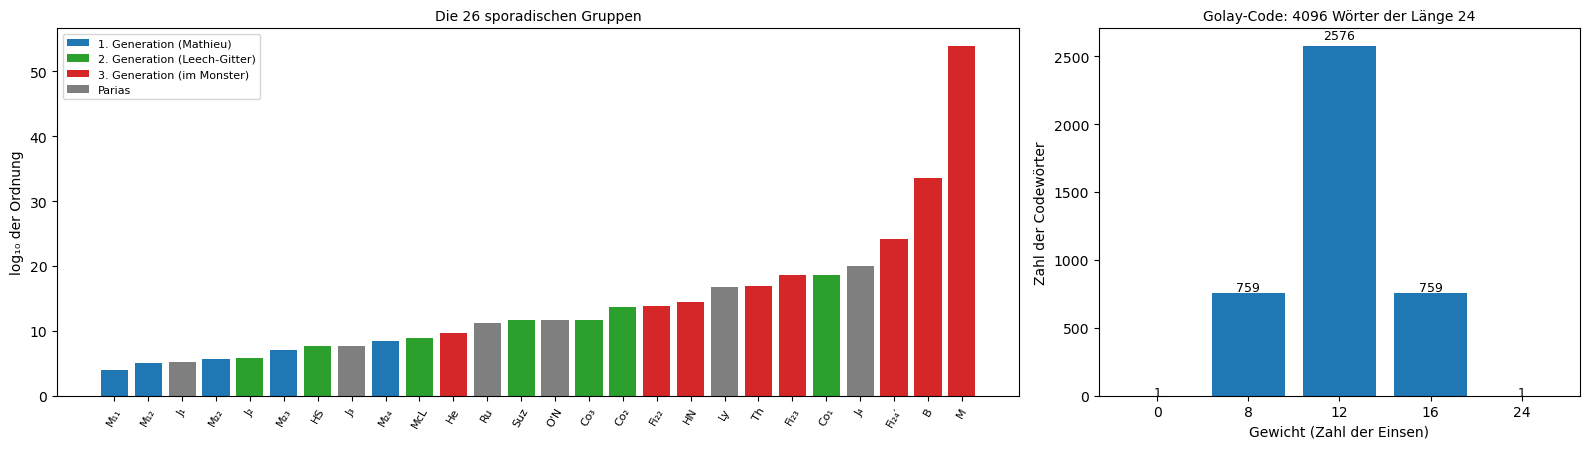

M₁₁: Ordnung       7 920  (Liste: 7 920)
M₁₂: Ordnung      95 040  (Liste: 95 040)


M₂₂: Ordnung     443 520  (Liste: 443 520)
M₂₃: Ordnung  10 200 960  (Liste: 10 200 960)
M₂₄: Ordnung 244 823 040  (Liste: 244 823 040)


Transitivität: M₁₂ ist 5-fach, M₂₄ ist 5-fach transitiv
Golay-Code: Gewichte {0: 1, 8: 759, 12: 2576, 16: 759, 24: 1}, kleinster Abstand 8 → korrigiert 3 Fehler; die drei Erzeuger von M₂₄ erhalten den Code: [True, True, True]
Ordnung des Monsters: 8.080e+53;  Verhältnis Monster / M₂₄ = 3.3e+45


In [11]:
sporadic = [  # (Name, Ordnung, Familie)  nach Griess: 1., 2., 3. Generation der „Happy Family“ und Parias
    ("M₁₁", 7920, 1), ("M₁₂", 95040, 1), ("M₂₂", 443520, 1), ("M₂₃", 10200960, 1), ("M₂₄", 244823040, 1),
    ("J₂", 604800, 2), ("HS", 44352000, 2), ("McL", 898128000, 2), ("Co₃", 495766656000, 2), ("Co₂", 42305421312000, 2),
    ("Suz", 448345497600, 2), ("Co₁", 4157776806543360000, 2),
    ("He", 4030387200, 3), ("Fi₂₂", 64561751654400, 3), ("HN", 273030912000000, 3), ("Th", 90745943887872000, 3),
    ("Fi₂₃", 4089470473293004800, 3), ("Fi₂₄′", 1255205709190661721292800, 3), ("B", 4154781481226426191177580544000000, 3),
    ("M", 808017424794512875886459904961710757005754368000000000, 3),
    ("J₁", 175560, 0), ("J₃", 50232960, 0), ("Ru", 145926144000, 0), ("O'N", 460815505920, 0), ("Ly", 51765179004000000, 0),
    ("J₄", 86775571046077562880, 0)]
s24 = Permutation([list(range(23))], size=24)
t24 = Permutation([[2, 16, 9, 6, 8], [3, 12, 13, 18, 4], [7, 17, 10, 11, 22], [14, 19, 21, 20, 15]], size=24)
u24 = Permutation([[23, 0], [1, 22], [2, 11], [3, 15], [4, 17], [5, 9], [6, 19], [7, 13], [8, 20], [10, 16], [12, 21], [14, 18]], size=24)
M24 = PermutationGroup([s24, t24, u24])                           # Punkte 0 … 22 und ∞ = 23
M23 = M24.stabilizer(23)
M22 = M23.stabilizer(22)
mathieu = {"M₁₁": M11, "M₁₂": M12, "M₂₂": M22, "M₂₃": M23, "M₂₄": M24}

def gf2_rowspace(M):
    """Zeilenstufenform über GF(2): gibt eine Basis des Zeilenraums zurück."""
    M, r = M.copy() % 2, 0
    for c in range(M.shape[1]):
        piv = [i for i in range(r, len(M)) if M[i, c]]
        if piv:
            M[[r, piv[0]]] = M[[piv[0], r]]
            for i in range(len(M)):
                if i != r and M[i, c]:
                    M[i] ^= M[r]
            r += 1
    return M[:r]

QR = sorted({(i * i) % 23 for i in range(1, 23)})                 # quadratische Reste modulo 23
rows = []
for shift in range(23):
    v = np.zeros(24, dtype=int)
    v[[(q + shift) % 23 for q in QR + [0]]] = 1
    v[23] = v[:23].sum() % 2
    rows.append(v)
basis = gf2_rowspace(np.array(rows + [np.ones(24, dtype=int)]))   # erweiterter Golay-Code: 12 Basisvektoren
codewords = np.array([np.array(c) @ basis % 2 for c in itertools.product([0, 1], repeat=len(basis))])
weights = codewords.sum(axis=1)
invariant = [len(gf2_rowspace(np.vstack([basis, basis[:, [g.array_form.index(j) for j in range(24)]]]))) == len(basis) for g in (s24, t24, u24)]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": [2, 1]})
order_sp = sorted(sporadic, key=lambda s: s[1])
colors_sp = {1: "tab:blue", 2: "tab:green", 3: "tab:red", 0: "tab:grey"}
axes[0].bar([s[0] for s in order_sp], [np.log10(float(s[1])) for s in order_sp], color=[colors_sp[s[2]] for s in order_sp])
for lab, c in [("1. Generation (Mathieu)", "tab:blue"), ("2. Generation (Leech-Gitter)", "tab:green"), ("3. Generation (im Monster)", "tab:red"), ("Parias", "tab:grey")]:
    axes[0].bar(0, 0, color=c, label=lab)
axes[0].set_ylabel("log₁₀ der Ordnung")
axes[0].set_title("Die 26 sporadischen Gruppen", fontsize=10)
axes[0].tick_params(axis="x", rotation=60, labelsize=8)
axes[0].legend(fontsize=8)
wv, wc = np.unique(weights, return_counts=True)
axes[1].bar([str(v) for v in wv], wc)
for v, c in zip(wv, wc):
    axes[1].text(str(v), c * 1.02, str(c), ha="center", fontsize=9)
axes[1].set_xlabel("Gewicht (Zahl der Einsen)")
axes[1].set_ylabel("Zahl der Codewörter")
axes[1].set_title(f"Golay-Code: {len(codewords)} Wörter der Länge 24", fontsize=10)
plt.tight_layout()
plt.show()

for name, G in mathieu.items():
    print(f"{name}: Ordnung {fmt(G.order()):>11s}  (Liste: {fmt(dict((s[0], s[1]) for s in sporadic)[name])})")
print(f"Transitivität: M₁₂ ist {M12.transitivity_degree}-fach, M₂₄ ist {M24.transitivity_degree}-fach transitiv")
print(f"Golay-Code: Gewichte {dict(zip(wv.tolist(), wc.tolist()))}, kleinster Abstand {weights[weights > 0].min()} → korrigiert 3 Fehler; die drei Erzeuger von M₂₄ erhalten den Code: {invariant}")
print(f"Ordnung des Monsters: {sporadic[19][1]:.3e};  Verhältnis Monster / M₂₄ = {sporadic[19][1] / 244823040:.1e}")

* Im **linken Bild** reichen die Ordnungen von $10^{3.9}$ ($M_{11}$, 7920) bis $10^{53.9}$ (Monster); dazwischen liegen 51 Größenordnungen. Die Mathieu-Gruppen (blau) sind die kleinsten, die Leech-Gitter-Gruppen (grün) liegen zwischen $10^6$ und $10^{19}$, die Gruppen im Monster (rot) reichen bis zum Monster selbst, die Parias (grau) verteilen sich über den ganzen Bereich. Laut **Ausgabe** stimmen alle fünf aus Erzeugern berechneten Mathieu-Ordnungen mit der Liste überein; $M_{12}$ und $M_{24}$ sind 5-fach transitiv.
* Im **rechten Bild** hat der Golay-Code 1 Wort vom Gewicht 0, 759 vom Gewicht 8, 2576 vom Gewicht 12, 759 vom Gewicht 16 und 1 vom Gewicht 24, zusammen 4096. Das beantwortet die Vorhersage. Kein Codewort hat Gewicht 1 bis 7, der Mindestabstand ist 8, und laut Ausgabe erhalten alle drei Erzeuger von $M_{24}$ den Code. Das Monster ist $3.3\cdot10^{45}$-mal so groß wie $M_{24}$.
* **Wo es vorkommt:** Der Golay-Code übertrug die Farbbilder von Jupiter und Saturn der Raumsonden **Voyager 1 und 2**; er wird in Funkstandards und in der Quantenfehlerkorrektur benutzt (der Quanten-Golay-Code). Das **Leech-Gitter** und das $E_8$-Gitter sind optimale Kugelpackungen und liefern optimale Codes für verrauschte Kanäle; Gitterkonstruktionen dieser Art sind ein Baustein der Post-Quanten-Kryptographie. Steiner-Systeme planen Turniere und Versuchsreihen (Versuchsplanung).

##### *11. Das Monster und Moonshine*

Was ist das Monster, und was hat es mit einer Funktion aus der Zahlentheorie zu tun? Vorher vorhersagen: Der erste Koeffizient der $j$-Funktion ist 196 884; die kleinste nichttriviale Darstellung des Monsters hat 196 883 Dimensionen. Zufall?

Die $j$-Funktion wird als Potenzreihe in $q$ exakt mit ganzen Zahlen berechnet, aus der Eisenstein-Reihe $E_4$ und der Diskriminante $\Delta$ (Formeln in der Theorie). Ihre ersten Koeffizienten werden in Summen der Dimensionen irreduzibler Darstellungen des Monsters zerlegt (links das Wachstum der Koeffizienten). Rechts steht die Primfaktorzerlegung der Ordnung des Monsters, berechnet mit sympy.

**Hintergrund & Fachbegriffe:**
- **Monster** $M$: die größte sporadische Gruppe, mit etwa $8\cdot10^{53}$ Elementen.
- **Darstellung:** eine Abbildung der Gruppe in invertierbare Matrizen, die die Verknüpfung erhält; **irreduzibel**, wenn sie sich nicht in kleinere Darstellungen zerlegen lässt. Ihre **Dimension** ist die Größe der Matrizen.
- **$j$-Funktion:** eine Funktion auf der oberen komplexen Halbebene, die unter der Modulgruppe $SL(2, \mathbb Z)$ unverändert bleibt; geschrieben als Reihe in $q = e^{2\pi i\tau}$.
- **Eisenstein-Reihe** $E_4 = 1 + 240\sum_n\sigma_3(n)q^n$ mit $\sigma_3(n)$ = Summe der dritten Potenzen der Teiler von $n$. **Diskriminante** $\Delta = q\prod_n(1 - q^n)^{24}$.
- **Supersinguläre Primzahl:** eine Primzahl $p$, für die eine bestimmte modulare Kurve $X_0(p)^+$ Geschlecht 0 hat; es gibt genau 15 davon.

**Theorie:**

- **Das Monster:** 1973 von Fischer und Griess vorhergesagt, 1982 von Griess als Symmetriegruppe einer Algebra der Dimension 196 884 konstruiert. Seine kleinste treue Darstellung hat Dimension 196 883; es hat 194 Konjugationsklassen und ebenso viele irreduzible Darstellungen. $\vert M\vert = 2^{46}\cdot3^{20}\cdot5^9\cdot7^6\cdot11^2\cdot13^3\cdot17\cdot19\cdot23\cdot29\cdot31\cdot41\cdot47\cdot59\cdot71$.
- **Die $j$-Funktion:** $j = E_4^3/\Delta = q^{-1} + 744 + 196\,884\,q + 21\,493\,760\,q^2 + \dots$. Ihre Koeffizienten wachsen wie $e^{4\pi\sqrt n}/(\sqrt2\,n^{3/4})$ (Petersson, Rademacher).
- **Moonshine:** McKay bemerkte 1978, dass $196\,884 = 1 + 196\,883$. Thompson fand $21\,493\,760 = 1 + 196\,883 + 21\,296\,876$ und weitere solche Zerlegungen. Conway und Norton vermuteten 1979 („Monstrous Moonshine“), dass es einen unendlichdimensionalen Raum gibt, auf dem das Monster wirkt und dessen Stücke die Koeffizienten von $j$ als Dimensionen haben. Frenkel, Lepowsky und Meurman konstruierten diesen Raum (den Moonshine-Modul) aus dem Leech-Gitter als Zustandsraum einer zweidimensionalen konformen Feldtheorie, einer Art Stringtheorie; Borcherds bewies die Vermutung 1992 (Fields-Medaille 1998).
- **Ogg:** Die 15 Primteiler von $\vert M\vert$ sind genau die supersingulären Primzahlen; Ogg setzte 1974 eine Flasche Jack Daniel's für eine Erklärung aus, bevor das Monster überhaupt konstruiert war. Moonshine liefert heute eine teilweise Erklärung.

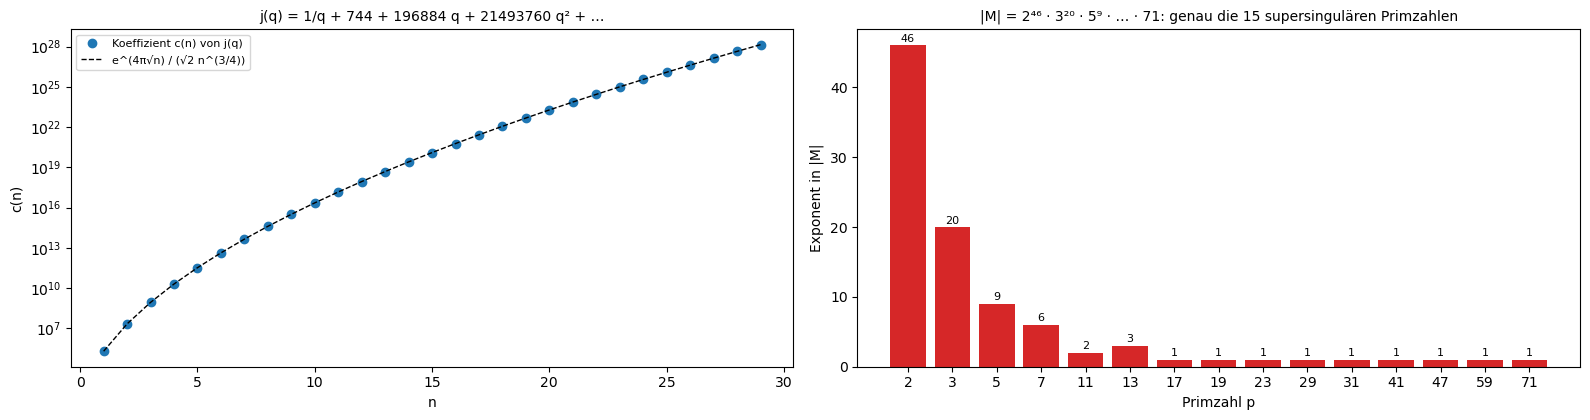

j(q) − 744 = 1/q + 196884 q^1 + 21493760 q^2 + 864299970 q^3 + 20245856256 q^4 + …
c(1) =       196884 = 1·1 + 1·196883  →  True
c(2) =     21493760 = 1·1 + 1·196883 + 1·21296876  →  True
c(3) =    864299970 = 2·1 + 2·196883 + 1·21296876 + 1·842609326  →  True
c(4) =  20245856256 = 3·1 + 3·196883 + 1·21296876 + 2·842609326 + 1·18538750076  →  True
|M| = 808017424794512875886459904961710757005754368000000000 ≈ 8.08e+53;  Primfaktoren: [2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 41, 47, 59, 71]
c(25)/Asymptotik = 0.9940


In [12]:
N = 30
def series_mul(a, b):
    return [sum(a[i] * b[k - i] for i in range(k + 1)) for k in range(N + 1)]

sigma3 = lambda m: sum(d ** 3 for d in range(1, m + 1) if m % d == 0)
E4 = [1] + [240 * sigma3(m) for m in range(1, N + 1)]           # Eisenstein-Reihe E₄ = 1 + 240 Σ σ₃(n) qⁿ
eta24 = [1] + [0] * N                                             # Π (1 − qⁿ)²⁴, ganzzahlig
for m in range(1, N + 1):
    for _ in range(24):
        eta24 = [eta24[k] - (eta24[k - m] if k >= m else 0) for k in range(N + 1)]
E4cube = series_mul(series_mul(E4, E4), E4)
inv = [1] + [0] * N                                               # 1 / Π(1 − qⁿ)²⁴ als Reihe
for k in range(1, N + 1):
    inv[k] = -sum(eta24[i] * inv[k - i] for i in range(1, k + 1))
jq = series_mul(E4cube, inv)                                      # j(q) = q⁻¹ · E₄³ / Π(1 − qⁿ)²⁴; jq[k] ist der Koeffizient von q^(k−1)
c = {k - 1: jq[k] for k in range(N + 1)}
c[0] -= 744                                                       # j − 744: der konstante Term wird abgezogen
r = [1, 196883, 21296876, 842609326, 18538750076, 19360062527, 293553734298]   # Dimensionen der kleinsten Darstellungen des Monsters
decomp = {1: [1, 1], 2: [1, 1, 1], 3: [2, 2, 1, 1], 4: [3, 3, 1, 2, 1]}
monster = sporadic[19][1]
fm = factorint(monster)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.3))
ks = np.arange(1, N)
axes[0].semilogy(ks, [c[k] for k in ks], "o", label="Koeffizient c(n) von j(q)")
axes[0].semilogy(ks, np.exp(4 * np.pi * np.sqrt(ks)) / (np.sqrt(2) * ks ** 0.75), "k--", lw=1, label="e^(4π√n) / (√2 n^(3/4))")
axes[0].set_xlabel("n")
axes[0].set_ylabel("c(n)")
axes[0].set_title("j(q) = 1/q + 744 + 196884 q + 21493760 q² + …", fontsize=10)
axes[0].legend(fontsize=8)
axes[1].bar([str(p) for p in fm], list(fm.values()), color="tab:red")
for i, (p, e) in enumerate(fm.items()):
    axes[1].text(i, e + 0.5, str(e), ha="center", fontsize=8)
axes[1].set_xlabel("Primzahl p")
axes[1].set_ylabel("Exponent in |M|")
axes[1].set_title("|M| = 2⁴⁶ · 3²⁰ · 5⁹ · … · 71: genau die 15 supersingulären Primzahlen", fontsize=10)
plt.tight_layout()
plt.show()

print(f"j(q) − 744 = 1/q + " + " + ".join(f"{c[k]} q^{k}" for k in range(1, 5)) + " + …")
for k, coeffs in decomp.items():
    total = sum(a * b for a, b in zip(coeffs, r))
    print(f"c({k}) = {c[k]:>12d} = " + " + ".join(f"{a}·{b}" for a, b in zip(coeffs, r)) + f"  →  {total == c[k]}")
print(f"|M| = {monster} ≈ {monster:.2e};  Primfaktoren: {sorted(fm)}")
print(f"c(25)/Asymptotik = {c[25] / (np.exp(4 * np.pi * 5) / (np.sqrt(2) * 25 ** 0.75)):.4f}")

* Laut **Ausgabe** ist $j - 744 = q^{-1} + 196\,884\,q + 21\,493\,760\,q^2 + 864\,299\,970\,q^3 + 20\,245\,856\,256\,q^4 + \dots$, und alle vier Koeffizienten zerlegen sich in Dimensionen von Monster-Darstellungen: $196\,884 = 1 + 196\,883$, $21\,493\,760 = 1 + 196\,883 + 21\,296\,876$, $864\,299\,970 = 2\cdot1 + 2\cdot196\,883 + 21\,296\,876 + 842\,609\,326$ und der vierte mit fünf Darstellungen. Das beantwortet die Vorhersage: kein Zufall, sondern Moonshine.
* Im **linken Bild** (logarithmische Achse) liegen die Koeffizienten bis $n = 29$ auf der Asymptotik $e^{4\pi\sqrt n}/(\sqrt2\,n^{3/4})$; bei $n = 25$ trifft sie auf 0.6 % genau (Verhältnis 0.994). Im **rechten Bild** steht die Zerlegung von $\vert M\vert\approx8.08\cdot10^{53}$: der Faktor $2^{46}$ dominiert, und die Primteiler sind genau die 15 Primzahlen 2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 41, 47, 59, 71, die supersingulären.
* **Wo es vorkommt:** Moonshine verbindet endliche Gruppen, Modulformen und die **Stringtheorie**: Der Moonshine-Modul ist eine Vertexoperatoralgebra, die mathematische Form einer zweidimensionalen konformen Feldtheorie. Verwandte Phänomene (Umbral Moonshine, Mathieu Moonshine mit $M_{24}$ in der Stringtheorie auf K3-Flächen, 2010) sind aktive Forschung. Die $j$-Funktion selbst klassifiziert elliptische Kurven über den komplexen Zahlen und erklärt Kuriositäten wie $e^{\pi\sqrt{163}}\approx640\,320^3 + 744$, fast eine ganze Zahl.

##### *12. Punktgruppen von Molekülen*

Wie bestimmt man die Symmetrie eines Moleküls, und was verrät sie? Vorher vorhersagen: Wie viele Symmetrieoperationen hat das Fulleren $C_{60}$?

Für acht Moleküle sucht der Code alle orthogonalen Abbildungen (Drehungen, Spiegelungen, Drehspiegelungen), die das Molekül auf sich abbilden und dabei nur gleiche Atome vertauschen. Zwei nicht kollineare Atome und ihr Kreuzprodukt legen eine solche Abbildung fest, also werden alle passenden Bildpaare durchprobiert. Aus den gefundenen Operationen bestimmt der Code das Schoenflies-Symbol der Punktgruppe. Die Bilder zeigen die Moleküle mit Punktgruppe und Ordnung, die Ausgabe zählt Drehungen, Inversion und Spiegelebenen.

**Hintergrund & Fachbegriffe:**
- **Punktgruppe:** die Gruppe der Symmetrieoperationen, die einen Punkt (den Schwerpunkt) festlassen.
- **Symmetrieelemente:** Drehachse $C_n$ (Drehung um $360°/n$), Spiegelebene $\sigma$ (horizontal $\sigma_h$ senkrecht zur Hauptachse, vertikal $\sigma_v$ oder diagonal $\sigma_d$ durch sie), Inversionszentrum $i$ ($x\mapsto-x$), Drehspiegelachse $S_n$ (Drehung und Spiegelung an der Ebene senkrecht dazu).
- **Schoenflies-Symbole:** $C_n$ (nur eine Drehachse), $C_{nv}$ (dazu vertikale Spiegel), $C_{nh}$ (horizontaler Spiegel), $D_n$ ($n$ zweizählige Achsen senkrecht zur Hauptachse), $D_{nh}$, $D_{nd}$, $T_d$ (Tetraeder), $O_h$ (Oktaeder), $I_h$ (Ikosaeder).
- **Eigentliche und uneigentliche Operationen:** Drehungen (Determinante $+1$) gegen Spiegelungen, Inversion und Drehspiegelungen (Determinante $-1$).
- **Chiral:** nicht mit seinem Spiegelbild zur Deckung zu bringen, wie eine Hand.
- **Cayley-Graph:** ein Graph mit den Gruppenelementen als Ecken und einer Kante von $g$ zu $g\cdot s$ für jeden Erzeuger $s$; er zeigt die Gruppe als Netz.

**Theorie:**

- **Endliche Untergruppen von $O(3)$:** Jede Punktgruppe ist eine endliche Gruppe von $3\times3$-Orthogonalmatrizen. Die Drehgruppen darunter sind nur $C_n$, $D_n$, $T\cong A_4$, $O\cong S_4$ und $I\cong A_5$ (Klein 1884); die übrigen Punktgruppen entstehen durch Hinzunehmen von Spiegelungen.
- **Ordnungen:** $C_{2v}$ hat 4 Elemente, $C_{3v}\cong S_3$ hat 6, $D_{3d}$ 12, $T_d\cong S_4$ 24, $D_{6h}$ 24, $O_h$ 48 und $I_h$ 120, die größte Punktgruppe eines Moleküls.
- **Chiralität:** Ein Molekül ist genau dann chiral, wenn seine Punktgruppe nur Drehungen enthält (keine Spiegelung, keine Inversion, keine Drehspiegelung). Wasserstoffperoxid $H_2O_2$ mit Punktgruppe $C_2$ ist ein Beispiel.
- **Polar:** Ein Molekül kann nur dann ein Dipolmoment haben, wenn seine Punktgruppe einen Vektor festlässt, also $C_n$, $C_{nv}$ oder $C_s$ ist; Wasser und Ammoniak sind polar, Methan, Benzol und $SF_6$ nicht.
- **Spektroskopie:** Welche Schwingungen im Infrarot- oder Raman-Spektrum erscheinen und wie Orbitale aufspalten, bestimmen die Darstellungen der Punktgruppe (Charaktertafeln); das ist Thema der Darstellungstheorie.

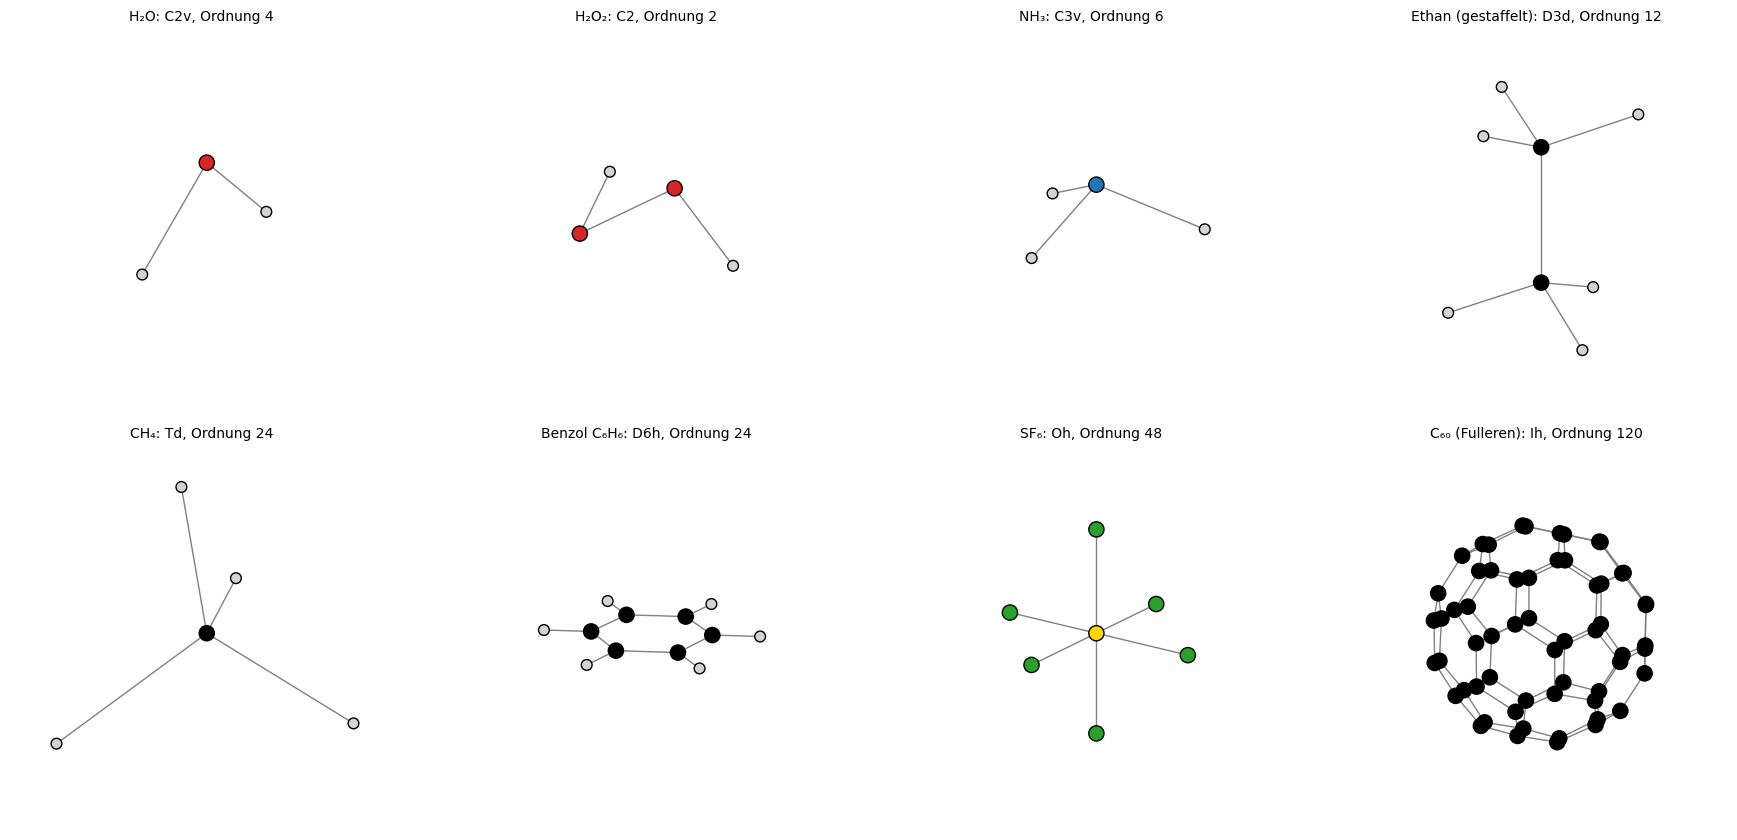

Cayley-Graph von A₅ (60 Ecken, 90 Kanten) isomorph zum C₆₀-Gerüst (60, 90): True
Molekül              Ordnung Drehungen Inversion Spiegel  Punktgruppe   chiral
H₂O                        4         2     False       2  C2v           nein
H₂O₂                       2         2     False       0  C2            ja
NH₃                        6         3     False       3  C3v           nein
Ethan (gestaffelt)        12         6      True       3  D3d           nein
CH₄                       24        12     False       6  Td            nein
Benzol C₆H₆               24        12      True       7  D6h           nein
SF₆                       48        24      True       9  Oh            nein
C₆₀ (Fulleren)           120        60      True      15  Ih            nein


In [13]:
def symmetry_ops(types, X, tol=1e-4):
    """Alle orthogonalen Abbildungen, die das Molekül (Atomsorten types, Koordinaten X) auf sich abbilden.
    Zwei nicht kollineare Atome a, b und ihr Kreuzprodukt legen eine solche Abbildung fest; probiert werden alle passenden Bildpaare."""
    X = X - X.mean(axis=0)
    idx = [i for i in range(len(X)) if np.linalg.norm(X[i]) > 1e-8]
    a = idx[0]
    b = next(j for j in idx if np.linalg.norm(np.cross(X[a], X[j])) > 1e-6)
    ops = []
    for a2, b2 in itertools.product(range(len(X)), repeat=2):
        if types[a2] != types[a] or types[b2] != types[b]:
            continue
        if abs(np.linalg.norm(X[a2]) - np.linalg.norm(X[a])) > tol or abs(np.linalg.norm(X[b2]) - np.linalg.norm(X[b])) > tol or abs(X[a2] @ X[b2] - X[a] @ X[b]) > tol:
            continue
        Fm = np.c_[X[a], X[b], np.cross(X[a], X[b])]
        for sgn in (1, -1):
            R = np.c_[X[a2], X[b2], sgn * np.cross(X[a2], X[b2])] @ np.linalg.inv(Fm)
            Yx = X @ R.T
            dist = np.linalg.norm(Yx[:, None, :] - X[None, :, :], axis=2)
            j = dist.argmin(axis=1)
            if dist[np.arange(len(X)), j].max() < tol and all(types[i] == types[k] for i, k in enumerate(j)) and not any(np.allclose(R, S, atol=1e-6) for S in ops):
                ops.append(R)
    return ops

def rotation_order(R):
    angle = np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1))
    return 1 if angle < 1e-6 else int(round(2 * np.pi / angle))

def point_group(ops):
    """Schoenflies-Symbol aus der Liste der Symmetrieoperationen."""
    proper = [R for R in ops if np.linalg.det(R) > 0]
    improper = [R for R in ops if np.linalg.det(R) < 0]
    inversion = any(np.allclose(R, -np.eye(3)) for R in ops)
    mirrors = [R for R in improper if np.isclose(np.trace(R), 1)]
    if len(proper) == 60:
        return "Ih" if inversion else "I"
    if len(proper) == 24 and max(rotation_order(R) for R in proper) == 4:
        return "Oh" if inversion else "O"
    if len(proper) == 12 and sum(rotation_order(R) == 3 for R in proper) == 8:
        return ("Th" if inversion else "Td") if improper else "T"
    n = max(rotation_order(R) for R in proper)
    if n == 1:
        return "Cs" if mirrors else ("Ci" if inversion else "C1")
    main = next(R for R in proper if rotation_order(R) == n)
    w_, v_ = np.linalg.eig(main)
    axis = np.real(v_[:, np.argmin(np.abs(w_ - 1))])
    perp_c2 = [R for R in proper if rotation_order(R) == 2 and abs(np.real(np.linalg.eig(R)[1][:, np.argmin(np.abs(np.linalg.eig(R)[0] - 1))]) @ axis) < 1e-6]
    normals = [np.real(np.linalg.eig(R)[1][:, np.argmin(np.abs(np.linalg.eig(R)[0] + 1))]) for R in mirrors]
    sigma_h = any(abs(abs(nv @ axis) - 1) < 1e-6 for nv in normals)
    sigma_v = any(abs(nv @ axis) < 1e-6 for nv in normals)
    letter = "D" if len(perp_c2) == n else "C"
    if sigma_h:
        return f"{letter}{n}h"
    if sigma_v:
        return f"{letter}{n}{'d' if letter == 'D' else 'v'}"
    if improper and letter == "C":
        return f"S{2 * n}"
    return f"{letter}{n}"

gold = (1 + 5 ** 0.5) / 2
def buckyball():
    """C₆₀: alle zyklischen Vertauschungen von (0, ±1, ±3φ), (±1, ±(2+φ), ±2φ), (±φ, ±2, ±φ³)."""
    pts = set()
    for v in [(0, 1, 3 * gold), (1, 2 + gold, 2 * gold), (gold, 2, gold ** 3)]:
        for sh in range(3):
            w3 = v[sh:] + v[:sh]
            for sg in itertools.product([1, -1], repeat=3):
                pts.add(tuple(round(s * x, 9) for s, x in zip(sg, w3)))
    return np.array(sorted(pts)) * 0.7

ring = lambda r, k, z=0.0, off=0.0: [[r * np.cos(2 * np.pi * i / k + off), r * np.sin(2 * np.pi * i / k + off), z] for i in range(k)]
molecules = {
    "H₂O": (["O", "H", "H"], [[0, 0, 0.117], [0.757, 0, -0.469], [-0.757, 0, -0.469]]),
    "H₂O₂": (["O", "O", "H", "H"], [[0.74, 0, 0], [-0.74, 0, 0], [0.98, 0.9 * np.cos(0.97), 0.9 * np.sin(0.97)], [-0.98, 0.9 * np.cos(0.97), -0.9 * np.sin(0.97)]]),
    "NH₃": (["N", "H", "H", "H"], [[0, 0, 0.38]] + ring(0.94, 3)),
    "Ethan (gestaffelt)": (["C", "C"] + ["H"] * 6, [[0, 0, 0.77], [0, 0, -0.77]] + ring(1.02, 3, 1.16) + ring(1.02, 3, -1.16, np.pi / 3)),
    "CH₄": (["C"] + ["H"] * 4, (np.array([[0, 0, 0], [1, 1, 1], [1, -1, -1], [-1, 1, -1], [-1, -1, 1]]) * 0.63).tolist()),
    "Benzol C₆H₆": (["C"] * 6 + ["H"] * 6, ring(1.39, 6) + ring(2.48, 6)),
    "SF₆": (["S"] + ["F"] * 6, [[0, 0, 0], [1.56, 0, 0], [-1.56, 0, 0], [0, 1.56, 0], [0, -1.56, 0], [0, 0, 1.56], [0, 0, -1.56]]),
    "C₆₀ (Fulleren)": (["C"] * 60, buckyball().tolist()),
}
atom_color = {"H": "lightgrey", "C": "black", "N": "tab:blue", "O": "tab:red", "S": "gold", "F": "tab:green"}
fig = plt.figure(figsize=(18, 8.5))
table = []
for i, (name, (types, coords)) in enumerate(molecules.items()):
    Xm = np.array(coords, dtype=float)
    ops = symmetry_ops(types, Xm)
    pg = point_group(ops)
    table.append((name, len(ops), sum(np.linalg.det(R) > 0 for R in ops), any(np.allclose(R, -np.eye(3)) for R in ops),
                  sum(np.linalg.det(R) < 0 and np.isclose(np.trace(R), 1) for R in ops), pg))
    ax = fig.add_subplot(2, 4, i + 1, projection="3d")
    Xc = Xm - Xm.mean(axis=0)
    dmat = np.linalg.norm(Xc[:, None] - Xc[None], axis=2)
    for p_, q_ in itertools.combinations(range(len(Xc)), 2):
        if dmat[p_, q_] < 1.75 and not (types[p_] == "H" and types[q_] == "H"):
            ax.plot(*Xc[[p_, q_]].T, color="grey", lw=1)
    ax.scatter(*Xc.T, c=[atom_color[t] for t in types], s=[60 if t == "H" else 120 for t in types], edgecolor="k", depthshade=False)
    ax.set_title(f"{name}: {pg}, Ordnung {len(ops)}", fontsize=10)
    ax.set_box_aspect([1, 1, 1])
    lim = np.abs(Xc).max() * 1.05
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
    ax.view_init(elev=20, azim=35)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

a5_gen = (Permutation([[0, 1, 2, 3, 4]]), Permutation([[0, 1], [2, 3]], size=5))      # Erzeuger der Ordnungen 5 und 2, Produkt der Ordnung 3
cayley = nx.Graph()
for g in PermutationGroup(list(a5_gen)).generate():
    for s_ in a5_gen:
        cayley.add_edge(tuple(g.array_form), tuple((g * s_).array_form))
C = np.array(molecules["C₆₀ (Fulleren)"][1])
dC = np.linalg.norm(C[:, None] - C[None], axis=2)
bonds = nx.Graph([(i, j) for i in range(60) for j in range(i + 1, 60) if dC[i, j] < 1.75])
print(f"Cayley-Graph von A₅ ({cayley.number_of_nodes()} Ecken, {cayley.number_of_edges()} Kanten) isomorph zum C₆₀-Gerüst ({bonds.number_of_nodes()}, {bonds.number_of_edges()}): {nx.is_isomorphic(cayley, bonds)}")
print(f"{'Molekül':20s} {'Ordnung':>7s} {'Drehungen':>9s} {'Inversion':>9s} {'Spiegel':>7s}  Punktgruppe   chiral")
for name, o, pr, inv_, mi, pg in table:
    print(f"{name:20s} {o:7d} {pr:9d} {str(inv_):>9s} {mi:7d}  {pg:12s}  {'ja' if o == pr else 'nein'}")

* Die **Bilder** zeigen die acht Moleküle mit der gefundenen Punktgruppe. Laut **Ausgabe**: Wasser $C_{2v}$ (4 Operationen: Identität, eine Drehung um 180°, zwei Spiegelebenen), Wasserstoffperoxid $C_2$ (2, nur Drehungen, deshalb chiral), Ammoniak $C_{3v}$ (6), gestaffeltes Ethan $D_{3d}$ (12, mit Inversionszentrum), Methan $T_d$ (24, sechs Spiegelebenen, keine Inversion), Benzol $D_{6h}$ (24, sieben Spiegelebenen), $SF_6$ $O_h$ (48, neun Spiegelebenen) und $C_{60}$ $I_h$ (120 Operationen, davon 60 Drehungen, 15 Spiegelebenen). Das beantwortet die Vorhersage.
* Die Ordnungen sind Teiler und Vielfache voneinander, wie Lagrange verlangt: $C_{3v}$ (6) ist Untergruppe von $T_d$ (24) und von $D_{3d}$ (12). Die 60 Drehungen von $C_{60}$ bilden die Gruppe $A_5$, und laut Ausgabe ist ihr Cayley-Graph sogar isomorph zum $C_{60}$-Gerüst aus 60 Ecken und 90 Kanten: Jedes Kohlenstoffatom entspricht einer Drehung, jede Bindung einem Erzeuger. Nur $H_2O_2$ ist chiral; alle anderen haben mindestens eine uneigentliche Operation.
* **Wo es vorkommt:** Die Punktgruppe bestimmt, welche **Schwingungen im IR- und Raman-Spektrum** sichtbar sind, wie d-Orbitale in Komplexen aufspalten (Ligandenfeldtheorie), ob ein Molekül polar ist und ob es **optisch aktiv** (chiral) ist; Spiegelbildmoleküle (Enantiomere) können völlig verschieden wirken, Carvon riecht in der einen Form nach Minze, in der anderen nach Kümmel. Programme der Quantenchemie nutzen die Punktgruppe, um Rechnungen erheblich zu beschleunigen, und äquivariante neuronale Netze für Moleküle (etwa für Kraftfelder und Wirkstoffdesign) bauen die Drehgruppe $SO(3)$ direkt in die Architektur ein. Ikosaedersymmetrie findet man auch bei Virushüllen.

##### *13. Kristalle: die kristallographische Einschränkung und Tapetengruppen*

Welche Drehsymmetrien kann ein Kristall haben? Vorher vorhersagen: Gibt es Kristalle mit fünfzähliger Drehachse?

Links wird für die Drehordnungen $n = 1$ bis 12 die Spur $2\cos(2\pi/n)$ der Drehmatrix berechnet; nur ganzzahlige Werte sind mit einem Gitter verträglich. Rechts werden drei der 17 Tapetengruppen gezeichnet: Ein Motiv wird mit den Operationen der Punktgruppe vervielfältigt und dann über das Gitter verschoben (p4m mit Quadratgitter und Punktgruppe $D_4$, p6m mit Sechseckgitter und $D_6$, p3 nur mit Drehungen um 120°).

**Hintergrund & Fachbegriffe:**
- **Gitter:** alle ganzzahligen Kombinationen $m\,\vec a_1 + n\,\vec a_2$ (in 3D mit drei Vektoren) zweier Basisvektoren.
- **Raumgruppe:** die Symmetriegruppe eines Kristalls, aus Verschiebungen um Gittervektoren, Drehungen, Spiegelungen, Schraubenachsen und Gleitspiegelebenen. Ihr zweidimensionales Gegenstück ist die **Tapetengruppe** (ebene kristallographische Gruppe).
- **Spur:** die Summe der Diagonalelemente einer Matrix; sie ändert sich bei einem Basiswechsel nicht.
- **Quasikristall:** ein geordneter, aber nicht periodischer Festkörper mit scharfen Beugungsreflexen.

**Theorie:**

- **Kristallographische Einschränkung:** Eine Drehung, die ein Gitter auf sich abbildet, hat in der Gitterbasis eine Matrix mit ganzzahligen Einträgen, also eine ganzzahlige Spur. In der Ebene ist die Spur einer Drehung um $\theta$ gleich $2\cos\theta$; ganzzahlig ist sie nur für $\theta = 360°/n$ mit $n = 1, 2, 3, 4, 6$. Fünf-, sieben- und höherzählige Achsen sind in Kristallen unmöglich.
- **Abzählung:** In der Ebene gibt es 10 kristallographische Punktgruppen, 5 Gittertypen und 17 Tapetengruppen (Fedorov 1891, Pólya 1924); im Raum 32 Kristallklassen, 7 Kristallsysteme, 14 Bravais-Gitter und 230 Raumgruppen (Fedorov und Schoenflies 1891). Von den 230 sind 11 Paare spiegelbildlich zueinander; zählt man die Paare einfach, sind es 219. In vier Dimensionen gibt es 4894 Raumgruppen.
- **Quasikristalle:** Shechtman fand 1982 in einer Aluminium-Mangan-Legierung ein Beugungsbild mit zehnzähliger Symmetrie, nach der Einschränkung „verboten“. Die Auflösung: Der Körper ist geordnet, aber nicht periodisch, wie eine Penrose-Parkettierung; Nobelpreis für Chemie 2011.

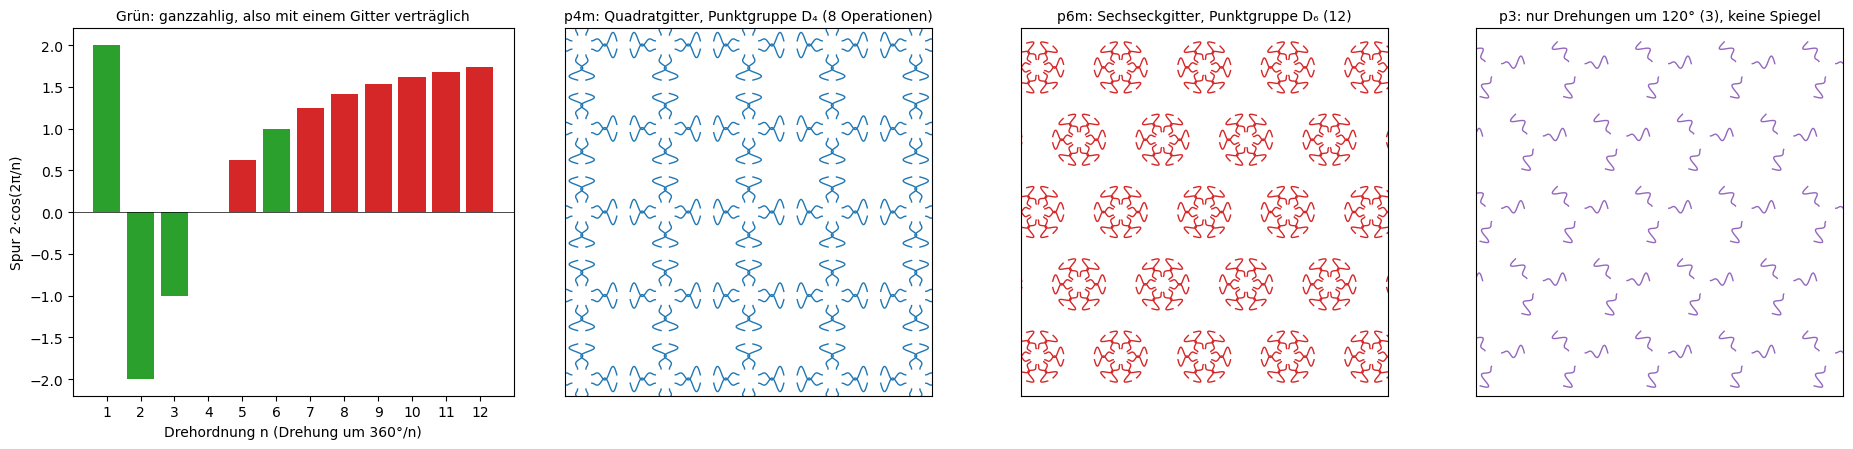

Mit einem Gitter verträgliche Drehordnungen: [1, 2, 3, 4, 6]  (2cos(2π/n) ganzzahlig)
Zum Beispiel n = 5: 2cos(72°) = 0.618034 = (√5 − 1)/2, nicht ganzzahlig → kein Kristall mit fünfzähliger Achse
Bekannte Anzahlen: 10 Punktgruppen und 17 Tapetengruppen in der Ebene; 32 Kristallklassen, 14 Bravais-Gitter und 230 Raumgruppen im Raum


In [14]:
nr = np.arange(1, 13)
trace = 2 * np.cos(2 * np.pi / nr)
allowed = np.isclose(trace, np.round(trace))

def wallpaper(ax, point_ops, a1, a2, motif, color, reps=3):
    """Zeichnet ein Muster: Motiv × Punktgruppe, dann über das Gitter verschoben."""
    for m, n_ in itertools.product(range(-reps, reps + 1), repeat=2):
        t = m * np.array(a1) + n_ * np.array(a2)
        for Rm in point_ops:
            pts = motif @ Rm.T + t
            ax.plot(pts[:, 0], pts[:, 1], color=color, lw=1)
    ax.set_aspect("equal")
    ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2)
    ax.set_xticks([]); ax.set_yticks([])

s_ = np.linspace(0, 1, 60)
motif = np.c_[0.12 + 0.3 * s_, 0.05 + 0.12 * np.sin(3 * np.pi * s_) * s_]
mirror = np.diag([1.0, -1.0])
D4ops = [np.real(M) for M in matrix_group([rot2(np.pi / 2), mirror])]
D6ops = [np.real(M) for M in matrix_group([rot2(np.pi / 3), mirror])]
C3ops = [np.real(M) for M in matrix_group([rot2(2 * np.pi / 3)])]

fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))
axes[0].bar(nr, trace, color=["tab:green" if a else "tab:red" for a in allowed])
axes[0].axhline(0, color="k", lw=0.5)
axes[0].set_xticks(nr)
axes[0].set_xlabel("Drehordnung n (Drehung um 360°/n)")
axes[0].set_ylabel("Spur 2·cos(2π/n)")
axes[0].set_title("Grün: ganzzahlig, also mit einem Gitter verträglich", fontsize=10)
wallpaper(axes[1], D4ops, (1, 0), (0, 1), motif, "tab:blue")
axes[1].set_title(f"p4m: Quadratgitter, Punktgruppe D₄ ({len(D4ops)} Operationen)", fontsize=10)
wallpaper(axes[2], D6ops, (1, 0), (0.5, np.sqrt(3) / 2), motif * 0.75, "tab:red")
axes[2].set_title(f"p6m: Sechseckgitter, Punktgruppe D₆ ({len(D6ops)})", fontsize=10)
wallpaper(axes[3], C3ops, (1, 0), (0.5, np.sqrt(3) / 2), motif * 0.9, "tab:purple")
axes[3].set_title(f"p3: nur Drehungen um 120° ({len(C3ops)}), keine Spiegel", fontsize=10)
plt.tight_layout()
plt.show()

print(f"Mit einem Gitter verträgliche Drehordnungen: {list(nr[allowed])}  (2cos(2π/n) ganzzahlig)")
print(f"Zum Beispiel n = 5: 2cos(72°) = {2 * np.cos(2 * np.pi / 5):.6f} = (√5 − 1)/2, nicht ganzzahlig → kein Kristall mit fünfzähliger Achse")
print("Bekannte Anzahlen: 10 Punktgruppen und 17 Tapetengruppen in der Ebene; 32 Kristallklassen, 14 Bravais-Gitter und 230 Raumgruppen im Raum")

* Im **linken Bild** ist $2\cos(2\pi/n)$ nur für $n = 1, 2, 3, 4, 6$ ganzzahlig (2, $-2$, $-1$, 0, 1; grün). Für $n = 5$ ist es $(\sqrt5 - 1)/2 = 0.618$, für $n \geq 7$ liegt es zwischen 1 und 2, nie ganzzahlig. Das beantwortet die Vorhersage: Ein periodischer Kristall kann keine fünfzählige Achse haben; laut **Ausgabe** sind nur 1, 2, 3, 4 und 6 verträglich.
* Die **drei Tapeten** rechts zeigen dasselbe Motiv in drei Symmetriegruppen: p4m vervielfältigt es mit den 8 Operationen von $D_4$ (vierzählige Drehungen und Spiegel) auf einem Quadratgitter, p6m mit den 12 Operationen von $D_6$ auf einem Sechseckgitter, p3 nur mit 3 Drehungen. Bei p3 fehlen die Spiegel; das Muster ist chiral, seine Kringel drehen sich alle in dieselbe Richtung.
* **Wo es vorkommt:** Die **Röntgenstrukturanalyse** bestimmt zuerst die Raumgruppe eines Kristalls; die International Tables for Crystallography listen alle 230, und Datenbanken wie die Cambridge Structural Database und die Materials-Project-Datenbank sind nach ihnen geordnet. Die Raumgruppe bestimmt elektronische Bänder, Piezo- und Ferroelektrizität (nur in bestimmten Klassen ohne Inversionszentrum) und topologische Eigenschaften von Materialien. Tapetengruppen findet man in Ornamenten (die Alhambra enthält viele der 17), bei Escher und in Mustern auf Textilien; Quasikristalle in Legierungen und in mittelalterlichen islamischen Fliesen.

##### *14. Gruppen in der Quanteninformation: Pauli- und Clifford-Gruppe*

Welche Gruppen beschreiben Fehler und einfache Gatter auf Qubits? Vorher vorhersagen: Wie viele Elemente hat die Clifford-Gruppe eines Qubits, wenn man globale Phasen ignoriert?

Die Pauli-Gruppe eines Qubits wird aus $X$, $Y$, $Z$ erzeugt (mit den Phasen $\pm1, \pm i$). Die Clifford-Gruppe wird aus dem Hadamard-Gatter $H$ und dem Phasengatter $S$ erzeugt, wobei Matrizen, die sich nur um eine globale Phase unterscheiden, als gleich gelten. Jedes Clifford-Element wird in eine Drehung der Bloch-Kugel umgerechnet und nach Drehwinkel und Achse sortiert; links werden diese Klassen mit den Konjugationsklassen von $S_4$ verglichen. Rechts steht, wie die Gruppen mit der Zahl der Qubits wachsen.

**Hintergrund & Fachbegriffe:**
- **Pauli-Gruppe** $\mathcal P_n$: alle Tensorprodukte von $I, X, Y, Z$ auf $n$ Qubits mit Phasen $\pm1, \pm i$; sie beschreibt die elementaren Fehler (Bitflip $X$, Phasenflip $Z$).
- **Clifford-Gruppe:** die unitären Gatter, die Pauli-Operatoren durch Konjugation wieder auf Pauli-Operatoren abbilden; erzeugt von $H$, $S$ und CNOT.
- **Hadamard-Gatter** $H$ vertauscht $X$ und $Z$; **Phasengatter** $S = \mathrm{diag}(1, i)$ bildet $X$ auf $Y$ ab.
- **Bloch-Kugel:** Jeder Ein-Qubit-Zustand ist ein Punkt auf einer Kugel; jedes Ein-Qubit-Gatter dreht diese Kugel. Die Pauli-Achsen $\pm X, \pm Y, \pm Z$ sind die sechs Ecken eines Oktaeders.
- **Globale Phase:** ein Faktor $e^{i\varphi}$ vor einem Gatter; er ändert keine Messung.

**Theorie:**

- **Pauli-Gruppe:** 16 Elemente für ein Qubit; nichtabelsch ($XZ = -ZX$), aber ohne Phasen abelsch, $\mathbb Z_2\times\mathbb Z_2$, für $n$ Qubits $\mathbb Z_2^{2n}$ mit $4^n$ Elementen. Zwei Pauli-Operatoren vertauschen oder antivertauschen immer.
- **Clifford-Gruppe = Oktaedergruppe:** Ein Clifford-Gatter muss die sechs Pauli-Achsen untereinander vertauschen, also ist es eine Drehung, die das Oktaeder auf sich abbildet. Davon gibt es genau 24, die Drehgruppe $O\cong S_4$ des Oktaeders bzw. Würfels. Ihre Klassen sind die Identität, 8 Drehungen um 120° (Raumdiagonalen), 6 um 90° und 3 um 180° (Flächenachsen) und 6 um 180° (Kantenachsen), wie die Zyklentypen von $S_4$: 1, 8, 6, 3, 6.
- **Größe für $n$ Qubits** (ohne Phase): $2^{n^2 + 2n}\prod_{j=1}^n(4^j - 1)$, also 24, 11 520, 92 897 280, …; sie wächst wie $2^{2n^2}$, schneller als die Pauli-Gruppe ($4^n$).
- **Gottesman-Knill:** Schaltkreise aus Clifford-Gattern mit Stabilisatorzuständen lassen sich effizient klassisch simulieren; für einen universellen Quantenrechner braucht man ein Nicht-Clifford-Gatter wie $T = \mathrm{diag}(1, e^{i\pi/4})$.
- **Stabilisatorcodes:** Ein Quantencode wird durch eine abelsche Untergruppe der Pauli-Gruppe festgelegt, deren gemeinsamer Eigenraum mit Eigenwert $+1$ die Codewörter enthält.

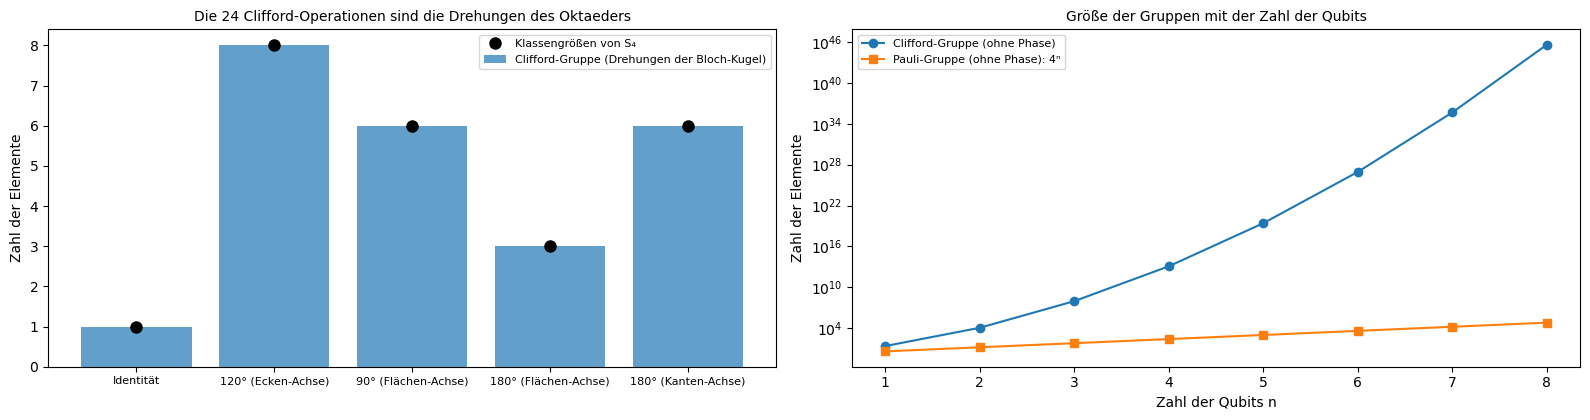

Pauli-Gruppe mit Phasen: 16 Elemente; Paare, die vertauschen: 160 von 256; ohne Phase bleibt ℤ₂ × ℤ₂ (4 Elemente)
Clifford-Gruppe eines Qubits ohne Phase: 24 Elemente;  Klassen nach Drehwinkel {'Identität': 1, '120° (Ecken-Achse)': 8, '90° (Flächen-Achse)': 6, '180° (Flächen-Achse)': 3, '180° (Kanten-Achse)': 6}
Größe der n-Qubit-Clifford-Gruppe (ohne Phase): n = 1: 24, n = 2: 11520, n = 3: 92897280


In [15]:
I2 = np.eye(2)
Hd = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
Sg = np.diag([1, 1j])
pauli_group = matrix_group([X, Y, Z])                             # mit den Phasen ±1, ±i

def phase_free_key(U):
    k = np.argmax(np.abs(U.ravel()) > 1e-9)
    return key(U / (U.ravel()[k] / abs(U.ravel()[k])))

clifford, frontier = {phase_free_key(I2): I2}, [I2]               # Clifford-Gruppe ohne globale Phase, erzeugt von H und S
while frontier:
    new = []
    for U in frontier:
        for gen in (Hd, Sg):
            V = gen @ U
            if phase_free_key(V) not in clifford:
                clifford[phase_free_key(V)] = V
                new.append(V)
    frontier = new
paulis3 = [X, Y, Z]
bloch = [np.real(np.array([[np.trace(paulis3[i] @ U @ paulis3[j] @ U.conj().T) / 2 for j in range(3)] for i in range(3)])) for U in clifford.values()]
classes = {"Identität": 0, "120° (Ecken-Achse)": 0, "90° (Flächen-Achse)": 0, "180° (Flächen-Achse)": 0, "180° (Kanten-Achse)": 0}
for Rb in bloch:
    ang = np.degrees(np.arccos(np.clip((np.trace(Rb) - 1) / 2, -1, 1)))
    axis = Rotation.from_matrix(Rb).as_rotvec()
    if ang < 1:
        classes["Identität"] += 1
    elif abs(ang - 120) < 1:
        classes["120° (Ecken-Achse)"] += 1
    elif abs(ang - 90) < 1:
        classes["90° (Flächen-Achse)"] += 1
    elif np.sum(np.abs(axis) > 1e-6) == 1:
        classes["180° (Flächen-Achse)"] += 1
    else:
        classes["180° (Kanten-Achse)"] += 1
s4_classes = {"Identität": 1, "3-Zyklen": 8, "4-Zyklen": 6, "Doppeltranspositionen": 3, "Transpositionen": 6}
qubits = np.arange(1, 9)
clifford_size = [float(2 ** (n * n + 2 * n) * np.prod([4 ** j - 1 for j in range(1, n + 1)], dtype=object)) for n in map(int, qubits)]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.3))
axes[0].bar(list(classes), list(classes.values()), alpha=0.7, label="Clifford-Gruppe (Drehungen der Bloch-Kugel)")
axes[0].plot(list(classes), list(s4_classes.values()), "ko", ms=8, label="Klassengrößen von S₄")
axes[0].set_ylabel("Zahl der Elemente")
axes[0].set_title(f"Die {len(clifford)} Clifford-Operationen sind die Drehungen des Oktaeders", fontsize=10)
axes[0].tick_params(axis="x", labelsize=8)
axes[0].legend(fontsize=8)
axes[1].semilogy(qubits, clifford_size, "o-", label="Clifford-Gruppe (ohne Phase)")
axes[1].semilogy(qubits, 4.0 ** qubits, "s-", label="Pauli-Gruppe (ohne Phase): 4ⁿ")
axes[1].set_xlabel("Zahl der Qubits n")
axes[1].set_ylabel("Zahl der Elemente")
axes[1].set_title("Größe der Gruppen mit der Zahl der Qubits", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

comm = sum(1 for A in pauli_group for B in pauli_group if np.allclose(A @ B, B @ A))
print(f"Pauli-Gruppe mit Phasen: {len(pauli_group)} Elemente; Paare, die vertauschen: {comm} von {len(pauli_group) ** 2}; ohne Phase bleibt ℤ₂ × ℤ₂ (4 Elemente)")
print(f"Clifford-Gruppe eines Qubits ohne Phase: {len(clifford)} Elemente;  Klassen nach Drehwinkel {classes}")
print(f"Größe der n-Qubit-Clifford-Gruppe (ohne Phase): n = 1: {clifford_size[0]:.0f}, n = 2: {clifford_size[1]:.0f}, n = 3: {clifford_size[2]:.0f}")

* Im **linken Bild** stimmen die Klassengrößen der 24 Clifford-Drehungen genau mit denen von $S_4$ überein: 1 Identität, 8 Drehungen um 120° um Raumdiagonalen (sie vertauschen $X\to Y\to Z$ zyklisch), 6 um 90° (wie $S$ und $H S H$), 3 um 180° um die Pauli-Achsen (die Pauli-Operatoren selbst) und 6 um 180° um Kantenachsen (wie $H$). Laut **Ausgabe** hat die Clifford-Gruppe ohne Phase 24 Elemente; das beantwortet die Vorhersage.
* Die Pauli-Gruppe hat mit Phasen 16 Elemente, und 160 der 256 Paare vertauschen. Im **rechten Bild** (logarithmisch) wächst die Clifford-Gruppe wie $2^{2n^2}$: 24, 11 520 und 92 897 280 Elemente für 1, 2 und 3 Qubits, für 8 Qubits etwa $4\cdot10^{45}$, während die Pauli-Gruppe nur wie $4^n$ wächst.
* **Wo es vorkommt:** **Quantenfehlerkorrektur** (Stabilisatorcodes wie der Oberflächencode, mit dem Google und andere logische Qubits bauen), **Randomized Benchmarking** (man misst die Fehlerrate eines Quantenprozessors mit zufälligen Clifford-Folgen; das funktioniert, weil die Clifford-Gruppe ein unitäres 2-Design ist), klassische Simulation von Stabilisatorschaltkreisen (Gottesman-Knill, Programme wie Stim) und magische Zustände für das $T$-Gatter. Mehr zu Stabilisatorzuständen steht in der Notiz [Stabilisatorzustände](https://github.com/deltorobarba/science/blob/main/quantum/stabilizer.md).

##### *15. Lie-Gruppen: zufällige Drehungen und die doppelte Überlagerung*

Wie zieht man eine zufällige Drehung, und warum muss man einen Spin zweimal herumdrehen? Vorher vorhersagen: Welche Drehwinkel kommen bei wirklich gleichverteilten zufälligen Drehungen am häufigsten vor, kleine oder große?

Links werden 50 000 zufällige Drehungen auf zwei Arten gezogen: mit dem Haar-Maß (`scipy.stats.special_ortho_group`) und naiv mit gleichverteilten Euler-Winkeln; das Histogramm ihrer Drehwinkel wird mit der Dichte $(1 - \cos\theta)/\pi$ verglichen. In der Mitte stehen die Spuren einer Drehung um den Winkel $\alpha$ in $SO(3)$ und in $SU(2)$. Rechts stehen die Dimensionen der klassischen Lie-Gruppen.

**Hintergrund & Fachbegriffe:**
- **$SO(3)$:** die Drehungen des Raums, orthogonale $3\times3$-Matrizen mit Determinante 1; eine Lie-Gruppe der Dimension 3.
- **$SU(2)$:** die unitären $2\times2$-Matrizen mit Determinante 1; als Raum die dreidimensionale Kugeloberfläche $S^3$ (Einheitsquaternionen).
- **Haar-Maß:** die eindeutige Verteilung auf einer kompakten Gruppe, die sich unter Multiplikation mit festen Elementen nicht ändert.
- **Euler-Winkel:** drei Drehwinkel um feste Achsen nacheinander, eine Parametrisierung von $SO(3)$.
- **Überlagerung:** eine Abbildung, die lokal wie eine Identität aussieht, global aber mehrere Punkte auf einen abbildet.
- **Kolmogorov-Smirnov-Test:** prüft, ob Stichprobe und Verteilung zusammenpassen (siehe Stochastische Prozesse); ein kleiner p-Wert spricht dagegen.

**Theorie:**

- **Drehwinkel unter dem Haar-Maß:** Der Drehwinkel $\theta\in[0, \pi]$ einer gleichverteilten Drehung hat die Dichte $(1 - \cos\theta)/\pi$: Große Winkel sind häufig, kleine selten, weil es zu jedem Winkel eine ganze Kugel von Achsen gibt, deren Größe mit $\sin^2(\theta/2)$ wächst. Der mittlere Winkel ist $\pi/2 + 2/\pi\approx126°$.
- **Euler-Winkel sind nicht gleichverteilt:** In Koordinaten (Euler-Winkel $\alpha, \beta, \gamma$) hat das Haar-Maß die Dichte $\propto\sin\beta$. Wählt man $\beta$ gleichverteilt, bekommen die Pole zu viel Gewicht (Variation 9). Richtig ist $\cos\beta$ gleichverteilt, oder man orthogonalisiert eine Matrix mit normalverteilten Einträgen (QR-Zerlegung), wie scipy es tut.
- **Doppelte Überlagerung:** Jede Matrix $U\in SU(2)$ dreht die Bloch-Kugel; $U$ und $-U$ geben dieselbe Drehung. Die Abbildung $SU(2)\to SO(3)$ ist also zwei zu eins, mit Kern $\lbrace\pm1\rbrace$, und $SO(3)\cong SU(2)/\lbrace\pm1\rbrace$. Eine Drehung um $\alpha$ um die $z$-Achse ist in $SU(2)$ die Matrix $\mathrm{diag}(e^{-i\alpha/2}, e^{i\alpha/2})$: Nach $\alpha = 2\pi$ ist sie $-1$, erst nach $4\pi$ wieder $+1$.
- **Spin:** Ein Spin-½-Teilchen (Elektron, Neutron, Qubit) transformiert mit $SU(2)$, nicht mit $SO(3)$; nach einer vollen Drehung wechselt seine Wellenfunktion das Vorzeichen. Das wurde 1975 mit Neutroneninterferometrie gemessen (Rauch, Werner). Topologisch: $SO(3)$ ist nicht einfach zusammenhängend, eine einmal herumgeführte Schleife lässt sich nicht zusammenziehen, eine zweimal herumgeführte schon (Diracs Gürteltrick).
- **Dimensionen:** $GL(n, \mathbb R)$ hat $n^2$ Parameter, $SL(n)$ einen weniger, $SO(n)$ hat $n(n - 1)/2$ (eine Drehebene pro Koordinatenpaar), $U(n)$ hat $n^2$, $SU(n)$ hat $n^2 - 1$, $Sp(2n, \mathbb R)$ hat $n(2n + 1)$.

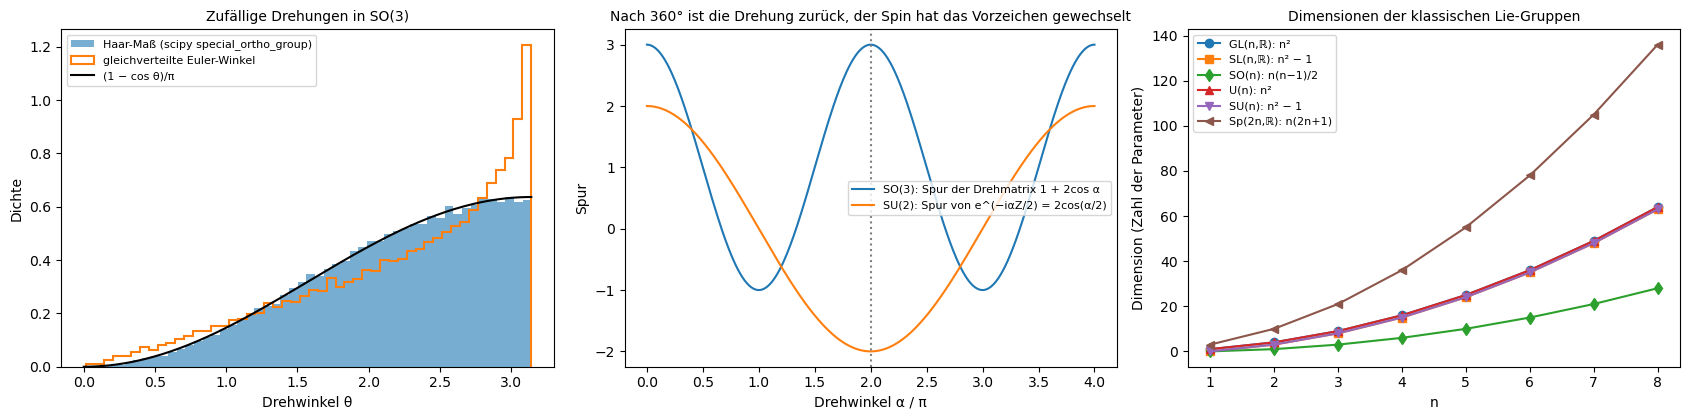

Mittlerer Drehwinkel: Haar 2.2044 (Theorie π/2 + 2/π = 2.2074), gleichverteilte Euler-Winkel 2.2347
Kolmogorov-Smirnov gegen (1 − cos θ)/π: Haar p = 0.15, Euler p = 3.7e-252
SU(2): Drehung um 2π ergibt [[-1.0, 0.0], [0.0, -1.0]] = −1, erst 4π ergibt +1;  Haar-zufällige SO(3)-Matrizen orthogonal mit Determinante 1: True


In [16]:
rng = np.random.default_rng(15)
haar = stats.special_ortho_group.rvs(3, size=50_000, random_state=rng)
haar_angles = Rotation.from_matrix(haar).magnitude()
euler = rng.uniform([0, 0, 0], [2 * np.pi, np.pi, 2 * np.pi], size=(50_000, 3))   # gleichverteilte Euler-Winkel: nicht gleichverteilt auf SO(3)
euler_angles = Rotation.from_euler("zyz", euler).magnitude()
th = np.linspace(0, np.pi, 200)
alpha = np.linspace(0, 4 * np.pi, 400)
dims = {"GL(n,ℝ): n²": lambda n: n * n, "SL(n,ℝ): n² − 1": lambda n: n * n - 1, "SO(n): n(n−1)/2": lambda n: n * (n - 1) // 2,
        "U(n): n²": lambda n: n * n, "SU(n): n² − 1": lambda n: n * n - 1, "Sp(2n,ℝ): n(2n+1)": lambda n: n * (2 * n + 1)}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
axes[0].hist(haar_angles, bins=50, density=True, alpha=0.6, label="Haar-Maß (scipy special_ortho_group)")
axes[0].hist(euler_angles, bins=50, density=True, histtype="step", lw=1.5, label="gleichverteilte Euler-Winkel")
axes[0].plot(th, (1 - np.cos(th)) / np.pi, "k-", label="(1 − cos θ)/π")
axes[0].set_xlabel("Drehwinkel θ")
axes[0].set_ylabel("Dichte")
axes[0].set_title("Zufällige Drehungen in SO(3)", fontsize=10)
axes[0].legend(fontsize=8)
axes[1].plot(alpha / np.pi, 1 + 2 * np.cos(alpha), label="SO(3): Spur der Drehmatrix 1 + 2cos α")
axes[1].plot(alpha / np.pi, 2 * np.cos(alpha / 2), label="SU(2): Spur von e^(−iαZ/2) = 2cos(α/2)")
axes[1].axvline(2, color="grey", ls=":")
axes[1].set_xlabel("Drehwinkel α / π")
axes[1].set_ylabel("Spur")
axes[1].set_title("Nach 360° ist die Drehung zurück, der Spin hat das Vorzeichen gewechselt", fontsize=10)
axes[1].legend(fontsize=8)
nd = np.arange(1, 9)
for (lab, f), mk in zip(dims.items(), "osd^v<"):
    axes[2].plot(nd, [f(int(k)) for k in nd], marker=mk, label=lab)
axes[2].set_xlabel("n")
axes[2].set_ylabel("Dimension (Zahl der Parameter)")
axes[2].set_title("Dimensionen der klassischen Lie-Gruppen", fontsize=10)
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

U2pi = np.diag([np.exp(-1j * np.pi), np.exp(1j * np.pi)])
print(f"Mittlerer Drehwinkel: Haar {haar_angles.mean():.4f} (Theorie π/2 + 2/π = {np.pi / 2 + 2 / np.pi:.4f}), gleichverteilte Euler-Winkel {euler_angles.mean():.4f}")
print(f"Kolmogorov-Smirnov gegen (1 − cos θ)/π: Haar p = {stats.kstest(haar_angles, lambda t: (t - np.sin(t)) / np.pi).pvalue:.2f}, Euler p = {stats.kstest(euler_angles, lambda t: (t - np.sin(t)) / np.pi).pvalue:.1e}")
print(f"SU(2): Drehung um 2π ergibt {np.round(np.real(U2pi), 6).tolist()} = −1, erst 4π ergibt +1;  Haar-zufällige SO(3)-Matrizen orthogonal mit Determinante 1: "
      f"{np.allclose(haar[0] @ haar[0].T, np.eye(3)) and np.isclose(np.linalg.det(haar[0]), 1)}")

* Im **linken Bild** folgt das Histogramm der Haar-zufälligen Drehungen der Dichte $(1 - \cos\theta)/\pi$: Drehungen um fast 180° sind am häufigsten, Drehungen um kleine Winkel selten. Das beantwortet die Vorhersage. Laut **Ausgabe** ist der mittlere Winkel 2.2044 (Theorie 2.2074), und der Kolmogorov-Smirnov-Test findet keine Abweichung ($p = 0.15$). Die naive Methode mit gleichverteilten Euler-Winkeln (orange) weicht deutlich ab, mit einer Spitze bei 180°; der Test verwirft sie mit $p\approx10^{-252}$.
* Im **mittleren Bild** hat die Spur der Drehmatrix in $SO(3)$ (blau) die Periode $2\pi$: Nach einer vollen Drehung ist alles wie vorher. Die Spur der $SU(2)$-Matrix (orange) hat die Periode $4\pi$ und ist bei $\alpha = 2\pi$ gleich $-2$; laut Ausgabe ist die Matrix dort $-1$. Im **rechten Bild** wachsen die Dimensionen quadratisch; $SO(n)$ hat am wenigsten Parameter, $Sp(2n)$ am meisten.
* **Wo es vorkommt:** **Zufällige Drehungen** braucht man für Datenaugmentation von 3D-Daten, Monte-Carlo-Integration über Orientierungen (Kristallographie, Kryo-Elektronenmikroskopie), zufällige Quantenschaltkreise (Haar-zufällige unitäre Matrizen und ihre Näherungen, Designs) und Tests der Rotationsinvarianz äquivarianter Netze. Die **Doppelüberlagerung** $SU(2)\to SO(3)$ steckt in der Beschreibung jedes Spins, in Quaternionen für Orientierungen in Grafik und Raumfahrt (Einheitsquaternionen sind $SU(2)$, und $q$ und $-q$ geben dieselbe Drehung) und in der Physik der Fermionen. Lie-Gruppen allgemein sind die Symmetriegruppen der Physik (Noether, Standardmodell) und der Robotik ($SE(3)$).

#### **Ergebnis**

Beim Lauf vom 2026-10-27:

- **Verknüpfungstafeln:** $\mathbb Z_6$, $S_3$, $D_4$ und $Q_8$ erfüllen die Gruppenaxiome, ihre Tafeln sind lateinische Quadrate, nur die von $\mathbb Z_6$ ist symmetrisch.
- **Kleine Gruppen:** Die fünf Gruppen der Ordnung 8 und die fünf der Ordnung 12 unterscheiden sich in ihren Elementordnungen; Zentrum, Kommutatoruntergruppe und Klassenzahl allein trennen $D_4$ und $Q_8$ (sowie $D_6$ und $\mathrm{Dic}_3$) nicht.
- **Anzahlen:** Ordnung $p$ gibt eine Gruppe, $p^2$ zwei, $pq$ eine oder zwei (bestätigt für alle 38 Fälle bis 130); 2328 der 3602 Gruppen bis Ordnung 130 haben Ordnung 128, bei 1024 sind es 49 487 367 289.
- **Untergruppen:** $S_4$ hat 30 Untergruppen, davon 4 Normalteiler; $A_4$ hat keine Untergruppe der Ordnung 6.
- **Burnside:** 13 Chlorbenzole (1, 1, 3, 3, 3, 1, 1), 10 Würfelfärbungen mit 2 Farben, 57 mit 3; Durchzählen und Formel stimmen überein.
- **Permutationen:** Anteil fixpunktfreier Permutationen 0.3685 (Theorie $1/e$), mittlere Zyklenzahl $H_n$, längster Zyklus etwa $0.63\,n$; das 15-Puzzle mit vertauschten 14 und 15 ist ungerade und unlösbar.
- **Zauberwürfel:** $\vert G\vert = 43\,252\,003\,274\,489\,856\,000$; $FR$ hat Ordnung 105, die größte Ordnung ist 1260; drei Seiten an einer Ecke erzeugen nur eine Untergruppe vom Index 253 440.
- **Einheitengruppen:** 114 von 299 Einheitengruppen modulo $n\leq300$ sind zyklisch, genau nach Gauß' Kriterium; modulo 101 gibt es 40 Primitivwurzeln.
- **Einfache Gruppen:** $A_5$, $A_6$, $PSL(2,7)$, $M_{11}$, $M_{12}$ sind einfach, $S_4$ ist auflösbar, $S_5$ nicht; unter 30 000 Elementen gibt es 23 nichtabelsche einfache Gruppen.
- **Sporadische Gruppen:** Die fünf Mathieu-Gruppen haben aus ihren Erzeugern die richtigen Ordnungen, $M_{12}$ und $M_{24}$ sind 5-fach transitiv; der Golay-Code hat die Gewichte 0, 8, 12, 16, 24 mit 1, 759, 2576, 759, 1 Wörtern und wird von $M_{24}$ erhalten.
- **Moonshine:** Die ersten vier Koeffizienten der $j$-Funktion zerlegen sich in Dimensionen von Monster-Darstellungen; die Primteiler von $\vert M\vert$ sind die 15 supersingulären Primzahlen.
- **Moleküle:** $H_2O$ $C_{2v}$ (4), $H_2O_2$ $C_2$ (2, chiral), $NH_3$ $C_{3v}$ (6), Ethan $D_{3d}$ (12), $CH_4$ $T_d$ (24), Benzol $D_{6h}$ (24), $SF_6$ $O_h$ (48), $C_{60}$ $I_h$ (120); der Cayley-Graph von $A_5$ ist das $C_{60}$-Gerüst.
- **Kristalle:** Nur Drehungen der Ordnung 1, 2, 3, 4, 6 sind mit einem Gitter verträglich.
- **Quanteninformation:** Pauli-Gruppe 16 Elemente, Clifford-Gruppe ohne Phase 24, mit den Klassengrößen 1, 8, 6, 3, 6 der Oktaedergruppe $S_4$.
- **Lie-Gruppen:** Haar-zufällige Drehungen haben die Winkeldichte $(1 - \cos\theta)/\pi$ (mittlerer Winkel 2.204 gegen 2.207), gleichverteilte Euler-Winkel nicht; in $SU(2)$ ist die Drehung um $2\pi$ gleich $-1$.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und prüfen:

1. **Untergruppen von $A_5$:** Bestimme in Experiment 4 alle Untergruppen von $A_5$ statt $S_4$. *(Vorhersage: 59 Untergruppen mit den Ordnungen 1, 2, 3, 4, 5, 6, 10, 12, 60; keine der Ordnungen 15, 20 oder 30, und als einfache Gruppe hat $A_5$ keinen echten Normalteiler. Getestet: 59 Untergruppen, Ordnungen wie vorhergesagt.)*
2. **Dichlornaphthaline:** Zähle in Experiment 5 die Isomere von $C_{10}H_6Cl_2$. Naphthalin hat 8 Wasserstoffpositionen, und die Symmetrien, die sie vertauschen, sind die Identität, zwei Spiegelungen und eine Drehung um 180°. *(Vorhersage nach Burnside: $(28 + 4 + 4 + 4)/4 = 10$. Getestet: 10.)*
3. **Der kleine Würfel:** Berechne in Experiment 7 die Ordnung von `RubikGroup(2)`. *(Vorhersage: Bei festgehaltener Lage einer Ecke lassen sich die übrigen sieben beliebig vertauschen und sechs davon frei drehen: $7!\cdot3^6 = 3\,674\,160$. Getestet: 3 674 160.)*
4. **Einheitengruppen vom Exponenten 2:** Suche in Experiment 8 alle $n\leq300$ mit $\lambda(n)\leq2$, für die also $a^2\equiv1$ für jede Einheit gilt. *(Vorhersage: genau die Teiler von 24 außer 1: 2, 3, 4, 6, 8, 12, 24. Getestet: genau diese.)*
5. **$M_{11}$:** Prüfe die Transitivität von $M_{11}$ auf seinen 11 Punkten. *(Vorhersage: scharf 4-fach transitiv, denn $11\cdot10\cdot9\cdot8 = 7920 = \vert M_{11}\vert$. Getestet: 4-fach transitiv.)*
6. **Mehr Moleküle:** Ergänze in Experiment 12 Allen ($H_2C{=}C{=}CH_2$, die beiden $CH_2$-Ebenen stehen senkrecht), Ethen und Ferrocen in ekliptischer Form. *(Vorhersage: Allen $D_{2d}$ mit 8 Operationen und einer vierzähligen Drehspiegelachse, Ethen $D_{2h}$ (8), Ferrocen $D_{5h}$ (20). Getestet: genau diese.)*
7. **Zwei Qubits:** Erzeuge die Clifford-Gruppe auf zwei Qubits aus $H\otimes I$, $I\otimes H$, $S\otimes I$, $I\otimes S$ und CNOT (ohne globale Phase). *(Vorhersage: $2^8\cdot3\cdot15 = 11\,520$ Elemente. Getestet: 11 520, in unter einer Sekunde.)*
8. **Fünfzählige Symmetrie:** Drehe in Experiment 13 die Basisvektoren des Quadrat- und des Sechseckgitters um 72° und schreibe die Bilder in Gitterkoordinaten. *(Vorhersage: Die Koordinaten sind nicht ganzzahlig, etwa $(\cos72°, \sin72°) = (0.309, 0.951)$ im Quadratgitter; eine Tapete mit fünfzähliger Drehung überdeckt sich nicht periodisch.)*
9. **Euler-Winkel richtig gewichten:** Ziehe in Experiment 15 $\alpha$ und $\gamma$ gleichverteilt, aber $\cos\beta$ statt $\beta$ gleichverteilt. *(Vorhersage: Jetzt stimmt die Verteilung mit dem Haar-Maß überein. Getestet: Kolmogorov-Smirnov $p = 0.29$.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Welche vier Eigenschaften machen eine Menge mit Verknüpfung zur Gruppe?</summary>

Abgeschlossenheit, Assoziativität, ein neutrales Element und zu jedem Element ein inverses. Kommutativität gehört nicht dazu; gilt sie, heißt die Gruppe abelsch.
</details>

<details><summary>2. Warum ist jede Zeile einer Verknüpfungstafel eine Permutation der Gruppe?</summary>

Aus $ab = ac$ folgt durch Multiplikation mit $a^{-1}$ von links $b = c$. Also kommt in jeder Zeile jedes Element höchstens und damit genau einmal vor. Das ist der Satz von Cayley: Jede Gruppe ist eine Gruppe von Permutationen.
</details>

<details><summary>3. Wie unterscheidet man D₄ und Q₈, die beide nichtabelsch mit 8 Elementen sind?</summary>

Über die Elementordnungen: $D_4$ hat fünf Elemente der Ordnung 2 (vier Spiegelungen und die Drehung um 180°), $Q_8$ nur eines ($-1$) und sechs der Ordnung 4. Zentrum, Kommutatoruntergruppe und Klassenzahl sind dagegen gleich.
</details>

<details><summary>4. Was sagt der Satz von Lagrange, und gilt seine Umkehrung?</summary>

Die Ordnung einer Untergruppe teilt die Gruppenordnung, ebenso die Ordnung jedes Elements. Die Umkehrung gilt nicht: $A_4$ hat 12 Elemente, aber keine Untergruppe mit 6. Für Primzahlpotenzen garantieren die Sylow-Sätze dagegen Untergruppen.
</details>

<details><summary>5. Was ist ein Normalteiler, und wozu braucht man ihn?</summary>

Eine Untergruppe $N$ mit $gNg^{-1} = N$ für alle $g$. Nur dann bilden die Nebenklassen eine Gruppe, die Faktorgruppe $G/N$. Kerne von Homomorphismen sind immer Normalteiler.
</details>

<details><summary>6. Warum gibt es zu jeder Primzahl p nur eine Gruppe mit p Elementen?</summary>

Nach Lagrange hat jedes Element außer dem neutralen die Ordnung $p$, erzeugt also die ganze Gruppe; sie ist zyklisch, $\mathbb Z_p$.
</details>

<details><summary>7. Was besagt das Lemma von Burnside, und wie viele Dichlorbenzole gibt es?</summary>

Die Zahl der Bahnen ist die mittlere Zahl der Fixpunkte, $\frac1{\vert G\vert}\sum_g\vert\mathrm{Fix}(g)\vert$. Für Dichlorbenzol mit der Gruppe $D_6$: drei (ortho, meta, para).
</details>

<details><summary>8. Warum entsprechen die Konjugationsklassen von Sₙ den Partitionen von n?</summary>

Konjugieren benennt nur die Elemente um und erhält die Zyklenlängen; zwei Permutationen mit gleichen Zyklenlängen lassen sich ineinander umbenennen. Die Klasse ist also durch die Liste der Zyklenlängen bestimmt, eine Partition von $n$.
</details>

<details><summary>9. Warum ist das 15-Puzzle mit vertauschten Steinen 14 und 15 unlösbar?</summary>

Jeder Zug ist eine Vertauschung mit dem Leerfeld. Kehrt das Leerfeld an seinen Platz zurück, war die Zahl der Züge gerade, also ist die Permutation der Steine gerade. Die Vertauschung von 14 und 15 ist ungerade.
</details>

<details><summary>10. Wie groß ist die Würfelgruppe, und warum ist ein zufällig zusammengesetzter Würfel nur in einem von zwölf Fällen lösbar?</summary>

Etwa $4.3\cdot10^{19}$ Elemente. Ecken- und Kantenvertauschung haben dasselbe Vorzeichen, die Eckdrehungen summieren sich zu einem Vielfachen von 3, die Kantenkippungen zu einer geraden Zahl; diese drei Bedingungen schneiden den Faktor $2\cdot3\cdot2 = 12$ ab.
</details>

<details><summary>11. Wann ist die Einheitengruppe modulo n zyklisch, und wozu braucht man das?</summary>

Genau für $n = 1, 2, 4, p^k, 2p^k$ ($p$ ungerade Primzahl, Gauß). Dann gibt es eine Primitivwurzel, und jede Einheit ist eine ihrer Potenzen; darauf beruhen Diffie-Hellman und der diskrete Logarithmus.
</details>

<details><summary>12. Was ist eine einfache Gruppe, und warum heißen sie die Atome der Gruppentheorie?</summary>

Eine Gruppe ohne Normalteiler außer der trivialen und sich selbst. Nach Jordan-Hölder lässt sich jede endliche Gruppe in einfache Faktoren zerlegen, die bis auf die Reihenfolge eindeutig sind, wie Primfaktoren einer Zahl.
</details>

<details><summary>13. Welche vier Kategorien endlicher einfacher Gruppen gibt es?</summary>

Zyklische Gruppen von Primzahlordnung, alternierende Gruppen $A_n$ mit $n\geq5$, Gruppen vom Lie-Typ (16 Familien von Matrixgruppen über endlichen Körpern) und die 26 sporadischen Gruppen.
</details>

<details><summary>14. Warum hat die allgemeine Gleichung fünften Grades keine Lösungsformel?</summary>

Ihre Galois-Gruppe ist $S_5$, und $S_5$ ist nicht auflösbar: Sie enthält die nichtabelsche einfache Gruppe $A_5$ als Kompositionsfaktor. Eine Gleichung ist genau dann durch Wurzeln lösbar, wenn ihre Galois-Gruppe auflösbar ist.
</details>

<details><summary>15. Was haben die Mathieu-Gruppe M₂₄ und der Golay-Code miteinander zu tun?</summary>

$M_{24}$ ist die Automorphismengruppe des erweiterten binären Golay-Codes: Genau die Permutationen der 24 Positionen, die Codewörter auf Codewörter abbilden, bilden $M_{24}$. Der Code hat 4096 Wörter, Mindestabstand 8 und korrigiert 3 Fehler.
</details>

<details><summary>16. Was ist Monstrous Moonshine?</summary>

Die Beobachtung, dass die Koeffizienten der $j$-Funktion Summen von Dimensionen irreduzibler Darstellungen des Monsters sind, etwa $196\,884 = 1 + 196\,883$. Dahinter steckt ein unendlichdimensionaler Raum mit Monster-Symmetrie aus der konformen Feldtheorie; Borcherds bewies die Vermutung 1992.
</details>

<details><summary>17. Woran erkennt man an der Punktgruppe, ob ein Molekül chiral oder polar ist?</summary>

Chiral, wenn die Punktgruppe nur Drehungen enthält (keine Spiegelung, keine Inversion, keine Drehspiegelung). Polar nur, wenn die Punktgruppe einen Vektor festlässt: $C_n$, $C_{nv}$ oder $C_s$.
</details>

<details><summary>18. Warum gibt es keine Kristalle mit fünfzähliger Drehachse?</summary>

Eine Drehung, die ein Gitter erhält, hat in der Gitterbasis eine ganzzahlige Matrix, also eine ganzzahlige Spur $2\cos(2\pi/n)$ (in der Ebene). Das geht nur für $n = 1, 2, 3, 4, 6$; Quasikristalle mit fünf- oder zehnzähliger Symmetrie sind nicht periodisch.
</details>

<details><summary>19. Warum hat die Clifford-Gruppe eines Qubits ohne Phase genau 24 Elemente?</summary>

Clifford-Gatter bilden Pauli-Operatoren auf Pauli-Operatoren ab, drehen die Bloch-Kugel also so, dass die sechs Achsen $\pm X, \pm Y, \pm Z$ untereinander vertauscht werden. Das sind die 24 Drehungen des Oktaeders, die Gruppe $S_4$.
</details>

<details><summary>20. Warum muss man einen Spin zweimal herumdrehen, bis er wieder gleich ist?</summary>

Spins transformieren mit $SU(2)$, das $SO(3)$ doppelt überlagert: $U$ und $-U$ geben dieselbe Drehung. Die Drehung um $2\pi$ ist in $SU(2)$ die Matrix $-1$, erst $4\pi$ ergibt $+1$.
</details>

<details><summary>21. Wie zieht man eine gleichverteilte zufällige Drehung, und welche Winkel sind dann häufig?</summary>

Mit dem Haar-Maß, etwa über die QR-Zerlegung einer Matrix mit normalverteilten Einträgen oder mit Euler-Winkeln, bei denen $\cos\beta$ gleichverteilt ist. Der Drehwinkel hat die Dichte $(1 - \cos\theta)/\pi$; große Winkel sind häufiger als kleine.
</details>

#### **Nächste Schritte**

- **Darstellungstheorie und Lie-Algebren:** Charaktertafeln, Auswahlregeln der Spektroskopie, die Lie-Algebra einer Lie-Gruppe, die Exponentialabbildung und die Darstellungen von $SU(2)$ und $SU(3)$.
- **Ringe und Körper:** endliche Körper, über denen die Gruppen vom Lie-Typ leben, und die Galois-Theorie, die Gruppen und Gleichungen verbindet.
- **Raumgruppen in drei Dimensionen:** die 230 Raumgruppen mit spglib an echten Kristallstrukturen bestimmen.
- **Zopfgruppen und Anyonen:** wie Vertauschungen in zwei Dimensionen zu topologischen Quantengattern werden.
- **Äquivariante neuronale Netze:** Faltungen auf Gruppen, $SO(3)$-äquivariante Netze für Moleküle und Permutationsäquivarianz in Graphennetzen.
- **Computer-Gruppentheorie:** GAP und die SmallGroups-Bibliothek, Schreier-Sims und das Lösen des Zauberwürfels über Untergruppenketten.

#### **Referenzen**

- Armstrong, M. A. (1988): *Groups and Symmetry*, Springer.
- Dummit, D. S. & Foote, R. M. (2004): *Abstract Algebra*, 3rd ed., Wiley.
- Rotman, J. J. (1995): *An Introduction to the Theory of Groups*, 4th ed., Springer.
- Wilson, R. A. (2009): *The Finite Simple Groups*, Springer.
- Conway, J. H., Curtis, R. T., Norton, S. P., Parker, R. A. & Wilson, R. A. (1985): *ATLAS of Finite Groups*, Oxford University Press.
- Ronan, M. (2006): *Symmetry and the Monster*, Oxford University Press.
- Conway, J. H. & Sloane, N. J. A. (1999): *Sphere Packings, Lattices and Groups*, 3rd ed., Springer.
- Gannon, T. (2006): *Moonshine beyond the Monster*, Cambridge University Press.
- Cotton, F. A. (1990): *Chemical Applications of Group Theory*, 3rd ed., Wiley.
- Joyner, D. (2008): *Adventures in Group Theory: Rubik's Cube, Merlin's Machine, and Other Mathematical Toys*, 2nd ed., Johns Hopkins University Press.
- Besche, H. U., Eick, B. & O'Brien, E. A. (2002): *A millennium project: constructing small groups*, International Journal of Algebra and Computation 12, 623.
- Rokicki, T., Kociemba, H., Davidson, M. & Dethridge, J. (2013): *The diameter of the Rubik's Cube group is twenty*, SIAM Journal on Discrete Mathematics 27, 1082.
- Gottesman, D. (1998): *The Heisenberg representation of quantum computers*, arXiv:quant-ph/9807006.
- Bronstein, M. M., Bruna, J., Cohen, T. & Veličković, P. (2021): *Geometric Deep Learning: Grids, Groups, Graphs, Geodesics, and Gauges*, arXiv:2104.13478.
- OEIS Foundation: *A000001, Number of groups of order n*, https://oeis.org/A000001.